In [1]:
   from google.colab import drive
   drive.mount('/content/drive')

Mounted at /content/drive


Python      : 3.13.16
PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130
Device: cuda
GPU   : Tesla T4
{
  "seed": 42,
  "data_dir": "./data",
  "img_size": 28,
  "img_channels": 1,
  "num_classes": 10,
  "norm_mean": 0.5,
  "norm_std": 0.5,
  "batch_size": 128,
  "num_workers": 2,
  "train_size": 60000,
  "z_dim": 100,
  "g_embed_dim": 50,
  "g_channels": [
    128,
    64,
    32
  ],
  "d_channels": [
    64,
    128,
    256
  ],
  "leaky_slope": 0.2,
  "init_std": 0.02,
  "d_dropout": 0.0,
  "d_spectral_norm": false,
  "epochs": 50,
  "lr_g": 0.0002,
  "lr_d": 0.0002,
  "beta1": 0.5,
  "beta2": 0.999,
  "weight_decay": 0.0,
  "d_steps": 1,
  "g_steps": 1,
  "real_target": 0.9,
  "fake_target": 0.0,
  "g_target": 1.0,
  "sample_every": 5,
  "ckpt_every": 10,
  "n_per_class_grid": 10,
  "eval_per_class": 1000,
  "use_drive": true,
  "drive_root": "/content/drive/MyDrive/cgan_fashion_mnist",
  "local_root": "./outputs",
  "out_root": "",
  "ckpt_dir": "",
  "sample_dir": "",
  "lo

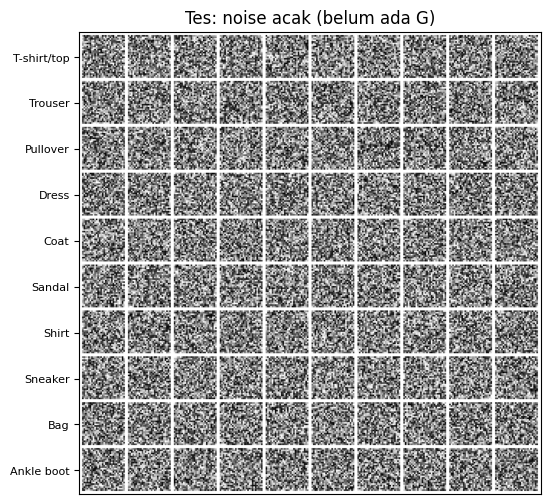

TES 1.2 LULUS
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder keluaran : /content/drive/MyDrive/cgan_fashion_mnist
  checkpoints   : /content/drive/MyDrive/cgan_fashion_mnist/checkpoints
  samples       : /content/drive/MyDrive/cgan_fashion_mnist/samples
  logs          : /content/drive/MyDrive/cgan_fashion_mnist/logs
TES 1.3 LULUS
TES 1.4 LULUS
Generator(
  (embed): Embedding(10, 50)
  (project): Linear(in_features=150, out_features=6272, bias=False)
  (bn0): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act0): ReLU()
  (up): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e

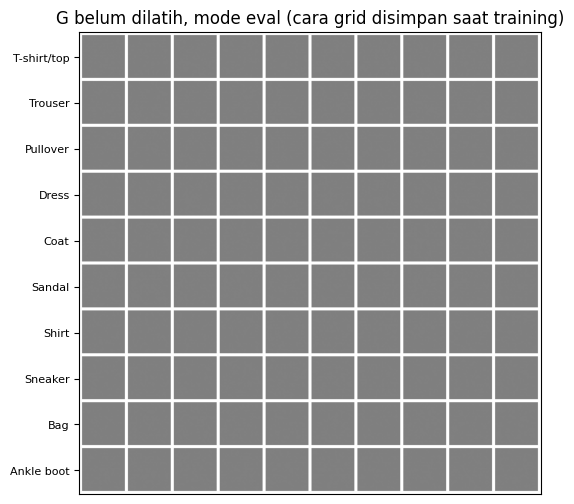

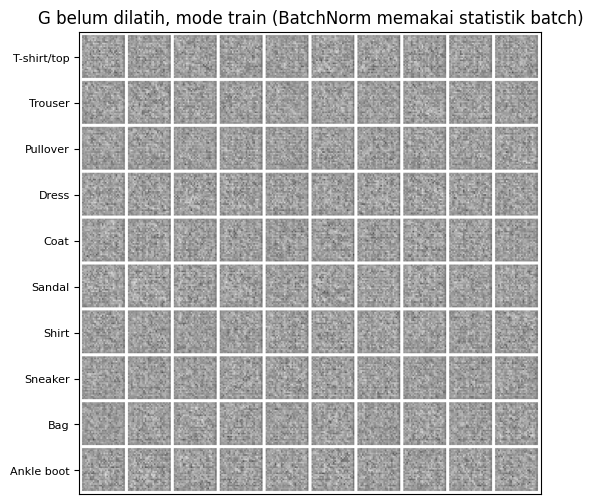

TES 2.5 LULUS
TES 2.6 LULUS


In [2]:
!git clone -q https://github.com/sridewisnn/GEN_AI.git
%run GEN_AI/cGAN_FashionMNIST.ipynb

# Bagian 3: Dataset

## 3.1 Konsep: `get_dataloader`

Bagian ini menyuplai gambar asli ke Discriminator dan ke classifier pendamping.
Kontraknya (cetak biru hlm. 2): `get_dataloader(batch_size)` menghasilkan
`img` [B, 1, 28, 28] float32 di [-1, 1] dan `label` [B] int64 di 0..9.

**Keputusan desain**

| Keputusan | Alasan |
| --- | --- |
| `ToTensor()` lalu `Normalize(CFG.norm_mean, CFG.norm_std)` | G berakhir dengan Tanh, jadi rentangnya [-1, 1]. Gambar asli harus berada di skala yang sama. Kalau tidak, D bisa membedakan asli dan buatan hanya dari skalanya. Nilainya diambil dari CFG, sehingga `denormalize()` selalu menjadi kebalikannya. |
| Tanpa augmentasi | Augmentasi mengubah distribusi yang ingin ditiru G. |
| Train: `shuffle=True`, `drop_last=True` | 60.000 / 128 = 468 sisa 96. Batch sisa dibuang supaya statistik BatchNorm tidak dihitung dari batch kecil. |
| Test (`train=False`): `shuffle=False`, `drop_last=False` | Hanya untuk classifier pendamping. Akurasi harus dihitung dari seluruh 10.000 gambar, dan urutan tidak berpengaruh. |
| `torch.Generator` berseed khusus untuk shuffle | Urutan batch sama di setiap run dan tidak terganggu oleh `torch.randn` di sel lain, tetapi tetap berbeda antar-epoch. |
| `pin_memory = (DEVICE.type == "cuda")` | Mempercepat transfer ke GPU. Di CPU tidak ada gunanya dan hanya memunculkan peringatan. |
| `persistent_workers=True` | Dua worker tidak dimatikan dan dihidupkan lagi di setiap epoch (50 kali). |

Label dibiarkan berupa indeks int64, bukan one-hot, karena `nn.Embedding` di G dan D
menerima indeks kelas secara langsung.

In [3]:
# Import tambahan Bagian 3-4 (tidak ada di cell import Bagian 0).
import math
from torchvision import transforms
from torch.utils.data import DataLoader


def build_transform() -> transforms.Compose:
    """PIL uint8 [0, 255] -> tensor float32 [1, 28, 28] di rentang [-1, 1]."""
    return transforms.Compose([
        # ToTensor: PIL [H, W] uint8 -> [C, H, W] float32, dibagi 255 -> rentang [0, 1].
        transforms.ToTensor(),
        # (x - 0.5) / 0.5 -> rentang [-1, 1], sama dengan rentang keluaran Tanh di G.
        # Nilai diambil dari CFG agar denormalize() di Bagian 1 selalu menjadi kebalikannya.
        transforms.Normalize((CFG.norm_mean,), (CFG.norm_std,)),
    ])


def get_dataset(train: bool = True) -> torchvision.datasets.FashionMNIST:
    """Dataset FashionMNIST (train 60.000 / test 10.000). Unduhan dilewati bila file sudah ada."""
    # download=True aman dijalankan ulang: torchvision memeriksa file di CFG.data_dir lebih dulu.
    return torchvision.datasets.FashionMNIST(
        root=CFG.data_dir, train=train, download=True, transform=build_transform())


def get_dataloader(batch_size: int, train: bool = True) -> DataLoader:
    """Kontrak Bagian 3: setiap batch = (img [B,1,28,28] float32 di [-1,1], label [B] int64 di 0..9).

    train=True : split train, diacak, batch terakhir yang tidak penuh dibuang (untuk GAN).
    train=False: split test, urutan tetap, semua gambar ikut (untuk evaluasi classifier pendamping).
    """
    if not isinstance(batch_size, int) or batch_size <= 0:
        raise ValueError(f"batch_size harus bilangan bulat > 0, diterima {batch_size!r}")

    dataset = get_dataset(train)

    # Generator terpisah untuk shuffle: urutan batch sama di setiap run (reproducible),
    # tetapi tetap berbeda antar-epoch karena generator ini maju setiap kali loader diiterasi.
    # Tidak bergantung pada RNG global, jadi tidak terganggu oleh pemanggilan torch.randn di cell lain.
    shuffle_gen = torch.Generator().manual_seed(CFG.seed) if train else None

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=train,                 # test tidak perlu diacak: akurasi tidak bergantung urutan
        drop_last=train,               # train: batch sisa 96 gambar dibuang agar BatchNorm stabil
        num_workers=CFG.num_workers,   # Colab punya 2 CPU
        # pin_memory hanya berguna (dan hanya didukung tanpa peringatan) bila ada GPU.
        pin_memory=(DEVICE.type == "cuda"),
        # Worker dipertahankan antar-epoch: menghemat waktu start ulang 2 proses di setiap epoch.
        persistent_workers=CFG.num_workers > 0,
        generator=shuffle_gen,
    )


train_loader = get_dataloader(CFG.batch_size, train=True)
test_loader = get_dataloader(CFG.batch_size, train=False)
print(f"train: {len(train_loader.dataset):,} gambar -> {len(train_loader)} batch/epoch")
print(f"test : {len(test_loader.dataset):,} gambar -> {len(test_loader)} batch")

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.61MB/s]

train: 60,000 gambar -> 468 batch/epoch
test : 10,000 gambar -> 79 batch


### Tes 3.1

Memeriksa kontrak antarmuka (bentuk, tipe, rentang), kebenaran rumus normalisasi terhadap
data mentah, keseimbangan kelas, pengaturan loader, reproducibility shuffle,
kelengkapan split test, dan kecocokan bentuk dengan keluaran Generator.

In [4]:
B = CFG.batch_size
img_shape = (CFG.img_channels, CFG.img_size, CFG.img_size)
RANGE_TOL = 1e-6   # toleransi pembulatan float32: piksel 0 dan 255 harus jatuh tepat di -1 dan 1

# --- Tes 3.1a: ukuran dataset dan jumlah batch ---
assert len(train_loader.dataset) == CFG.train_size, f"train berisi {len(train_loader.dataset)}, seharusnya {CFG.train_size}"
assert len(train_loader) == CFG.iters_per_epoch, f"{len(train_loader)} batch/epoch, seharusnya {CFG.iters_per_epoch}"
n_test = len(test_loader.dataset)
assert len(test_loader) == math.ceil(n_test / B), "test tidak boleh membuang batch terakhir"

# --- Tes 3.1b: kontrak bentuk dan tipe satu batch train ---
img, label = next(iter(train_loader))
assert img.shape == (B, *img_shape), f"img {tuple(img.shape)}, seharusnya {(B, *img_shape)}"
assert img.dtype == torch.float32, f"img bertipe {img.dtype}, seharusnya float32"
assert label.shape == (B,), f"label {tuple(label.shape)}, seharusnya ({B},) (bukan one-hot)"
assert label.dtype == torch.int64, f"label bertipe {label.dtype}, seharusnya int64 (wajib untuk nn.Embedding)"
assert 0 <= label.min() and label.max() < CFG.num_classes, f"label di luar 0..{CFG.num_classes - 1}"

# --- Tes 3.1c: rentang [-1, 1], dan kedua ujung benar-benar muncul ---
print(f"rentang batch: [{img.min():.4f}, {img.max():.4f}]")
assert img.min() >= -1 - RANGE_TOL and img.max() <= 1 + RANGE_TOL, "img di luar [-1, 1]"
assert img.min() <= -1 + RANGE_TOL, "tidak ada piksel bernilai -1: normalisasi bergeser (cek mean/std)"
assert img.max() >= 1 - RANGE_TOL, "tidak ada piksel bernilai 1: normalisasi menyempit (cek ToTensor)"

# --- Tes 3.1d: transform persis (x/255 - mean)/std terhadap data mentah ---
ds = train_loader.dataset
for idx in (0, len(ds) - 1):
    raw = ds.data[idx].float() / 255.0                          # uint8 mentah [28, 28]
    expected_img = ((raw - CFG.norm_mean) / CFG.norm_std).unsqueeze(0)
    got_img, got_label = ds[idx]
    assert torch.allclose(got_img, expected_img, atol=RANGE_TOL), f"transform sampel {idx} tidak sesuai rumus"
    assert got_label == ds.targets[idx].item(), f"label sampel {idx} tidak cocok dengan targets"
    # denormalize (Bagian 1) harus mengembalikan gambar mentah: real dan fake memakai skala yang sama.
    assert torch.allclose(denormalize(got_img).squeeze(0), raw, atol=RANGE_TOL), "denormalize tidak membalik transform"

# --- Tes 3.1e: semua kelas ada dan seimbang (6.000 per kelas di train) ---
counts = torch.bincount(ds.targets, minlength=CFG.num_classes)
assert counts.numel() == CFG.num_classes, f"ada label >= {CFG.num_classes}"
assert (counts == CFG.train_size // CFG.num_classes).all(), f"jumlah per kelas tidak seimbang: {counts.tolist()}"

# --- Tes 3.1f: pengaturan loader sesuai cetak biru ---
assert train_loader.drop_last is True and test_loader.drop_last is False
assert isinstance(train_loader.sampler, torch.utils.data.RandomSampler), "train harus diacak"
assert isinstance(test_loader.sampler, torch.utils.data.SequentialSampler), "test tidak boleh diacak"
assert train_loader.num_workers == CFG.num_workers
assert train_loader.pin_memory == (DEVICE.type == "cuda")

# --- Tes 3.1g: shuffle reproducible antar-run, tetapi berbeda antar-epoch ---
_, label_run2 = next(iter(get_dataloader(B, train=True)))      # loader baru = "run baru"
assert torch.equal(label, label_run2), "dua loader baru harus memberi urutan batch yang sama (seed tetap)"
_, label_epoch2 = next(iter(train_loader))                     # iterasi kedua dari loader yang sama = epoch 2
assert not torch.equal(label, label_epoch2), "urutan epoch 2 harus berbeda dari epoch 1"

# --- Tes 3.1h: split test berurutan dan tidak kehilangan gambar ---
_, label_test = next(iter(test_loader))
assert torch.equal(label_test, test_loader.dataset.targets[:B]), "test harus berurutan (shuffle=False)"
total = sum(lbl.numel() for _, lbl in test_loader)
assert total == n_test, f"test loader menyajikan {total} gambar, seharusnya {n_test}"

# --- Tes 3.1i: batch langsung cocok dengan Generator (kontrak lintas bagian) ---
G.eval()
with torch.no_grad():
    fake = G(torch.randn(B, CFG.z_dim, device=DEVICE), label.to(DEVICE))
assert fake.shape == img.shape, f"G menghasilkan {tuple(fake.shape)}, data real {tuple(img.shape)}: D akan menerima dua bentuk berbeda"

# --- Tes 3.1j: input tidak sah ditolak ---
for bad in (0, -1, 12.5):
    try:
        get_dataloader(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"get_dataloader({bad!r}) seharusnya memunculkan ValueError")

print("TES 3.1 LULUS")

rentang batch: [-1.0000, 1.0000]
TES 3.1 LULUS


## 3.2 Konsep: pemeriksaan visual data

Tes 3.1 membuktikan bentuk, tipe, dan rentang. Tes itu tidak bisa membuktikan bahwa
**gambar dan labelnya berpasangan dengan benar**. Contohnya: gambar sepatu berlabel "Dress",
atau gambar yang terbalik atau terlalu gelap karena normalisasi salah. Hal seperti ini hanya
terlihat oleh mata, dan cetak biru (hlm. 4) mewajibkan pemeriksaan manualnya sebelum training.

**Keputusan desain**

| Keputusan | Alasan |
| --- | --- |
| Gambar diambil dari batch `train_loader`, bukan langsung dari dataset | Yang diperiksa adalah pasangan (gambar, label) yang benar-benar akan diterima D, termasuk efek shuffle. |
| Helper baru `show_labeled_images` dengan judul per gambar | `show_image_grid` (Bagian 1) hanya memberi label per baris. Di batch acak, setiap gambar punya kelas sendiri. Denormalisasinya tetap memakai `denormalize` dari Bagian 1. |
| `vmin=0, vmax=1` saat `imshow` | Tanpa ini matplotlib meregangkan kontras tiap gambar, sehingga gambar yang terlalu gelap atau terang (gejala bug normalisasi) justru tampak normal. |
| Grid acuan real 10×10 (baris ke-i = kelas ke-i) | Tata letaknya sama dengan grid sampel G (`make_fixed_noise`), sehingga `samples/epoch_XXX.png` bisa dibandingkan langsung dengan gambar asli. Isinya deterministik (10 gambar pertama tiap kelas), jadi grid ini sama di setiap run. |

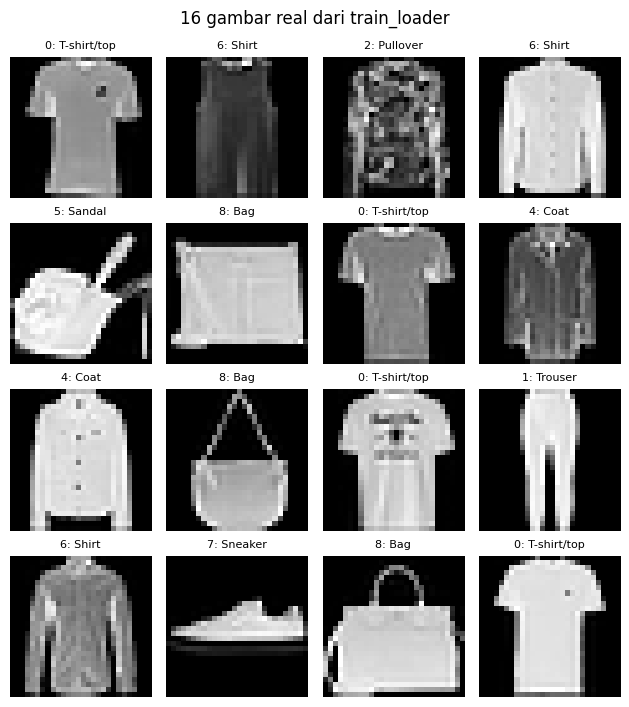

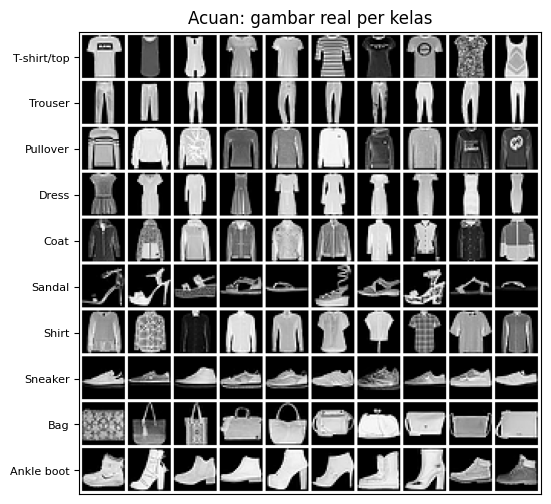

Grid acuan disimpan di: /content/drive/MyDrive/cgan_fashion_mnist/samples/real_reference.png


In [5]:
@dataclass
class PreviewConfig:
    """Pengaturan pemeriksaan visual data (Bagian 3.2). Terpisah dari CFG milik tim."""
    n: int = 16                                # cetak biru hlm. 4: grid 16 gambar real berlabel
    nrow: int = 4                              # 4 x 4: judul tiap gambar masih terbaca
    real_grid_name: str = "real_reference.png" # grid acuan 10 kelas x 10 sampel, disimpan di CFG.sample_dir

    def __post_init__(self):
        if self.n <= 0 or self.nrow <= 0 or self.n % self.nrow != 0:
            raise ValueError(f"n ({self.n}) harus > 0 dan habis dibagi nrow ({self.nrow}).")


PREVIEW_CFG = PreviewConfig()


def show_labeled_images(images: torch.Tensor, labels: torch.Tensor, nrow: int, title: str = None):
    """Tampilkan gambar [N,1,H,W] (rentang [-1,1]) dengan nama kelas di atas TIAP gambar.

    show_image_grid (Bagian 1) hanya bisa memberi label per baris, padahal di batch acak
    tiap gambar punya kelas sendiri. Fungsi ini melengkapinya dan memakai denormalize yang sama.
    Mengembalikan figure agar isinya bisa diperiksa oleh tes.
    """
    if images.size(0) != labels.size(0):
        raise ValueError(f"jumlah gambar ({images.size(0)}) dan label ({labels.size(0)}) berbeda")
    n = images.size(0)
    ncol = math.ceil(n / nrow)
    # detach + cpu: aman untuk tensor di GPU atau yang masih terhubung ke graph gradien.
    imgs01 = denormalize(images.detach().cpu().float())        # [-1,1] -> [0,1], sama seperti grid tim

    fig, axes = plt.subplots(nrow, ncol, figsize=(1.6 * ncol, 1.8 * nrow), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i >= n:
            continue                                           # sel kosong bila n bukan kelipatan
        c = int(labels[i])
        # vmin/vmax tetap: tanpa ini matplotlib meregangkan kontras tiap gambar dan
        # gambar yang terlalu gelap/terang (gejala bug normalisasi) tidak akan terlihat.
        ax.imshow(imgs01[i, 0].numpy(), cmap="gray", vmin=0.0, vmax=1.0)
        ax.set_title(f"{c}: {CLASS_NAMES[c]}", fontsize=8)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig


def real_reference_indices(dataset, n_per_class: int) -> torch.Tensor:
    """Indeks n_per_class gambar pertama tiap kelas, diurutkan kelas 0..9 (deterministik, tanpa acak)."""
    idx = [torch.nonzero(dataset.targets == c).flatten()[:n_per_class]
           for c in range(CFG.num_classes)]
    return torch.cat(idx)                                      # baris ke-c = kelas c, sama dengan make_fixed_noise


# --- (a) Wajib cetak biru: 16 gambar pertama dari batch train_loader, label di judul tiap gambar ---
# Diambil dari loader (bukan dari dataset langsung) agar yang diperiksa adalah pasangan
# (gambar, label) yang benar-benar akan diterima D saat training.
preview_img, preview_label = next(iter(train_loader))
preview_img, preview_label = preview_img[:PREVIEW_CFG.n], preview_label[:PREVIEW_CFG.n]
fig_preview = show_labeled_images(preview_img, preview_label, PREVIEW_CFG.nrow,
                                  title=f"{PREVIEW_CFG.n} gambar real dari train_loader")

# --- (b) Grid acuan real: tata letak sama dengan grid sampel G (baris ke-i = kelas ke-i) ---
# Dibandingkan berdampingan dengan samples/epoch_XXX.png saat evaluasi dan presentasi.
ref_ds = train_loader.dataset
ref_idx = real_reference_indices(ref_ds, CFG.n_per_class_grid)
ref_imgs = torch.stack([ref_ds[i][0] for i in ref_idx.tolist()])     # [100, 1, 28, 28] di [-1, 1]
ref_path = os.path.join(CFG.sample_dir, PREVIEW_CFG.real_grid_name)
ref_grid = save_image_grid(ref_imgs, ref_path)                       # menimpa file lama: aman dijalankan ulang
show_image_grid(ref_grid, "Acuan: gambar real per kelas", row_labels=CLASS_NAMES)
print("Grid acuan disimpan di:", ref_path)

### Tes 3.2

Bagian otomatis memastikan bahwa yang tampil adalah data yang benar: judul sesuai label,
piksel sesuai tensornya, skala warna tetap, grid acuan berurutan per kelas dan berukuran
sama dengan grid G. Penilaian akhir tetap **cek manual** dengan daftar di bawah sel tes.

In [6]:
GRID_PAD = 2   # padding yang dipakai save_image_grid di Bagian 1 (make_grid padding=2)
PIX_TOL = 1e-6

# --- Tes 3.2a: preview berisi n gambar, judul tiap gambar = nama kelas labelnya ---
shown = [ax for ax in fig_preview.axes if ax.images]
assert len(shown) == PREVIEW_CFG.n, f"{len(shown)} gambar tampil, seharusnya {PREVIEW_CFG.n}"
for i, ax in enumerate(shown):
    c = int(preview_label[i])
    assert ax.get_title() == f"{c}: {CLASS_NAMES[c]}", f"gambar {i}: judul '{ax.get_title()}' tidak sesuai label {c}"
    # Piksel yang tampil harus persis gambar ke-i setelah denormalize (urutan gambar-label tidak tertukar).
    shown_pix = torch.from_numpy(np.asarray(ax.images[0].get_array(), dtype=np.float32))
    assert torch.allclose(shown_pix, denormalize(preview_img[i, 0]), atol=PIX_TOL), f"gambar {i} tidak cocok dengan tensornya"
    assert ax.images[0].get_clim() == (0.0, 1.0), "skala warna harus tetap [0, 1] agar gambar gelap/terang terlihat apa adanya"

# --- Tes 3.2b: grid acuan, baris ke-c benar-benar kelas c ---
n_ref = CFG.num_classes * CFG.n_per_class_grid
assert ref_idx.numel() == n_ref, f"{ref_idx.numel()} indeks acuan, seharusnya {n_ref}"
ref_labels = ref_ds.targets[ref_idx]
expected_rows = torch.arange(CFG.num_classes).repeat_interleave(CFG.n_per_class_grid)
assert torch.equal(ref_labels, expected_rows), "urutan grid acuan harus baris ke-i = kelas ke-i (sama dengan make_fixed_noise)"
_, y_fixed_check = make_fixed_noise(device="cpu")
assert torch.equal(ref_labels, y_fixed_check), "tata letak grid acuan berbeda dengan grid sampel G"
assert ref_imgs.shape == (n_ref, CFG.img_channels, CFG.img_size, CFG.img_size), ref_imgs.shape
assert ref_imgs.min() >= -1 - PIX_TOL and ref_imgs.max() <= 1 + PIX_TOL

# --- Tes 3.2c: file grid acuan tersimpan dengan ukuran yang sama dengan grid sampel G ---
side = CFG.n_per_class_grid * (CFG.img_size + GRID_PAD) + GRID_PAD
assert os.path.isfile(ref_path), f"file tidak terbentuk: {ref_path}"
assert Image.open(ref_path).size == (side, side), f"ukuran {Image.open(ref_path).size}, seharusnya {(side, side)}"
assert ref_grid.shape == (3, side, side), ref_grid.shape

# --- Tes 3.2d: deterministik (dijalankan ulang memberi grid acuan yang sama) ---
assert torch.equal(real_reference_indices(ref_ds, CFG.n_per_class_grid), ref_idx), "indeks acuan harus tetap"

# --- Tes 3.2e: input tidak sah ditolak ---
try:
    show_labeled_images(preview_img[:4], preview_label[:3], nrow=2)
except ValueError:
    pass
else:
    raise AssertionError("jumlah gambar dan label berbeda seharusnya memunculkan ValueError")
try:
    PreviewConfig(n=16, nrow=5)
except ValueError:
    pass
else:
    raise AssertionError("PreviewConfig(n=16, nrow=5) seharusnya memunculkan ValueError")

plt.close("all")   # bebaskan figure agar menjalankan ulang tidak menumpuk memori
print("TES 3.2 LULUS  (lanjutkan dengan cek manual di bawah)")

TES 3.2 LULUS  (lanjutkan dengan cek manual di bawah)


# Bagian 4: Classifier pendamping + generate

## 4a Konsep: classifier pendamping

Classifier ini adalah **alat ukur independen** untuk Bagian 7. Pertanyaan yang dijawabnya:
"kalau G diminta membuat Sneaker, apakah hasilnya benar-benar dikenali sebagai Sneaker?"
Classifier tidak ikut dalam training GAN. Ia dilatih sekali pada Fashion-MNIST **asli**,
lalu dibekukan.

**Kontrak** (cetak biru hlm. 2): gambar [B, 1, 28, 28] di [-1, 1] → logit [B, 10].

| Keputusan | Alasan |
| --- | --- |
| CNN kecil 2 blok Conv-ReLU-MaxPool, `padding=1` | Resolusi 28 → 14 → 7, sama dengan pola G dan D. Flatten = 64·7·7 = 3136. Sekitar 0,42 juta parameter, cukup untuk sekitar 91% dan cepat di CPU. |
| Input dinormalisasi ke [-1, 1] lewat `get_dataloader` yang sama | Gambar buatan G juga berada di [-1, 1]. Classifier harus menilai keduanya di skala yang sama, kalau tidak akurasinya turun karena skala, bukan karena kualitas gambar. |
| Logit mentah + `CrossEntropyLoss` | Log-softmax sudah ada di dalam loss dan stabil secara numerik. |
| Adam lr 1e-3, beta default | Classifier punya target tetap. β1 = 0,5 hanya dibutuhkan GAN karena lawannya terus berubah. |
| Init default PyTorch, bukan `weights_init` | N(0; 0,02) adalah konvensi khusus GAN. Untuk classifier biasa, init Kaiming default sudah stabil. |
| `ClassifierConfig` terpisah dari `CFG` | `CFG` dikelola ketua. Semua angka classifier ada di satu tempat ini, dan path tetap diambil dari `CFG.ckpt_dir`. |
| Dibekukan (`eval()` + `requires_grad=False`) lalu disimpan ke Drive | Alat ukur tidak boleh berubah antar-pengukuran. Bobot di Drive bertahan antar-sesi, jadi training cukup sekali. |

In [7]:
import time
from tqdm.auto import tqdm   # progress bar dengan estimasi sisa waktu (bawaan Colab)


@dataclass
class ClassifierConfig:
    """Hyperparameter classifier pendamping (cetak biru hlm. 13). Terpisah dari CFG milik tim."""
    clf_epochs: int = 5
    clf_lr: float = 1e-3
    clf_channels: Tuple[int, ...] = (32, 64)   # kanal tiap blok Conv-ReLU-MaxPool: 28 -> 14 -> 7
    clf_hidden: int = 128                     # lebar layer tersembunyi sebelum logit
    clf_min_test_acc: float = 0.88            # ambang tes: sedikit di bawah ±91% agar tahan variasi antar-run
    clf_weights_name: str = "classifier.pt"   # TIDAK diawali "ckpt_epoch": latest_checkpoint() tim tidak tertukar

    def __post_init__(self):
        if self.clf_epochs <= 0 or self.clf_lr <= 0 or self.clf_hidden <= 0:
            raise ValueError("clf_epochs, clf_lr, dan clf_hidden harus > 0.")
        if not self.clf_channels or any(c <= 0 for c in self.clf_channels):
            raise ValueError("clf_channels harus berisi minimal satu bilangan > 0.")
        if CFG.img_size % (2 ** len(self.clf_channels)) != 0:
            raise ValueError(f"img_size ({CFG.img_size}) harus habis dibagi 2^{len(self.clf_channels)} "
                             "(setiap blok MaxPool membagi dua resolusi).")
        if not (0.0 < self.clf_min_test_acc <= 1.0):
            raise ValueError("clf_min_test_acc harus di rentang (0, 1].")
        if self.clf_weights_name.startswith("ckpt_epoch"):
            raise ValueError("clf_weights_name tidak boleh diawali 'ckpt_epoch' (bentrok dengan checkpoint GAN).")

    @property
    def weights_path(self) -> str:
        # Dihitung saat dipakai (bukan disimpan): selalu mengikuti CFG.ckpt_dir terbaru (Drive atau lokal).
        return os.path.join(CFG.ckpt_dir, self.clf_weights_name)

    @property
    def feat_size(self) -> int:
        return CFG.img_size // 2 ** len(self.clf_channels)          # 28 // 4 = 7

    @property
    def flat_dim(self) -> int:
        return self.clf_channels[-1] * self.feat_size ** 2          # 64 * 7 * 7 = 3136


CLF_CFG = ClassifierConfig()


class Classifier(nn.Module):
    """Classifier pendamping: gambar [B,1,28,28] di [-1,1] -> logit [B,10] (tanpa softmax).

    Alur (konfigurasi baseline):
      Conv(1->32, k3, p1) -> ReLU -> MaxPool(2)   [B, 32, 14, 14]
      Conv(32->64, k3, p1) -> ReLU -> MaxPool(2)  [B, 64,  7,  7]
      Flatten                                     [B, 3136]
      Linear(3136->128) -> ReLU                   [B, 128]
      Linear(128->10)                             [B, 10]  (logit)
    """

    def __init__(self):
        super().__init__()
        blocks, c_in = [], CFG.img_channels
        for c_out in CLF_CFG.clf_channels:
            # padding=1 dengan kernel 3: ukuran tetap, MaxPool yang membagi dua (28->14->7,
            # sama dengan pola G dan D). Piksel tepi tidak terbuang.
            blocks += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                       nn.ReLU(),
                       nn.MaxPool2d(kernel_size=2)]
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(CLF_CFG.flat_dim, CLF_CFG.clf_hidden),
            nn.ReLU(),
            # Logit mentah: CrossEntropyLoss sudah memuat log-softmax (stabil secara numerik).
            nn.Linear(CLF_CFG.clf_hidden, CFG.num_classes),
        )
        # Sengaja TIDAK memakai weights_init (N(0, 0.02)) milik GAN: itu konvensi khusus GAN.
        # Classifier biasa sudah stabil dengan init default PyTorch (Kaiming-uniform).

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        expected = (CFG.img_channels, CFG.img_size, CFG.img_size)
        if x.dim() != 4 or tuple(x.shape[1:]) != expected:
            raise ValueError(f"x harus berbentuk [B, {', '.join(map(str, expected))}], diterima {tuple(x.shape)}")
        # Rentang [-1, 1] sengaja tidak dicek di sini: memaksa sinkronisasi GPU tiap batch
        # (alasan yang sama dengan Generator). Rentang sudah dijamin oleh Tes 3.1 dan Tanh di G.
        return self.head(self.features(x))


set_seed(CFG.seed)
_clf_preview = Classifier()
print(_clf_preview)
print(f"\nflatten = {CLF_CFG.flat_dim}, jumlah parameter = {sum(p.numel() for p in _clf_preview.parameters()):,}")

Classifier(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

flatten = 3136, jumlah parameter = 421,642


### Tes 4a.1 (arsitektur, sebelum training)

Dijalankan **sebelum** training supaya kesalahan bentuk ketahuan dalam hitungan detik,
bukan setelah menunggu beberapa menit. Yang diperiksa: bentuk tiap tahap, kontrak keluaran,
jumlah parameter, kecocokan dengan batch dari Bagian 3, aliran gradien, dan penolakan input salah.

In [8]:
clf_t = Classifier().to(DEVICE)
B = CFG.batch_size

# --- Tes 4a.1a: bentuk tiap tahap (dicatat lewat forward hook) ---
shapes = {}
hooks = [m.register_forward_hook(lambda m, i, o, n=n: shapes.__setitem__(n, tuple(o.shape)))
         for n, m in clf_t.named_modules() if len(list(m.children())) == 0]
x_rand = torch.rand(B, CFG.img_channels, CFG.img_size, CFG.img_size, device=DEVICE) * 2 - 1   # di [-1, 1]
with torch.no_grad():
    logits = clf_t(x_rand)
for h in hooks:
    h.remove()

side = CFG.img_size
for k, c in enumerate(CLF_CFG.clf_channels):           # blok ke-k: Conv di indeks 3k, MaxPool di 3k+2
    assert shapes[f"features.{3 * k}"] == (B, c, side, side), f"Conv blok {k}: {shapes[f'features.{3 * k}']}"
    side //= 2
    assert shapes[f"features.{3 * k + 2}"] == (B, c, side, side), f"MaxPool blok {k}: {shapes[f'features.{3 * k + 2}']}"
assert side == CLF_CFG.feat_size
assert shapes["head.0"] == (B, CLF_CFG.flat_dim), f"Flatten {shapes['head.0']}, seharusnya {(B, CLF_CFG.flat_dim)}"
assert CLF_CFG.flat_dim == 3136, f"flat_dim {CLF_CFG.flat_dim}, keputusan tim: 3136 (padding=1)"

# --- Tes 4a.1b: kontrak keluaran ---
assert logits.shape == (B, CFG.num_classes), f"logit {tuple(logits.shape)}, seharusnya {(B, CFG.num_classes)}"
assert logits.dtype == torch.float32
assert torch.isfinite(logits).all(), "ada NaN/Inf di logit"
# Logit mentah, bukan probabilitas: baris tidak dijumlah ke 1 dan boleh negatif.
assert not torch.allclose(logits.sum(1), torch.ones(B, device=DEVICE)), "keluaran tampak sudah di-softmax"

# --- Tes 4a.1c: pengaturan layer dan jumlah parameter ---
for k in range(len(CLF_CFG.clf_channels)):
    conv = clf_t.features[3 * k]
    assert (conv.kernel_size, conv.padding) == ((3, 3), (1, 1)), f"Conv blok {k} harus k=3, padding=1"
expected_params, c_in = 0, CFG.img_channels
for c in CLF_CFG.clf_channels:
    expected_params += c * c_in * 3 * 3 + c             # bobot kernel 3x3 + bias
    c_in = c
expected_params += CLF_CFG.flat_dim * CLF_CFG.clf_hidden + CLF_CFG.clf_hidden
expected_params += CLF_CFG.clf_hidden * CFG.num_classes + CFG.num_classes
n_params = sum(p.numel() for p in clf_t.parameters())
assert n_params == expected_params, f"{n_params:,} parameter, seharusnya {expected_params:,}"

# --- Tes 4a.1d: batch dari get_dataloader langsung bisa masuk (kontrak Bagian 3 -> 4) ---
img_real, _ = next(iter(test_loader))
with torch.no_grad():
    out_real = clf_t(img_real.to(DEVICE))
assert out_real.shape == (img_real.size(0), CFG.num_classes) and torch.isfinite(out_real).all()

# --- Tes 4a.1e: gradien sampai ke semua parameter (classifier bisa dilatih) ---
clf_t.zero_grad()
nn.functional.cross_entropy(clf_t(x_rand[:8]), torch.randint(0, CFG.num_classes, (8,), device=DEVICE)).backward()
bad = [n for n, p in clf_t.named_parameters() if p.grad is None or not torch.isfinite(p.grad).all()]
assert not bad, f"parameter tanpa gradien sah: {bad}"

# --- Tes 4a.1f: input salah ditolak dengan pesan jelas ---
for bad_x in (torch.zeros(4, 28, 28), torch.zeros(4, 3, 28, 28), torch.zeros(4, 1, 32, 32)):
    try:
        clf_t(bad_x.to(DEVICE))
    except ValueError:
        pass
    else:
        raise AssertionError(f"input {tuple(bad_x.shape)} seharusnya ditolak")
for bad_kw in (dict(clf_channels=()), dict(clf_min_test_acc=1.5), dict(clf_weights_name="ckpt_epoch_clf.pt")):
    try:
        ClassifierConfig(**bad_kw)
    except ValueError:
        pass
    else:
        raise AssertionError(f"ClassifierConfig({bad_kw}) seharusnya ditolak")

del clf_t
print("TES 4a.1 LULUS")

TES 4a.1 LULUS


## 4a (lanjutan): training, evaluasi, simpan, dan muat

| Fungsi | Peran |
| --- | --- |
| `train_classifier(model, loader)` | Melatih model dan mencetak loss, akurasi, `s/epoch`, serta sisa waktu. tqdm menampilkan estimasi waktu di dalam epoch. |
| `evaluate_classifier(model, loader)` | Menghitung akurasi total, per kelas, dan confusion matrix. Menerima DataLoader **atau** list `[(img, label)]`, jadi Bagian 7 bisa langsung memasukkan gambar buatan G. |
| `print_accuracy_table(result)` | Menampilkan tabel per kelas dengan `CLASS_NAMES`. |
| `load_classifier(path)` | Mengembalikan model di `DEVICE`, mode eval, beku. Config arsitektur dicek dulu agar error-nya jelas. |
| `get_or_train_classifier()` | Kalau `classifier.pt` sudah ada di `CFG.ckpt_dir`, bobot dimuat saja. Kalau belum, model dilatih, dievaluasi, disimpan secara atomik, lalu dimuat ulang dari file. `force_retrain=True` memaksa training ulang. |

**Akurasi total** dilaporkan dua cara. *Micro* (benar/total) dan *rata-rata kelas* (definisi
cetak biru hlm. 13). Pada test set yang seimbang keduanya sama. Bedanya baru terlihat di
Bagian 7 kalau jumlah gambar per kelas tidak sama.

In [9]:
def freeze(model: nn.Module) -> nn.Module:
    """Bekukan model sebagai alat ukur: mode eval dan tanpa gradien."""
    model.eval()
    model.requires_grad_(False)   # tidak bisa ikut ter-update walau tidak sengaja masuk optimizer
    return model


def train_classifier(model: nn.Module, loader, epochs: int = None, lr: float = None) -> list:
    """Latih classifier pada gambar ASLI. Mencetak loss, akurasi, dan waktu per epoch.

    Mengembalikan riwayat per epoch: [{"epoch", "loss", "acc", "sec"}, ...].
    """
    epochs = CLF_CFG.clf_epochs if epochs is None else epochs
    lr = CLF_CFG.clf_lr if lr is None else lr
    model.to(DEVICE)
    # Adam lr 1e-3 dengan beta default (0.9, 0.999): beta1=0.5 milik GAN hanya perlu
    # karena lawannya berubah-ubah; classifier punya target tetap.
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    non_blocking = DEVICE.type == "cuda"      # salin async hanya bermakna dengan pin_memory di GPU

    print(f"Training classifier di {DEVICE.type.upper()}: {epochs} epoch x {len(loader)} batch")
    history, t_start = [], time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.perf_counter()
        loss_sum, correct, seen = 0.0, 0, 0
        # tqdm menampilkan kecepatan dan estimasi sisa waktu epoch berjalan;
        # leave=False: bar hilang setelah selesai, yang tertinggal hanya ringkasan per epoch.
        for img, label in tqdm(loader, desc=f"epoch {epoch}/{epochs}", leave=False):
            img = img.to(DEVICE, non_blocking=non_blocking)
            label = label.to(DEVICE, non_blocking=non_blocking)
            logits = model(img)
            loss = loss_fn(logits, label)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            # Akumulasi sebagai tensor (detach: graph tidak tertahan) tanpa .item() per langkah:
            # .item() memaksa CPU menunggu GPU di setiap batch. Dikonversi sekali di akhir epoch.
            loss_sum += loss.detach() * label.size(0)
            correct += (logits.argmax(1) == label).sum()
            seen += label.size(0)

        sec = time.perf_counter() - t0
        rec = {"epoch": epoch, "loss": loss_sum.item() / seen, "acc": correct.item() / seen, "sec": sec}
        history.append(rec)
        # Sisa waktu dari rata-rata epoch yang sudah selesai (epoch 1 sedikit lebih lambat: worker start).
        eta = (time.perf_counter() - t_start) / epoch * (epochs - epoch)
        print(f"epoch {epoch}/{epochs} | loss {rec['loss']:.4f} | train acc {rec['acc']:.2%} "
              f"| {sec:5.1f} s/epoch | sisa ~{eta / 60:.1f} menit")
    print(f"Selesai dalam {(time.perf_counter() - t_start) / 60:.1f} menit.")
    return history


@torch.no_grad()
def evaluate_classifier(model: nn.Module, loader) -> dict:
    """Akurasi total dan per kelas.

    loader: apa pun yang menghasilkan pasangan (img [B,1,28,28] di [-1,1], label [B] int64),
    misalnya DataLoader Bagian 3, atau list [(gambar_buatan_G, label)] untuk Bagian 7.
    Kembalian:
      acc        : benar / total (micro)
      acc_macro  : rata-rata akurasi kelas yang muncul (definisi "akurasi total" cetak biru hlm. 13)
      per_class  : tensor [10], NaN untuk kelas yang tidak ada di data
      n_per_class: tensor [10], jumlah sampel tiap kelas
      confusion  : tensor [10, 10], baris = label benar, kolom = prediksi
    """
    was_training = model.training
    model.eval()
    k = CFG.num_classes
    confusion = torch.zeros(k, k, dtype=torch.long)
    for img, label in loader:
        pred = model(img.to(DEVICE)).argmax(1).cpu()
        label = label.cpu().long()
        # bincount atas indeks (benar * k + prediksi) = confusion matrix tanpa loop Python.
        confusion += torch.bincount(label * k + pred, minlength=k * k).view(k, k)
    model.train(was_training)                  # kembalikan mode semula: fungsi ini tanpa efek samping

    n_per_class = confusion.sum(1)
    if n_per_class.sum() == 0:
        raise ValueError("loader tidak berisi satu gambar pun")
    per_class = confusion.diag().float() / n_per_class.float()   # 0/0 -> NaN untuk kelas yang tidak ada
    present = n_per_class > 0
    return {
        "acc": (confusion.diag().sum() / n_per_class.sum()).item(),
        "acc_macro": per_class[present].mean().item(),
        "per_class": per_class,
        "n_per_class": n_per_class,
        "confusion": confusion,
    }


def print_accuracy_table(result: dict, title: str = "Akurasi classifier") -> None:
    """Tabel akurasi per kelas dengan CLASS_NAMES."""
    print(f"{title}\n{'kelas':<16}{'n':>7}{'akurasi':>10}")
    print("-" * 33)
    for c, name in enumerate(CLASS_NAMES):
        n = int(result["n_per_class"][c])
        acc = result["per_class"][c].item()
        print(f"{c}: {name:<13}{n:>7}{'-' if n == 0 else f'{acc:.2%}':>10}")
    print("-" * 33)
    print(f"{'total (micro)':<16}{int(result['n_per_class'].sum()):>7}{result['acc']:>10.2%}")
    print(f"{'rata-rata kelas':<16}{'':>7}{result['acc_macro']:>10.2%}")


# Field yang menentukan arsitektur/skala input. Bila berbeda dengan file bobot, state_dict
# tidak cocok atau (lebih berbahaya) cocok tetapi gambar dinilai di skala yang salah.
_CLF_ARCH_KEYS = ("clf_channels", "clf_hidden")
_CFG_ARCH_KEYS = ("img_size", "img_channels", "num_classes", "norm_mean", "norm_std")


def save_classifier(model: nn.Module, path: str, test_result: dict, history: list) -> None:
    payload = {
        "state_dict": model.state_dict(),
        "clf_config": asdict(CLF_CFG),
        "data_config": {k: getattr(CFG, k) for k in _CFG_ARCH_KEYS},
        "test_acc": test_result["acc"],
        "test_per_class": test_result["per_class"],
        "history": history,
    }
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp_path = path + ".tmp"
    torch.save(payload, tmp_path)   # pola atomik yang sama dengan save_checkpoint tim:
    os.replace(tmp_path, path)      # Colab putus di tengah tidak meninggalkan file rusak


def load_classifier(path: str = None) -> nn.Module:
    """Muat classifier siap pakai untuk Bagian 7: di DEVICE, mode eval, beku."""
    path = CLF_CFG.weights_path if path is None else path
    if not os.path.isfile(path):
        raise FileNotFoundError(f"bobot classifier tidak ditemukan: {path}. Jalankan get_or_train_classifier() dulu.")
    payload = torch.load(path, map_location=DEVICE, weights_only=True)
    # Validasi dulu, baru load_state_dict: pesan error jadi jelas, bukan "size mismatch" yang membingungkan.
    as_cmp = lambda v: tuple(v) if isinstance(v, (list, tuple)) else v   # tuple vs list setelah simpan-muat
    mismatch = [f"CLF_CFG.{k}: file={payload['clf_config'][k]}, sekarang={getattr(CLF_CFG, k)}"
                for k in _CLF_ARCH_KEYS if as_cmp(payload["clf_config"][k]) != as_cmp(getattr(CLF_CFG, k))]
    mismatch += [f"CFG.{k}: file={payload['data_config'][k]}, sekarang={getattr(CFG, k)}"
                 for k in _CFG_ARCH_KEYS if payload["data_config"][k] != getattr(CFG, k)]
    if mismatch:
        raise ValueError("config file bobot classifier tidak cocok dengan config sekarang:\n  "
                         + "\n  ".join(mismatch) + "\nLatih ulang dengan get_or_train_classifier(force_retrain=True).")
    model = Classifier().to(DEVICE)
    model.load_state_dict(payload["state_dict"])
    return freeze(model)


def get_or_train_classifier(force_retrain: bool = False) -> nn.Module:
    """Muat bobot bila sudah ada di CFG.ckpt_dir; kalau belum, latih, uji, simpan, lalu muat."""
    path = CLF_CFG.weights_path
    if os.path.isfile(path) and not force_retrain:
        print(f"Bobot ditemukan, training dilewati: {path}")
        return load_classifier(path)

    set_seed(CFG.seed)                                   # bobot awal dan urutan data sama di setiap run
    model = Classifier()
    history = train_classifier(model, get_dataloader(CFG.batch_size, train=True))
    test_result = evaluate_classifier(model, get_dataloader(CFG.batch_size, train=False))
    save_classifier(model, path, test_result, history)
    print(f"Bobot disimpan: {path}")
    # Dimuat ulang dari file: yang dipakai sesudah ini persis sama dengan yang dipakai Bagian 7.
    return load_classifier(path)


clf = get_or_train_classifier()
clf_test = evaluate_classifier(clf, test_loader)
print_accuracy_table(clf_test, "Akurasi classifier pada test set ASLI (batas atas metrik Bagian 7)")

Training classifier di CUDA: 5 epoch x 468 batch


epoch 1/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 1/5 | loss 0.4908 | train acc 82.51% |  12.4 s/epoch | sisa ~0.8 menit


epoch 2/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 2/5 | loss 0.3118 | train acc 88.74% |  12.3 s/epoch | sisa ~0.6 menit


epoch 3/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 3/5 | loss 0.2616 | train acc 90.50% |  13.5 s/epoch | sisa ~0.4 menit


epoch 4/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 4/5 | loss 0.2300 | train acc 91.63% |  13.2 s/epoch | sisa ~0.2 menit


epoch 5/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 5/5 | loss 0.2070 | train acc 92.43% |  13.5 s/epoch | sisa ~0.0 menit
Selesai dalam 1.1 menit.
Bobot disimpan: /content/drive/MyDrive/cgan_fashion_mnist/checkpoints/classifier.pt
Akurasi classifier pada test set ASLI (batas atas metrik Bagian 7)
kelas                 n   akurasi
---------------------------------
0: T-shirt/top     1000    90.10%
1: Trouser         1000    98.60%
2: Pullover        1000    82.20%
3: Dress           1000    88.30%
4: Coat            1000    89.50%
5: Sandal          1000    97.70%
6: Shirt           1000    74.90%
7: Sneaker         1000    97.60%
8: Bag             1000    97.90%
9: Ankle boot      1000    96.40%
---------------------------------
total (micro)     10000    91.32%
rata-rata kelas            91.32%


### Tes 4a.2 (setelah training)

Yang diperiksa: akurasi ≥ ambang, konsistensi internal `evaluate_classifier` (termasuk
dibandingkan dengan hitungan langsung), status beku, input berupa list untuk Bagian 7,
muat ulang identik, lewati-training, dan penolakan file dengan config berbeda.

In [10]:
ACC_TOL = 1e-6
n_test = len(test_loader.dataset)
k = CFG.num_classes

# --- Tes 4a.2a: akurasi test >= ambang ---
print(f"akurasi test: {clf_test['acc']:.2%} (ambang {CLF_CFG.clf_min_test_acc:.0%})")
assert clf_test["acc"] >= CLF_CFG.clf_min_test_acc, (
    f"akurasi test {clf_test['acc']:.2%} < {CLF_CFG.clf_min_test_acc:.0%}: classifier belum layak jadi alat ukur. "
    "Periksa normalisasi (Tes 3.1) lalu latih ulang dengan get_or_train_classifier(force_retrain=True).")

# --- Tes 4a.2b: hasil evaluate konsisten secara internal ---
cm = clf_test["confusion"]
assert cm.shape == (k, k) and int(cm.sum()) == n_test, f"confusion berisi {int(cm.sum())} sampel, seharusnya {n_test}"
assert (clf_test["n_per_class"] == n_test // k).all(), "test set harus seimbang (1.000 per kelas)"
assert torch.allclose(clf_test["per_class"], cm.diag().float() / cm.sum(1).float()), "per_class tidak cocok dengan confusion"
assert ((clf_test["per_class"] >= 0) & (clf_test["per_class"] <= 1)).all()
# Pada data seimbang, rata-rata per kelas (definisi cetak biru) = akurasi micro.
assert abs(clf_test["acc"] - clf_test["acc_macro"]) < ACC_TOL, "pada test set seimbang, micro dan macro harus sama"
# Pembanding independen: hitung ulang akurasi dengan cara paling sederhana.
correct_simple = 0
with torch.no_grad():
    for img, label in test_loader:
        correct_simple += (clf(img.to(DEVICE)).argmax(1).cpu() == label).sum().item()
assert abs(correct_simple / n_test - clf_test["acc"]) < ACC_TOL, "evaluate_classifier tidak cocok dengan hitungan langsung"

# --- Tes 4a.2c: model siap pakai sebagai alat ukur (eval, beku, di DEVICE) ---
assert not clf.training, "classifier harus dalam mode eval"
assert not any(p.requires_grad for p in clf.parameters()), "classifier harus dibekukan (requires_grad=False)"
assert next(clf.parameters()).device.type == DEVICE.type
x_check = next(iter(test_loader))[0][:8].to(DEVICE)
assert torch.equal(clf(x_check), clf(x_check)), "keluaran harus deterministik di mode eval"
with torch.no_grad():
    out = clf(x_check)
assert out.shape == (8, k) and torch.isfinite(out).all()

# --- Tes 4a.2d: evaluate menerima list (img, label) untuk Bagian 7, termasuk satu kelas saja ---
img_b, label_b = next(iter(test_loader))
one_class = 7
mask = label_b == one_class
res_list = evaluate_classifier(clf, [(img_b[mask], label_b[mask])])
assert int(res_list["n_per_class"].sum()) == int(mask.sum()) and int(res_list["n_per_class"][one_class]) == int(mask.sum())
assert torch.isnan(res_list["per_class"][torch.arange(k) != one_class]).all(), "kelas yang tidak ada harus NaN, bukan 0"
assert abs(res_list["acc_macro"] - res_list["per_class"][one_class].item()) < ACC_TOL
# evaluate tidak boleh mengubah mode model
clf.train(); evaluate_classifier(clf, [(img_b, label_b)]); assert clf.training, "evaluate harus mengembalikan mode semula"
clf.eval()

# --- Tes 4a.2e: file bobot tersimpan dan bisa dimuat ulang identik ---
path = CLF_CFG.weights_path
assert os.path.isfile(path), f"file bobot tidak ada: {path}"
assert not os.path.basename(path).startswith("ckpt_epoch"), "nama file bobot bentrok dengan checkpoint GAN"
assert latest_checkpoint() is None or os.path.basename(latest_checkpoint()) != CLF_CFG.clf_weights_name
clf_again = load_classifier(path)
assert all(torch.equal(a, b) for a, b in zip(clf.state_dict().values(), clf_again.state_dict().values())), "bobot hasil muat ulang berbeda"
payload = torch.load(path, map_location="cpu", weights_only=True)
assert len(payload["history"]) == CLF_CFG.clf_epochs, "riwayat training harus berisi satu catatan per epoch"
assert abs(payload["test_acc"] - clf_test["acc"]) < ACC_TOL, "akurasi tersimpan berbeda dengan hasil evaluasi sekarang"

# --- Tes 4a.2f: mekanisme lewati-training (file tidak ditulis ulang, cepat) ---
mtime_before = os.path.getmtime(path)
t0 = time.perf_counter()
clf_skip = get_or_train_classifier()
assert os.path.getmtime(path) == mtime_before, "file bobot ditulis ulang: training seharusnya dilewati"
assert time.perf_counter() - t0 < payload["history"][0]["sec"], "memuat bobot seharusnya jauh lebih cepat dari 1 epoch training"
assert all(torch.equal(a, b) for a, b in zip(clf.state_dict().values(), clf_skip.state_dict().values()))

# --- Tes 4a.2g: file dengan config berbeda ditolak dengan pesan jelas ---
with tempfile.TemporaryDirectory() as tmp:
    bad = dict(payload)
    bad["clf_config"] = {**payload["clf_config"], "clf_hidden": CLF_CFG.clf_hidden * 2}
    bad_path = os.path.join(tmp, "clf_bad.pt")
    torch.save(bad, bad_path)
    try:
        load_classifier(bad_path)
    except ValueError as err:
        assert "clf_hidden" in str(err), "pesan error harus menyebut field yang berbeda"
    else:
        raise AssertionError("file dengan clf_hidden berbeda seharusnya ditolak")
    try:
        load_classifier(os.path.join(tmp, "tidak_ada.pt"))
    except FileNotFoundError:
        pass
    else:
        raise AssertionError("path yang tidak ada seharusnya memunculkan FileNotFoundError")

print("TES 4a.2 LULUS")

akurasi test: 91.32% (ambang 88%)
Bobot ditemukan, training dilewati: /content/drive/MyDrive/cgan_fashion_mnist/checkpoints/classifier.pt
TES 4a.2 LULUS


## 4b Konsep: `generate`, membuat gambar kelas tertentu

Kontrak (cetak biru hlm. 2 & 14): `generate(checkpoint, class_id, n)` → [n, 1, 28, 28] di [-1, 1].

**Alur**

1. `load_checkpoint` (Bagian 1). Config di checkpoint dicocokkan dengan `CFG` sebelum bobot dimuat.
2. `Generator()` dibangun, bobot G dimuat, lalu `eval()` dan dibekukan.
3. `z = randn(n, z_dim)` dan `y = full((n,), class_id, dtype=long)`, dipindah ke device G.
4. Forward dijalankan di bawah `torch.no_grad()`, per potongan `CFG.batch_size`.

### Mengapa `G.eval()` wajib

G memakai **BatchNorm**. BatchNorm punya dua mode yang perilakunya berbeda:

| | `train()` | `eval()` |
| --- | --- | --- |
| Normalisasi memakai | mean/var **batch saat ini** | **running** mean/var hasil seluruh training |
| Hasil satu gambar bergantung pada gambar lain di batch? | Ya | Tidak |
| Running stats G ikut berubah? | Ya, bahkan di bawah `no_grad` | Tidak |

Ada tiga akibat kalau G lupa di-`eval()`:

- **Hasil tidak stabil.** Gambar ke-3 bisa berubah hanya karena n diganti dari 16 menjadi 17.
- **Batch berisi satu label menyesatkan.** `generate` selalu membuat satu kelas per panggilan.
  Statistik batch-nya jadi "statistik semua Sneaker", berbeda dari campuran 10 kelas yang dilihat
  BatchNorm saat training.
- **G rusak diam-diam.** Running stats tertimpa, sehingga checkpoint yang disimpan sesudahnya ikut
  berubah.

Karena itu `sample_from_generator` menolak G yang masih dalam mode train.

### Mengapa `torch.no_grad()`

Kita hanya membuat gambar, tidak melatih. Tanpa `no_grad`, PyTorch tetap merekam graph komputasi
untuk setiap gambar. Akibatnya memori boros (terasa untuk 10.000 gambar di Bagian 7), proses lebih
lambat, dan tensor keluaran membawa `grad_fn`, sehingga bisa tanpa sengaja mengalirkan gradien
kembali ke G. Sebagai pengaman ganda, G juga dibekukan dengan `requires_grad_(False)`.

### Mengapa noise berbeda dengan label sama menghasilkan variasi

G adalah fungsi deterministik `G(z, y)`. Label `y` (lewat embedding) menentukan **kelas apa**.
Semua hal lain yang membuat dua Sneaker berbeda (bentuk, warna, motif, ketebalan) harus
dikodekan oleh `z` ~ N(0, I) berdimensi 100. Setiap z yang berbeda adalah titik berbeda dalam
"ruang Sneaker" yang dipelajari G.

**Kaitannya dengan metrik keragaman di Bagian 7.** Kalau G sehat, 1.000 z berbeda menghasilkan
1.000 Sneaker berbeda, sehingga simpangan baku per piksel `x.std(dim=0).mean()` mendekati nilai
gambar asli. Kalau terjadi **mode collapse**, G mengabaikan z dan memberi gambar yang hampir sama
untuk z apa pun. Simpangan bakunya mendekati 0, dan rasio buatan/asli < 0,5 adalah tanda bahaya.
Fungsi `generate` dengan banyak z inilah sumber data untuk metrik tersebut.

**Cara membaca grid `generate_all_classes`.** Semua baris memakai seed yang sama, jadi
**satu kolom = satu z yang sama** untuk 10 kelas. Variasi ke bawah murni efek label, dan variasi
ke kanan murni efek noise.

In [11]:
# Field CFG yang menentukan bentuk bobot G atau skala keluarannya. Bila berbeda dengan
# checkpoint, load_state_dict gagal dengan "size mismatch" yang membingungkan, atau
# (lebih berbahaya) berhasil tetapi gambar ditafsirkan di skala/label yang salah.
_G_ARCH_KEYS = ("z_dim", "g_embed_dim", "g_channels", "num_classes",
                "img_size", "img_channels", "norm_mean", "norm_std")


def _check_int(name: str, value, low: int, high: int = None) -> None:
    """ValueError bila value bukan bilangan bulat di [low, high)."""
    # bool adalah subclass int di Python (True == 1): ditolak agar generate(ckpt, True, 4) tidak lolos diam-diam.
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
        raise ValueError(f"{name} harus bilangan bulat, diterima {value!r} ({type(value).__name__})")
    if value < low or (high is not None and value >= high):
        rng = f"{low}..{high - 1}" if high is not None else f">= {low}"
        raise ValueError(f"{name} harus di rentang {rng}, diterima {value}")


def load_generator(checkpoint_path: str) -> nn.Module:
    """Muat G dari checkpoint tim: config divalidasi, lalu G di DEVICE, mode eval, beku."""
    if not os.path.isfile(checkpoint_path):
        raise FileNotFoundError(f"checkpoint tidak ditemukan: {checkpoint_path}")
    ckpt = load_checkpoint(checkpoint_path)            # helper Bagian 1 (weights_only=True, map ke DEVICE)
    if "G" not in ckpt or "config" not in ckpt:
        raise ValueError(f"{checkpoint_path} bukan checkpoint GAN tim (kunci 'G'/'config' tidak ada)")

    as_cmp = lambda v: tuple(v) if isinstance(v, (list, tuple)) else v   # tuple vs list setelah simpan-muat
    mismatch = [f"{k}: checkpoint={ckpt['config'].get(k)}, CFG sekarang={getattr(CFG, k)}"
                for k in _G_ARCH_KEYS if as_cmp(ckpt["config"].get(k)) != as_cmp(getattr(CFG, k))]
    if mismatch:
        raise ValueError("config checkpoint tidak cocok dengan CFG sekarang:\n  " + "\n  ".join(mismatch)
                         + "\nGenerator() dibangun dari CFG, jadi samakan CFG dengan run yang menghasilkan checkpoint ini.")

    # Generator() memanggil weights_init yang memakai RNG global. fork_rng mengembalikan RNG global
    # ke keadaan semula setelah blok ini, jadi memanggil generate() di tengah training/evaluasi
    # tidak menggeser urutan angka acak cell lain. Bobot acaknya toh langsung ditimpa checkpoint.
    with torch.random.fork_rng(devices=[]):
        G = Generator()
    G.load_state_dict(ckpt["G"])
    G.to(DEVICE)
    # eval(): BatchNorm memakai running mean/var hasil training, bukan statistik batch saat ini.
    G.eval()
    G.requires_grad_(False)
    return G


@torch.no_grad()
def sample_from_generator(G: nn.Module, class_id: int, n: int, seed: int = None) -> torch.Tensor:
    """n gambar kelas class_id dari G yang sudah dimuat. Keluaran [n,1,28,28] di [-1,1], di CPU."""
    _check_int("class_id", class_id, 0, CFG.num_classes)
    _check_int("n", n, 1)
    if seed is not None:
        _check_int("seed", seed, 0)
    if G.training:
        raise ValueError("G harus dalam mode eval (pakai load_generator): mode train membuat "
                         "BatchNorm memakai statistik batch dan ikut mengubah running stats G.")
    device = next(G.parameters()).device

    # z dibuat di CPU dengan torch.Generator sendiri (pola yang sama dengan make_fixed_noise):
    # seed yang sama memberi z identik di CPU maupun GPU, dan RNG global tidak tersentuh.
    # Seed yang sama untuk kelas berbeda memberi z yang sama -> perbedaan gambar murni akibat label.
    gen = torch.Generator().manual_seed(seed) if seed is not None else None
    z = torch.randn(n, CFG.z_dim, generator=gen)
    y = torch.full((n,), class_id, dtype=torch.long)      # long: wajib untuk nn.Embedding

    # Diproses per potongan CFG.batch_size agar n besar (mis. 1000 untuk Bagian 7) tidak
    # menghabiskan memori. Di mode eval hasil tiap sampel tidak bergantung pada isi batch (Tes 2.4),
    # jadi pemotongan tidak mengubah hasil.
    out = [G(zc.to(device), yc.to(device)).cpu()
           for zc, yc in zip(z.split(CFG.batch_size), y.split(CFG.batch_size))]
    # Dikembalikan di CPU: siap untuk save_image_grid, statistik keragaman, dan evaluate_classifier
    # (yang memindahkannya sendiri ke DEVICE), tanpa menahan memori GPU.
    return torch.cat(out)


def generate(checkpoint_path: str, class_id: int, n: int, seed: int = None) -> torch.Tensor:
    """Kontrak Bagian 4 (cetak biru hlm. 2 & 14): n gambar kelas class_id, [n,1,28,28] di [-1,1].

    seed=None: noise acak (dari RNG global). seed=int: hasil identik di setiap pemanggilan (demo).
    Untuk banyak kelas sekaligus, pakai load_generator sekali lalu sample_from_generator
    (menghindari memuat checkpoint berulang kali).
    """
    _check_int("class_id", class_id, 0, CFG.num_classes)   # validasi murah dulu, sebelum membaca file
    _check_int("n", n, 1)
    return sample_from_generator(load_generator(checkpoint_path), class_id, n, seed)


def generate_all_classes(checkpoint_path: str, n_per_class: int = None, seed: int = None,
                         path: str = None, show: bool = True):
    """Grid 10 baris (baris ke-c = kelas c) x n_per_class kolom. Disimpan dan ditampilkan.

    Dengan seed yang sama, setiap baris memakai z yang sama: satu KOLOM = satu noise yang sama
    untuk 10 kelas. Jadi variasi ke kanan = efek z, variasi ke bawah = efek label.
    Mengembalikan (imgs [10*n,1,28,28] di [-1,1], labels [10*n], grid [3,H,W]).
    """
    n_per_class = CFG.n_per_class_grid if n_per_class is None else n_per_class
    _check_int("n_per_class", n_per_class, 1)
    if seed is None:
        # Tanpa seed tetap, tiap baris akan mendapat z berbeda dan kolom tidak lagi sebanding.
        seed = CFG.seed
    G = load_generator(checkpoint_path)                       # dimuat sekali untuk 10 kelas
    imgs = torch.cat([sample_from_generator(G, c, n_per_class, seed) for c in range(CFG.num_classes)])
    labels = torch.arange(CFG.num_classes).repeat_interleave(n_per_class)

    if path is None:
        stem = os.path.splitext(os.path.basename(checkpoint_path))[0]         # mis. ckpt_epoch050
        path = os.path.join(CFG.sample_dir, f"generate_{stem}_seed{seed}.png")
    grid = save_image_grid(imgs, path, nrow=n_per_class)       # menimpa file lama: aman dijalankan ulang
    if show:
        show_image_grid(grid, f"generate: {os.path.basename(checkpoint_path)}, seed {seed}",
                        row_labels=CLASS_NAMES)
    print("Grid disimpan di:", path)
    return imgs, labels, grid

### Tes 4b

Training GAN (Bagian 6) belum ada, jadi tes memakai **checkpoint sementara** di
`tempfile.TemporaryDirectory()`. Isinya G belum dilatih (running stats BatchNorm diisi lewat
3 forward mode train agar keluarannya tidak hampir konstan), serta D dan optimizer dummy.
Drive tidak tersentuh.

Yang diuji adalah **kontrak**, bukan kualitas: bentuk, rentang, bobot benar-benar berasal dari
checkpoint, reproducibility seed, tanpa gradien, RNG global tidak bergeser, validasi input dan
config, grid, dan kecocokan dengan `evaluate_classifier`. Kualitas gambar baru bisa dinilai
setelah Sandra menghasilkan `ckpt_epoch050.pt`.

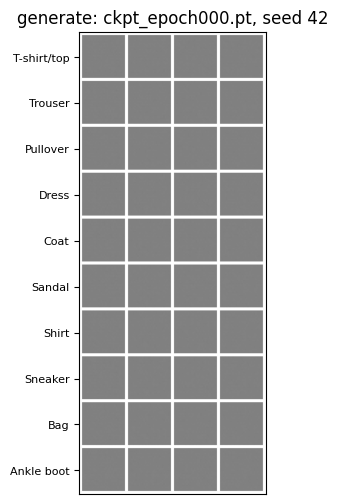

Grid disimpan di: /tmp/tmpph0iwc3b/all.png
Contoh: classifier menilai G BELUM DILATIH (angka rendah itu wajar)
kelas                 n   akurasi
---------------------------------
0: T-shirt/top        4     0.00%
1: Trouser            4     0.00%
2: Pullover           4     0.00%
3: Dress              4     0.00%
4: Coat               4     0.00%
5: Sandal             4     0.00%
6: Shirt              4     0.00%
7: Sneaker            4     0.00%
8: Bag                4   100.00%
9: Ankle boot         4     0.00%
---------------------------------
total (micro)        40    10.00%
rata-rata kelas            10.00%
TES 4b LULUS


In [12]:
OUT_TOL = 1e-4        # selisih float32: forward per-potongan vs satu batch, dan G sumber di CPU vs G di GPU
GRID_PAD = 2          # padding save_image_grid (Bagian 1)
img_shape = (CFG.img_channels, CFG.img_size, CFG.img_size)

with tempfile.TemporaryDirectory() as tmp:
    # --- Persiapan: checkpoint sementara dari G belum dilatih, D dan optimizer dummy ---
    set_seed(CFG.seed)
    G_src = Generator()
    # Isi running stats BatchNorm dengan beberapa forward mode train: tanpa ini G baru di mode eval
    # menghasilkan gambar hampir konstan (Tes 2.5), sehingga tes "seed berbeda -> output berbeda" lemah.
    with torch.no_grad():
        G_src.train()
        for _ in range(3):
            G_src(torch.randn(CFG.batch_size, CFG.z_dim),
                  torch.randint(0, CFG.num_classes, (CFG.batch_size,)))
    G_src.eval()
    D_dummy = nn.Linear(1, 1)                                  # Bagian 5 belum ada; save_checkpoint butuh D
    opt_G = torch.optim.Adam(G_src.parameters(), lr=CFG.lr_g, betas=(CFG.beta1, CFG.beta2))
    opt_D = torch.optim.Adam(D_dummy.parameters(), lr=CFG.lr_d, betas=(CFG.beta1, CFG.beta2))
    ck = ckpt_path(0, tmp)
    save_checkpoint(ck, 0, G_src, D_dummy, opt_G, opt_D)

    # --- Tes 4b.a: bentuk, tipe, rentang, bebas NaN ---
    n = 6
    out = generate(ck, class_id=7, n=n, seed=CFG.seed)
    assert out.shape == (n, *img_shape), f"keluaran {tuple(out.shape)}, seharusnya {(n, *img_shape)}"
    assert out.dtype == torch.float32 and out.device.type == "cpu"
    assert torch.isfinite(out).all(), "ada NaN/Inf di keluaran generate"
    assert out.min() >= -1.0 and out.max() <= 1.0, f"di luar [-1, 1]: [{out.min():.3f}, {out.max():.3f}]"

    # --- Tes 4b.b: bobot benar-benar dari checkpoint + protokol noise (termasuk pemotongan batch) ---
    n_big = CFG.batch_size + 3                                 # memaksa 2 potongan
    out_big = generate(ck, 3, n_big, seed=123)
    z_ref = torch.randn(n_big, CFG.z_dim, generator=torch.Generator().manual_seed(123))
    with torch.no_grad():
        ref = G_src(z_ref, torch.full((n_big,), 3, dtype=torch.long))
    assert torch.allclose(out_big, ref, atol=OUT_TOL), "generate tidak sama dengan G sumber: bobot/noise/pemotongan salah"

    # --- Tes 4b.c: seed sama -> identik; seed beda -> beda; tanpa seed -> beda tiap panggilan ---
    assert torch.equal(generate(ck, 7, n, seed=CFG.seed), out), "seed sama harus memberi output identik"
    assert not torch.equal(generate(ck, 7, n, seed=CFG.seed + 1), out), "seed berbeda harus memberi output berbeda"
    assert not torch.equal(generate(ck, 7, n), generate(ck, 7, n)), "tanpa seed, dua panggilan harus berbeda"
    # z sama, label berbeda -> gambar berbeda (label benar-benar dipakai)
    assert not torch.equal(generate(ck, 0, n, seed=CFG.seed), out), "label berbeda dengan seed sama harus berbeda"

    # --- Tes 4b.d: tanpa gradien, G beku, RNG global tidak bergeser ---
    assert not out.requires_grad and out.grad_fn is None, "output tidak boleh menyimpan graph gradien"
    G_loaded = load_generator(ck)
    assert not G_loaded.training, "G harus mode eval"
    assert not any(p.requires_grad for p in G_loaded.parameters()), "G hasil load harus beku"
    rng_before = torch.get_rng_state()
    generate(ck, 1, n, seed=5)
    assert torch.equal(torch.get_rng_state(), rng_before), "generate dengan seed tidak boleh menggeser RNG global"

    # --- Tes 4b.e: input tidak sah -> ValueError (dan file tidak ada -> FileNotFoundError) ---
    for kwargs in (dict(class_id=-1, n=4), dict(class_id=CFG.num_classes, n=4), dict(class_id=2.0, n=4),
                   dict(class_id=True, n=4), dict(class_id="3", n=4),
                   dict(class_id=1, n=0), dict(class_id=1, n=-5), dict(class_id=1, n=2.5),
                   dict(class_id=1, n=4, seed=-1), dict(class_id=1, n=4, seed=1.5)):
        try:
            generate(ck, **kwargs)
        except ValueError:
            pass
        else:
            raise AssertionError(f"generate(ck, {kwargs}) seharusnya memunculkan ValueError")
    G_train_mode = load_generator(ck).train()
    try:
        sample_from_generator(G_train_mode, 1, 4)
    except ValueError:
        pass
    else:
        raise AssertionError("G mode train seharusnya ditolak")
    try:
        generate(os.path.join(tmp, "tidak_ada.pt"), 1, 4)
    except FileNotFoundError:
        pass
    else:
        raise AssertionError("checkpoint yang tidak ada seharusnya memunculkan FileNotFoundError")

    # --- Tes 4b.f: config checkpoint berbeda ditolak dengan pesan yang menyebut field-nya ---
    bad = torch.load(ck, map_location="cpu", weights_only=True)
    bad["config"]["g_embed_dim"] = CFG.g_embed_dim * 2
    bad_ck = os.path.join(tmp, "bad.pt")
    torch.save(bad, bad_ck)
    try:
        generate(bad_ck, 1, 4)
    except ValueError as err:
        assert "g_embed_dim" in str(err), f"pesan error harus menyebut g_embed_dim: {err}"
    else:
        raise AssertionError("checkpoint dengan g_embed_dim berbeda seharusnya ditolak")

    # --- Tes 4b.g: generate_all_classes (grid 10 baris, kolom = noise yang sama) ---
    npc = 4
    grid_path = os.path.join(tmp, "all.png")
    imgs_all, labels_all, grid_all = generate_all_classes(ck, n_per_class=npc, seed=CFG.seed, path=grid_path)
    assert imgs_all.shape == (CFG.num_classes * npc, *img_shape), imgs_all.shape
    assert torch.equal(labels_all, torch.arange(CFG.num_classes).repeat_interleave(npc)), "baris ke-c harus kelas c"
    for c in (0, CFG.num_classes - 1):
        assert torch.equal(imgs_all[c * npc:(c + 1) * npc], generate(ck, c, npc, seed=CFG.seed)), \
            f"baris kelas {c} tidak sama dengan generate(ck, {c}, {npc}, seed)"
    w = npc * (CFG.img_size + GRID_PAD) + GRID_PAD
    h = CFG.num_classes * (CFG.img_size + GRID_PAD) + GRID_PAD
    assert os.path.isfile(grid_path) and Image.open(grid_path).size == (w, h), Image.open(grid_path).size
    assert grid_all.shape == (3, h, w)

    # --- Tes 4b.h: hasil generate langsung bisa dinilai classifier pendamping (jembatan ke Bagian 7) ---
    res = evaluate_classifier(clf, [(imgs_all, labels_all)])
    assert (res["n_per_class"] == npc).all(), "setiap kelas harus dinilai dengan npc gambar"
    assert not torch.isnan(res["per_class"]).any() and 0.0 <= res["acc"] <= 1.0
    print_accuracy_table(res, "Contoh: classifier menilai G BELUM DILATIH (angka rendah itu wajar)")

plt.close("all")
print("TES 4b LULUS")

# Bagian 5: Discriminator

## 5.1 Konsep: `Discriminator`

Discriminator (D) adalah "juri" dalam GAN. Tugasnya: diberi sebuah gambar **dan** label kelasnya,
lalu menjawab *"apakah pasangan ini asli dan cocok?"* dalam bentuk satu angka (logit).
Angka positif berarti "yakin asli dan cocok", angka negatif berarti "yakin palsu atau tidak cocok".
Angkanya sengaja **belum** dijadikan probabilitas (tanpa Sigmoid): Sigmoid dipasang oleh
`BCEWithLogitsLoss` di Bagian 6, yang lebih stabil secara numerik.

**Cara label masuk ke D (poin kunci untuk presentasi)**

1. Label (0..9) diubah `nn.Embedding(10, 784)` menjadi vektor 784 angka yang dipelajari.
2. Vektor itu dibentuk ulang menjadi "gambar" 1x28x28, yaitu peta label.
3. Peta label ditumpuk ke gambar sebagai kanal kedua: `[B,1,28,28]` + `[B,1,28,28]` -> `[B,2,28,28]`.
4. Karena setiap konvolusi melihat piksel gambar dan peta label di posisi yang sama,
   D bisa menolak pasangan seperti "gambar sepatu, label baju". Tekanan inilah yang memaksa G menaati label.

**Tabel layer (cetak biru bagian 3)**

| # | Layer | Keluaran | Aktivasi / normalisasi |
| --- | --- | --- | --- |
| 1-2 | Embedding(10, 784) -> reshape, lalu concat dengan x | [B,2,28,28] | tidak ada |
| 3 | Conv2d(2, 64, k4, s2, p1) | [B,64,14,14] | LeakyReLU(0,2), tanpa BatchNorm |
| 4 | Conv2d(64, 128, k4, s2, p1, bias=False) | [B,128,7,7] | BatchNorm2d + LeakyReLU(0,2) |
| 5 | Conv2d(128, 256, k3, s2, p1, bias=False) | [B,256,4,4] | BatchNorm2d + LeakyReLU(0,2) |
| 6-7 | Flatten, Linear(4096, 1), squeeze | [B] | tanpa Sigmoid |

**Keputusan desain**

| Keputusan | Alasan |
| --- | --- |
| Stride 2 menggantikan pooling | Pengecilan 28 -> 14 -> 7 -> 4 ikut dipelajari |
| LeakyReLU 0,2, bukan ReLU | Gradien tetap mengalir untuk nilai negatif; G belajar lewat gradien dari D |
| Tanpa BatchNorm di layer pertama | Kebiasaan DCGAN: statistik input asli tidak diubah |
| Ukuran D (±0,44 juta) lebih kecil dari G (±1,1 juta) | Agar D tidak menang terlalu cepat |
| Ukuran layer, slope, dropout, spectral norm dibaca dari `CFG` | Satu sumber kebenaran; Bagian 6 cukup mengubah `CFG` |
| Inisialisasi `weights_init` dipanggil **di dalam konstruktor**, sebelum spectral norm dipasang | Spectral norm menghitung ulang bobot tiap forward; inisialisasi sesudahnya tidak berefek / error |

**Dua saklar cadangan (default mati, dipakai bertahap di Bagian 6)**

- `dropout` (cadangan 1): `nn.Dropout2d(p)` setelah LeakyReLU di layer 4 dan 5. D menjadi "tidak selalu yakin".
- `spectral_norm` (cadangan 2): semua Conv2d dan Linear dibungkus `spectral_norm` dan **BatchNorm dihapus**
  (tidak boleh digabung). Membatasi seberapa tajam D bereaksi, sehingga gradien ke G lebih halus.
  Karena tidak ada BatchNorm lagi, konvolusi layer 4 dan 5 diberi bias.

In [13]:
# Import tambahan Bagian 5 (tidak ada di cell import Bagian 0).
# Diimpor dengan nama lain: argumen konstruktor D bernama `spectral_norm` dan akan menimpa nama fungsinya.
from torch.nn.utils import spectral_norm as apply_spectral_norm


class Discriminator(nn.Module):
    """Discriminator cGAN: (gambar x, label y) -> logit [B] (positif = "asli dan cocok dengan label").

    Alur (ukuran dari CFG, contoh angka untuk konfigurasi baseline):
      embed(y) -> reshape         [B,   1, 28, 28]   peta label
      concat(x, peta label)       [B,   2, 28, 28]
      Conv k4 s2 + LeakyReLU      [B,  64, 14, 14]   (tanpa BatchNorm)
      Conv k4 s2 + BN + LeakyReLU [B, 128,  7,  7]
      Conv k3 s2 + BN + LeakyReLU [B, 256,  4,  4]
      Flatten                     [B, 4096]
      Linear -> squeeze           [B]                (logit mentah, tanpa Sigmoid)

    dropout / spectral_norm: saklar cadangan Bagian 6. Bila None, nilainya diambil dari
    CFG.d_dropout / CFG.d_spectral_norm. Argumen eksplisit dipakai oleh tes agar CFG tidak berubah.
    """

    def __init__(self, dropout: float = None, spectral_norm: bool = None):
        super().__init__()
        dropout = CFG.d_dropout if dropout is None else dropout
        use_sn = CFG.d_spectral_norm if spectral_norm is None else spectral_norm
        if not (0.0 <= dropout < 1.0):
            raise ValueError(f"dropout harus di rentang [0, 1), diterima {dropout!r}")
        if not isinstance(use_sn, bool):
            raise ValueError(f"spectral_norm harus True/False, diterima {use_sn!r}")
        chs = CFG.d_channels                          # (64, 128, 256)
        kernels = (4, 4, 3)                           # cetak biru: layer 3, 4 -> k4; layer 5 -> k3 (7 -> 4)
        if len(chs) != len(kernels):
            raise ValueError(f"d_channels harus berisi {len(kernels)} angka, diterima {chs}")
        self.dropout = dropout
        self.use_spectral_norm = use_sn

        # Pembungkus tiap layer: init bobot DULU, baru (bila diminta) pasang spectral norm.
        # Urutan ini penting: spectral_norm menyimpan bobot asli sebagai weight_orig dan menghitung ulang
        # `weight` di setiap forward, jadi init yang dijalankan sesudahnya tidak berefek (atau error).
        def prepare(layer: nn.Module) -> nn.Module:
            weights_init(layer)                       # N(0, 0.02), sama dengan G (Bagian 1)
            if use_sn and isinstance(layer, (nn.Conv2d, nn.Linear)):
                layer = apply_spectral_norm(layer)
            return layer

        # 1) Label -> peta 28x28 yang dipelajari (bukan one-hot). Embedding tidak dibungkus spectral norm
        #    dan, seperti di G, dibiarkan memakai init default PyTorch (weights_init tidak menyentuhnya).
        self.embed = nn.Embedding(CFG.num_classes, CFG.d_embed_dim)

        # 2) Tiga blok konvolusi yang masing-masing mengecilkan resolusi (stride 2).
        blocks, c_in, side = [], CFG.img_channels + 1, CFG.img_size    # +1 kanal = peta label
        for i, (c_out, k) in enumerate(zip(chs, kernels)):
            # bias=False hanya bila tepat di depan BatchNorm (bias-nya dibatalkan normalisasi).
            # Layer pertama tidak punya BatchNorm, dan mode spectral norm membuang BatchNorm: keduanya pakai bias.
            has_bn = (i > 0) and not use_sn
            blocks.append(prepare(nn.Conv2d(c_in, c_out, kernel_size=k, stride=2, padding=1,
                                            bias=not has_bn)))
            if has_bn:
                blocks.append(prepare(nn.BatchNorm2d(c_out)))
            blocks.append(nn.LeakyReLU(CFG.leaky_slope))
            if i > 0 and dropout > 0:
                blocks.append(nn.Dropout2d(dropout))  # cadangan 1: setelah LeakyReLU di layer 4 dan 5
            c_in = c_out
            side = (side + 2 * 1 - k) // 2 + 1        # rumus ukuran keluaran Conv2d: 28 -> 14 -> 7 -> 4
        self.features = nn.Sequential(*blocks)

        # 3) Kepala: ratakan lalu satu Linear menjadi satu logit per gambar. Tanpa Sigmoid
        #    (BCEWithLogitsLoss di Bagian 6 sudah memuatnya, lebih stabil dan mendukung target 0,9).
        self.flat_dim = c_in * side * side            # 256 * 4 * 4 = 4096
        self.head = nn.Sequential(nn.Flatten(), prepare(nn.Linear(self.flat_dim, 1)))

    def forward(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        # Pemeriksaan input dengan pesan jelas (pola yang sama dengan Generator).
        expected = (CFG.img_channels, CFG.img_size, CFG.img_size)
        if x.dim() != 4 or tuple(x.shape[1:]) != expected:
            raise ValueError(f"x harus berbentuk [B, {', '.join(map(str, expected))}], diterima {tuple(x.shape)}")
        if y.dim() != 1 or y.size(0) != x.size(0):
            raise ValueError(f"y harus berbentuk [{x.size(0)}] (satu label per gambar), diterima {tuple(y.shape)}")
        if y.dtype != torch.long:
            raise TypeError(f"y harus bertipe torch.long (indeks kelas), diterima {y.dtype}")
        # Rentang label dan rentang gambar sengaja tidak dicek: memaksa sinkronisasi GPU di setiap iterasi
        # (alasan yang sama dengan Generator). Sudah dijamin oleh Tes 3.1 dan Tanh di G.

        label_map = self.embed(y).reshape(x.size(0), 1, CFG.img_size, CFG.img_size)   # [B, 784] -> [B,1,28,28]
        h = torch.cat([x, label_map], dim=1)          # [B, 2, 28, 28]: setiap konvolusi melihat gambar + label
        h = self.features(h)                          # [B, 256, 4, 4]
        # squeeze(1), bukan squeeze(): batch berisi 1 gambar tetap menghasilkan [1], bukan skalar.
        return self.head(h).squeeze(1)                # [B] logit


set_seed(CFG.seed)                 # bobot awal D sama di setiap run
D = Discriminator().to(DEVICE)     # weights_init sudah dipanggil di dalam konstruktor
print(D)
print(f"\nJumlah parameter: {sum(p.numel() for p in D.parameters()):,}")

Discriminator(
  (embed): Embedding(10, 784)
  (features): Sequential(
    (0): Conv2d(2, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=1, bias=True)
  )
)

Jumlah parameter: 440,801


In [14]:
B = CFG.batch_size
img_shape = (CFG.img_channels, CFG.img_size, CFG.img_size)

# Foto bobot D sebelum tes; Tes 5.8 memastikan semua tes tidak mengubah D milik notebook.
D_state_before = {k: v.detach().clone() for k, v in D.state_dict().items()}

# Batch real dari get_dataloader (Bagian 3): kontrak lintas bagian dites langsung dengan datanya.
x_real, y_real = next(iter(train_loader))
x_real, y_real = x_real.to(DEVICE), y_real.to(DEVICE)

# --- Tes 5.1: bentuk tiap tahap (dicatat lewat forward hook) dan kontrak keluaran ---
shapes = {}
hooks = [m.register_forward_hook(lambda m, inp, o, name=n: shapes.__setitem__(name, tuple(o.shape)))
         for n, m in D.named_modules() if len(list(m.children())) == 0]
D.eval()
with torch.no_grad():
    logit = D(x_real, y_real)
for h in hooks:
    h.remove()

chs, side = CFG.d_channels, CFG.img_size
expected = {"embed": (B, CFG.d_embed_dim)}
for i, c in enumerate(chs):                              # tiap blok mengecilkan resolusi: 28 -> 14 -> 7 -> 4
    side = (side + 2 - (4, 4, 3)[i]) // 2 + 1
    # Susunan features baseline: [conv, LeakyReLU] untuk blok 0; [conv, BN, LeakyReLU] untuk blok lain.
    idx = 0 if i == 0 else 2 + 3 * (i - 1)
    expected[f"features.{idx}"] = (B, c, side, side)
expected["head.1"] = (B, 1)                              # Linear menghasilkan [B, 1] sebelum squeeze
print(f"{'layer':12s} bentuk keluaran")
for name, shp in shapes.items():
    print(f"{name:12s} {shp}" + ("   <- dicek" if name in expected else ""))
for name, shp in expected.items():
    assert shapes[name] == shp, f"layer {name}: bentuk {shapes[name]}, seharusnya {shp}"
assert chs[-1] * side * side == D.flat_dim == 4096, f"flatten {D.flat_dim}, seharusnya 4096"

assert logit.shape == (B,), f"logit {tuple(logit.shape)}, seharusnya ({B},)"
assert logit.dtype == torch.float32
assert torch.isfinite(logit).all(), "ada NaN/Inf di logit"
# Logit mentah: tidak ada Sigmoid di model, dan modul terakhir adalah Linear dengan 1 keluaran.
assert not any(isinstance(m, nn.Sigmoid) for m in D.modules()), "D tidak boleh memuat Sigmoid"
assert isinstance(D.head[-1], nn.Linear) and D.head[-1].out_features == 1
# Batch berisi 1 gambar tetap menghasilkan [1] (bukan skalar) dan lolos BatchNorm eval.
with torch.no_grad():
    assert D(x_real[:1], y_real[:1]).shape == (1,)

# --- Tes 5.2: pengaturan layer dan jumlah parameter ---
assert D.embed.weight.shape == (CFG.num_classes, 784), D.embed.weight.shape
convs = [m for m in D.features if isinstance(m, nn.Conv2d)]
for conv, (k, c_in, c_out) in zip(convs, [(4, 2, 64), (4, 64, 128), (3, 128, 256)]):
    assert (conv.kernel_size, conv.stride, conv.padding) == ((k, k), (2, 2), (1, 1)), f"pengaturan Conv2d salah: {conv}"
    assert (conv.in_channels, conv.out_channels) == (c_in, c_out)
assert [c.bias is not None for c in convs] == [True, False, False], "bias: layer 1 ya, layer 2-3 tidak (di depan BatchNorm)"
bns = [m for m in D.features if isinstance(m, nn.BatchNorm2d)]
assert [b.num_features for b in bns] == [128, 256], "BatchNorm hanya di layer 2 dan 3 (layer 1 tanpa)"
assert isinstance(D.features[1], nn.LeakyReLU) and D.features[1].negative_slope == CFG.leaky_slope == 0.2
assert not any(isinstance(m, nn.Dropout2d) for m in D.modules()), "dropout harus mati di baseline"
assert not any(hasattr(m, "weight_orig") for m in D.modules()), "spectral norm harus mati di baseline"

# Jumlah parameter dihitung dari rumus, lalu dicocokkan dengan hitungan PyTorch dan target cetak biru.
n_params = sum(p.numel() for p in D.parameters())
expected_params = (784 * 10                              # embedding
                   + (2 * 64 * 4 * 4 + 64)               # conv1 (+ bias)
                   + 64 * 128 * 4 * 4 + 2 * 128          # conv2 (tanpa bias) + BatchNorm (weight, bias)
                   + 128 * 256 * 3 * 3 + 2 * 256         # conv3 (tanpa bias) + BatchNorm
                   + 4096 + 1)                           # linear
print(f"{'bagian':10s} {'parameter':>10s}")
for name, mod in D.named_children():
    print(f"{name:10s} {sum(p.numel() for p in mod.parameters()):>10,}")
print(f"{'TOTAL':10s} {n_params:>10,}")
assert n_params == expected_params, f"{n_params:,} parameter, hitungan rumus {expected_params:,}"
target = 440_000                                         # target cetak biru: ±0,44 juta
assert abs(n_params - target) / target < 0.05, f"{n_params:,} parameter, di luar ±5% dari {target:,}"
assert all(p.requires_grad for p in D.parameters()), "ada parameter yang tidak trainable"
n_g = sum(p.numel() for p in G.parameters())
assert n_params < n_g, f"D ({n_params:,}) harus lebih kecil dari G ({n_g:,}) agar tidak menang terlalu cepat"

# --- Tes 5.3: inisialisasi N(0, 0.02) pada Conv/Linear dan BatchNorm ---
set_seed(CFG.seed)
D_init = Discriminator().to(DEVICE)
for layer in [*[m for m in D_init.features if isinstance(m, nn.Conv2d)], D_init.head[1]]:
    n = layer.weight.numel()
    std = layer.weight.std().item()
    tol_std = 5 * CFG.init_std / (2 * n) ** 0.5          # toleransi 5 galat baku sampling (pola yang sama dengan Tes 1.1)
    tol_mean = 5 * CFG.init_std / n ** 0.5
    assert abs(std - CFG.init_std) < tol_std, f"{layer.__class__.__name__}: std={std:.5f}, seharusnya ~{CFG.init_std}"
    assert abs(layer.weight.mean().item()) < tol_mean, f"{layer.__class__.__name__}: mean bobot harus ~0"
    if layer.bias is not None:
        assert torch.count_nonzero(layer.bias) == 0, f"{layer.__class__.__name__}: bias harus 0"
for bn in [m for m in D_init.features if isinstance(m, nn.BatchNorm2d)]:
    assert abs(bn.weight.mean().item() - 1.0) < 0.01 and torch.count_nonzero(bn.bias) == 0

# --- Tes 5.4: label berpengaruh. Pasangan (gambar, label salah) harus memberi logit berbeda dari pasangan benar ---
wrong = (y_real + torch.randint(1, CFG.num_classes, y_real.shape, device=DEVICE)) % CFG.num_classes   # selalu != y_real
assert (wrong != y_real).all()
with torch.no_grad():
    logit_right = D(x_real, y_real)
    logit_wrong = D(x_real, wrong)
    logit_right_again = D(x_real, y_real)
assert torch.equal(logit_right, logit_right_again), "mode eval: input sama harus memberi logit sama persis"
gap = (logit_right - logit_wrong).abs()
print(f"selisih |logit benar - logit salah|: min {gap.min():.2e}  rata-rata {gap.mean():.2e}")
assert gap.min() > 1e-7, "ada gambar yang logitnya sama untuk label benar dan salah: label tidak berpengaruh"
# Gambar yang sama dengan 10 label berbeda harus memberi 10 logit berbeda.
with torch.no_grad():
    logit_10 = D(x_real[:1].expand(CFG.num_classes, -1, -1, -1), torch.arange(CFG.num_classes, device=DEVICE))
assert logit_10.unique().numel() == CFG.num_classes, "label berbeda harus memberi logit berbeda"
# Catatan: saat belum dilatih, D tidak tahu label mana yang benar, jadi arah selisih belum bisa dites (Tes 5.5).

# --- Tes 5.5: D benar-benar BISA belajar memakai label (mini-training pada satu batch) ---
# Pasangan (x, y benar) berlabel 1 dan (x, y salah) berlabel 0. Gambarnya SAMA, hanya labelnya yang beda,
# jadi D hanya bisa menang bila memakai jalur label. Ini juga jaring pengaman untuk risiko "G mengabaikan label".
set_seed(CFG.seed)
D_learn = Discriminator().to(DEVICE).train()
opt_learn = torch.optim.Adam(D_learn.parameters(), lr=CFG.lr_d * 5, betas=(CFG.beta1, CFG.beta2))
bce = nn.BCEWithLogitsLoss()
x_small, y_small = x_real[:64], y_real[:64]
wrong_small = (y_small + torch.randint(1, CFG.num_classes, y_small.shape, device=DEVICE)) % CFG.num_classes
ones, zeros = torch.ones(64, device=DEVICE), torch.zeros(64, device=DEVICE)
for step in range(150):
    loss = bce(D_learn(x_small, y_small), ones) + bce(D_learn(x_small, wrong_small), zeros)
    opt_learn.zero_grad(); loss.backward(); opt_learn.step()
D_learn.eval()
with torch.no_grad():
    ok = (D_learn(x_small, y_small) > D_learn(x_small, wrong_small)).float().mean().item()
print(f"setelah 150 langkah: loss {loss.item():.3f}, benar > salah pada {ok:.0%} pasangan")
assert ok >= 0.9, f"hanya {ok:.0%} pasangan yang dinilai benar > salah: jalur label di D bermasalah"

# --- Tes 5.6: saklar dropout (cadangan 1) ---
D_drop = Discriminator(dropout=0.3).to(DEVICE)
drops = [m for m in D_drop.features if isinstance(m, nn.Dropout2d)]
assert len(drops) == 2 and all(m.p == 0.3 for m in drops), "dropout harus ada di layer 4 dan 5, p=0.3"
for m in drops:                                          # dropout selalu tepat setelah LeakyReLU
    prev = D_drop.features[list(D_drop.features).index(m) - 1]
    assert isinstance(prev, nn.LeakyReLU), "Dropout2d harus tepat setelah LeakyReLU"
D_drop.train()
with torch.no_grad():
    a, b = D_drop(x_real, y_real), D_drop(x_real, y_real)
assert not torch.equal(a, b), "mode train: dropout seharusnya membuat dua forward berbeda"
D_drop.eval()
with torch.no_grad():
    assert torch.equal(D_drop(x_real, y_real), D_drop(x_real, y_real)), "mode eval: dropout harus mati"
assert sum(p.numel() for p in D_drop.parameters()) == n_params, "dropout tidak boleh menambah parameter"

# --- Tes 5.7: saklar spectral norm (cadangan 2): tanpa BatchNorm, semua Conv/Linear terbungkus ---
set_seed(CFG.seed)
D_sn = Discriminator(spectral_norm=True).to(DEVICE).train()
assert not any(isinstance(m, nn.BatchNorm2d) for m in D_sn.modules()), "spectral norm tidak boleh digabung BatchNorm"
wrapped = [m for m in D_sn.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
assert len(wrapped) == 4 and all(hasattr(m, "weight_orig") for m in wrapped), "semua Conv2d dan Linear harus berspektral norm"
assert all(m.bias is not None for m in wrapped), "tanpa BatchNorm, bias dipakai kembali"
assert not hasattr(D_sn.embed, "weight_orig"), "Embedding tidak ikut dibungkus"
for _ in range(30):                                      # power iteration berjalan 1 langkah per forward
    out_sn = D_sn(x_real, y_real)
assert out_sn.shape == (B,) and torch.isfinite(out_sn).all()
for m in wrapped:                                        # nilai singular terbesar bobot efektif ~ 1
    sigma = torch.linalg.matrix_norm(m.weight.detach().flatten(1), ord=2).item()
    assert 0.9 < sigma < 1.1, f"{m.__class__.__name__}: sigma terbesar {sigma:.3f}, seharusnya ~1"
# Bobot hasil init harus sempat tercatat: weight_orig berasal dari N(0, 0.02), bukan dari init default PyTorch.
for m in [m for m in wrapped if isinstance(m, nn.Conv2d)]:
    assert m.weight_orig.std().item() < 0.05, "init N(0, 0.02) tidak terbawa ke weight_orig (urutan init/spectral norm salah?)"
D_both = Discriminator(dropout=0.3, spectral_norm=True)  # kombinasi tidak error (urutan pemakaian diatur di Bagian 6)

# --- Tes 5.8: gradien mengalir ke parameter D DAN ke gambar masukan (dibutuhkan untuk update G) ---
for model in (D.train(), D_sn.train()):
    x_g = x_real.clone().requires_grad_(True)
    loss = model(x_g, y_real).mean()
    model.zero_grad(); loss.backward()
    assert x_g.grad is not None and torch.isfinite(x_g.grad).all() and x_g.grad.abs().sum() > 0, "gradien ke x tidak mengalir"
    for name, p in model.named_parameters():
        assert p.grad is not None and torch.isfinite(p.grad).all(), f"gradien {name} hilang / NaN"
D.eval()
# D milik notebook tidak boleh berubah oleh tes-tes di atas. Hanya bobot (parameter) yang dibandingkan:
# running stats BatchNorm memang ikut bergerak saat forward di mode train, dan itu wajar.
for k, p in D.named_parameters():
    assert torch.equal(p.detach(), D_state_before[k]), f"tes mengubah D milik notebook: {k}"

# --- Tes 5.9: simpan-muat state_dict (checkpoint Bagian 1 memakai weights_only=True) ---
for model_ctor in (lambda: Discriminator(), lambda: Discriminator(spectral_norm=True)):
    src = model_ctor().to(DEVICE).eval()
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "d.pt")
        torch.save(src.state_dict(), path)
        dst = model_ctor().to(DEVICE).eval()
        dst.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
    with torch.no_grad():
        assert torch.equal(src(x_real, y_real), dst(x_real, y_real)), "keluaran berbeda setelah simpan-muat"

# --- Tes 5.10: input tidak sah ditolak dengan pesan jelas ---
def expect_error(exc_type, fn, what):
    try:
        fn()
    except exc_type:
        return
    raise AssertionError(f"{what} seharusnya memunculkan {exc_type.__name__}")

expect_error(ValueError, lambda: D(x_real[:, :, :27, :], y_real), "gambar 28x27")
expect_error(ValueError, lambda: D(x_real.squeeze(1), y_real), "gambar tanpa dimensi kanal")
expect_error(ValueError, lambda: D(x_real, y_real[:-1]), "jumlah label tidak sama dengan jumlah gambar")
expect_error(ValueError, lambda: D(x_real, y_real.unsqueeze(1)), "label berbentuk [B,1]")
expect_error(TypeError, lambda: D(x_real, y_real.float()), "label bertipe float")
expect_error(ValueError, lambda: Discriminator(dropout=1.0), "dropout=1.0")
expect_error(ValueError, lambda: Discriminator(dropout=-0.1), "dropout negatif")
expect_error(ValueError, lambda: Discriminator(spectral_norm="ya"), "spectral_norm bukan bool")

print("TES 5 LULUS")

layer        bentuk keluaran
embed        (128, 784)   <- dicek
features.0   (128, 64, 14, 14)   <- dicek
features.1   (128, 64, 14, 14)
features.2   (128, 128, 7, 7)   <- dicek
features.3   (128, 128, 7, 7)
features.4   (128, 128, 7, 7)
features.5   (128, 256, 4, 4)   <- dicek
features.6   (128, 256, 4, 4)
features.7   (128, 256, 4, 4)
head.0       (128, 4096)
head.1       (128, 1)   <- dicek
bagian      parameter
embed           7,840
features      428,864
head            4,097
TOTAL         440,801
selisih |logit benar - logit salah|: min 2.35e-04  rata-rata 1.01e-02
setelah 150 langkah: loss 0.001, benar > salah pada 100% pasangan
TES 5 LULUS


# Bagian 6: Training Loop

## 6.1 Konsep: G dan D saling berlatih

GAN dilatih seperti permainan dua pemain. **Generator (G)** adalah pemalsu yang membuat gambar dari noise dan label.
**Discriminator (D)** adalah juri yang menilai apakah sebuah (gambar, label) itu asli dan cocok.
Keduanya saling memaksa membaik. Di setiap iterasi (satu batch gambar real) terjadi tiga hal:

| Langkah | Apa yang terjadi | Siapa yang belajar |
| --- | --- | --- |
| 1. Buat gambar palsu | G menerima noise z baru dan label y dari batch real, lalu menghasilkan gambar fake | tidak ada |
| 2. Latih D | D diajari: (real, y) harus dinilai **0,9**, (fake, y) harus dinilai **0,0** | D saja |
| 3. Latih G | G diajari: fake yang sama harus dinilai D sebagai **1,0** (asli) | G saja |

**Kenapa D hanya diajari 0,9 untuk gambar real, bukan 1,0 (one-sided label smoothing)?**
Supaya D tidak terlalu yakin. D yang terlalu yakin membuat gradien ke G mati dan G berhenti belajar.

**Kenapa gambar fake di langkah D harus `.detach()`?**
Gambar fake dibuat oleh G. Tanpa `.detach()`, saat D dilatih, gradiennya ikut mengalir ke G.
`.detach()` memutus jalur itu, sehingga langkah D hanya memperbarui D. Di langkah G, fake yang sama dipakai
**tanpa** detach karena gradien memang harus sampai ke G.

**Loss yang dipakai** (`BCEWithLogitsLoss`, D mengeluarkan logit mentah):

- `L_D` = loss bagian real + loss bagian fake (**dijumlah**, bukan dirata-rata). Tiap suku dirata-rata atas batch.
- `L_G` = satu suku, target 1,0 (bentuk non-saturating).
- Nilai acuan saat seimbang (D menebak 0,5 di mana-mana): `L_D` ≈ 1,386 dan `L_G` ≈ 0,693. Nilai ini menjadi garis acuan di grafik Bagian 7. Di iterasi pertama angkanya belum sama dengan acuan, karena BatchNorm di D mode train membuat logit awal tidak sekecil itu.

**Yang dicatat selama training**

| Keluaran | Isi | Kapan |
| --- | --- | --- |
| `logs/train_iter.csv` | loss G, L_D, D(real), D(fake) | setiap iterasi |
| `logs/train_epoch.csv` | rata-rata keempat angka itu, plus durasi | setiap epoch |
| `samples/epoch_XXX.png` | grid 10 baris (kelas) x 10 kolom, noise tetap | epoch 1, lalu tiap 5 epoch |
| `checkpoints/ckpt_epochXXX.pt` | G, D, kedua optimizer, epoch, config | tiap 10 epoch dan di akhir |

D(real) dan D(fake) adalah `sigmoid(logit).mean()` dari langkah D, tanpa forward tambahan.
Karena noise grid tetap, perbedaan antar-epoch murni akibat G yang belajar.

**Keputusan desain**

| Keputusan | Alasan |
| --- | --- |
| Fungsi kecil terpisah: `d_step`, `g_step`, `train_iteration`, lalu `train` | Setiap bagian bisa dites sendiri, termasuk dua kesalahan klasik: lupa `.detach()` dan salah optimizer |
| `train()` membangun G dan D sendiri setelah `set_seed` | Hasil reproducible dan tidak terpengaruh tes di sel lain |
| Satu `.tolist()` per iterasi untuk keempat angka | Satu sinkronisasi GPU saja; angka langsung dipakai untuk CSV dan pengecekan NaN |
| Loss NaN/Inf menghentikan training dengan pesan jelas | Lebih baik berhenti di iterasi pertama yang rusak daripada membuang 50 epoch |
| Sampel dibuat dengan `G.eval()` + `no_grad`, lalu mode G dikembalikan | BatchNorm memakai statistik hasil training; training tidak terganggu |
| Log ditulis per epoch (mode append) | Tidak membanjiri Drive dengan 23.400 penulisan kecil |
| Resume: log dipotong sampai epoch checkpoint | Run yang terputus setelah checkpoint tidak menggandakan baris epoch yang sama |
| Resume: `lr`, betas, weight_decay ditimpa dari `CFG` | `load_state_dict` optimizer membawa lr lama; tanpa ini "turunkan lr D" (bagian 9) diam-diam tidak berlaku |
| Run baru dengan checkpoint yang sudah ada di folder ditolak | Melindungi hasil baseline agar tidak tertimpa; run ablation pakai `run_dirs("nama")` |

**Cara pakai**

```python
out = train()                                   # 50 epoch; bila ada checkpoint di folder, otomatis lanjut
out = train(dirs=run_dirs("dropout"))           # run ablation di folder terpisah (setelah CFG.d_dropout = 0.3)
out = train(resume_from=ckpt_path(30), dirs=run_dirs("lanjut_dari_30"))   # lanjut dari checkpoint tertentu
```

In [15]:
# Import tambahan Bagian 6 (tidak ada di cell import Bagian 0).
import csv
import math
import re
import time
from itertools import islice
from tqdm.auto import tqdm   # progress bar dengan estimasi sisa waktu


@dataclass
class TrainConfig:
    """Pengaturan loop training yang tidak ada di CFG milik tim."""
    iter_log_name: str = "train_iter.csv"           # satu baris per iterasi (sumber grafik Bagian 7)
    epoch_log_name: str = "train_epoch.csv"         # satu baris per epoch
    sample_name: str = "epoch_{epoch:03d}.png"      # samples/epoch_XXX.png (cetak biru bagian 7)
    postfix_every: int = 50                         # progress bar menampilkan loss tiap sekian iterasi

    def __post_init__(self):
        if self.postfix_every <= 0:
            raise ValueError("postfix_every harus > 0.")
        if "{epoch" not in self.sample_name:
            raise ValueError("sample_name harus memuat {epoch}, mis. 'epoch_{epoch:03d}.png'.")


TRAIN_CFG = TrainConfig()
ITER_FIELDS = ("epoch", "iter", "global_iter", "loss_G", "loss_D", "d_real", "d_fake")
EPOCH_FIELDS = ("epoch", "loss_G", "loss_D", "d_real", "d_fake", "seconds")

# Satu objek loss untuk semua: BCEWithLogitsLoss = sigmoid + BCE dalam satu operasi yang stabil,
# dan default-nya merata-ratakan loss atas batch (sesuai cetak biru: tiap suku dirata-rata atas batch).
bce_logits = nn.BCEWithLogitsLoss()


# ---------------------------------------------------------------------------
# Folder keluaran
# ---------------------------------------------------------------------------
@dataclass
class RunDirs:
    ckpt: str
    sample: str
    log: str


def run_dirs(run_name: str = None) -> RunDirs:
    """Folder keluaran satu run. None = folder utama tim (baseline); nama lain = subfolder runs/<nama>.

    Run ablation (dropout, spectral norm, ...) wajib memakai nama sendiri agar checkpoint, log,
    dan grid baseline tidak tertimpa: perbandingan sebelum/sesudah butuh keduanya utuh.
    """
    if run_name is None:
        d = RunDirs(CFG.ckpt_dir, CFG.sample_dir, CFG.log_dir)
    else:
        if not re.fullmatch(r"[A-Za-z0-9_\-]+", run_name):
            raise ValueError(f"run_name hanya boleh huruf, angka, '_' dan '-', diterima {run_name!r}")
        root = os.path.join(CFG.out_root, "runs", run_name)
        d = RunDirs(os.path.join(root, "checkpoints"), os.path.join(root, "samples"), os.path.join(root, "logs"))
    for path in (d.ckpt, d.sample, d.log):
        os.makedirs(path, exist_ok=True)
    return d


# ---------------------------------------------------------------------------
# Jadwal: kapan membuat sampel dan checkpoint
# ---------------------------------------------------------------------------
def should_sample(epoch: int, every: int) -> bool:
    """Grid sampel di epoch 1 (bukti awal), lalu tiap `every` epoch."""
    return epoch == 1 or epoch % every == 0


def should_checkpoint(epoch: int, last_epoch: int, every: int) -> bool:
    """Checkpoint tiap `every` epoch, dan selalu di epoch terakhir."""
    return epoch % every == 0 or epoch == last_epoch


# ---------------------------------------------------------------------------
# Model dan optimizer
# ---------------------------------------------------------------------------
def build_training_state():
    """G, D, dan dua optimizer Adam terpisah, semuanya dari CFG."""
    G = Generator().to(DEVICE)
    D = Discriminator().to(DEVICE)       # membaca CFG.d_dropout / CFG.d_spectral_norm (saklar cadangan)
    adam_args = dict(betas=(CFG.beta1, CFG.beta2), weight_decay=CFG.weight_decay)
    opt_G = torch.optim.Adam(G.parameters(), lr=CFG.lr_g, **adam_args)
    opt_D = torch.optim.Adam(D.parameters(), lr=CFG.lr_d, **adam_args)
    return G, D, opt_G, opt_D


def sync_optimizer_hparams(opt, lr: float) -> None:
    """Paksa lr, betas, dan weight_decay optimizer mengikuti CFG sekarang.

    opt.load_state_dict() ikut memuat lr lama dari checkpoint. Tanpa fungsi ini, mengubah CFG.lr_d lalu
    melanjutkan training (resep "turunkan lr D" di cetak biru bagian 9) diam-diam tidak berpengaruh.
    """
    for group in opt.param_groups:
        group["lr"] = lr
        group["betas"] = (CFG.beta1, CFG.beta2)
        group["weight_decay"] = CFG.weight_decay


# ---------------------------------------------------------------------------
# Satu langkah D, satu langkah G, satu iterasi
# ---------------------------------------------------------------------------
def d_step(D, opt_D, x_real, y, fake):
    """Latih D: (real, y) -> target real_target (0,9); (fake, y) -> target fake_target (0,0).

    Mengembalikan (L_D, D(real), D(fake)); semuanya tensor tanpa gradien.
    """
    logit_real = D(x_real, y)
    # .detach() di dalam fungsi ini (bukan diserahkan ke pemanggil): tidak mungkin terlupa.
    # Ia memutus jalur gradien ke G, jadi langkah ini hanya memperbarui D.
    logit_fake = D(fake.detach(), y)
    loss_real = bce_logits(logit_real, torch.full_like(logit_real, CFG.real_target))
    loss_fake = bce_logits(logit_fake, torch.full_like(logit_fake, CFG.fake_target))
    loss_D = loss_real + loss_fake            # dijumlah, bukan dirata-rata (cetak biru bagian 4)

    opt_D.zero_grad(set_to_none=True)         # gradien lama dibuang; lupa baris ini membuat gradien menumpuk
    loss_D.backward()
    opt_D.step()

    with torch.no_grad():                     # untuk log: probabilitas rata-rata, dari logit yang sudah ada
        d_real = torch.sigmoid(logit_real).mean()
        d_fake = torch.sigmoid(logit_fake).mean()
    return loss_D.detach(), d_real, d_fake


def g_step(D, opt_G, fake, y):
    """Latih G: fake harus dinilai D sebagai asli (target g_target = 1,0, tanpa smoothing)."""
    logit = D(fake, y)                        # TANPA detach: gradien harus mengalir lewat D ke G
    loss_G = bce_logits(logit, torch.full_like(logit, CFG.g_target))

    opt_G.zero_grad(set_to_none=True)
    loss_G.backward()
    opt_G.step()                              # hanya opt_G: bobot D tidak berubah (gradien D sisa dibuang
    return loss_G.detach()                    # oleh opt_D.zero_grad() di langkah D berikutnya)


def train_iteration(G, D, opt_G, opt_D, x_real, y):
    """Satu iterasi: noise baru -> fake -> update D -> update G. Mengembalikan tensor [loss_G, L_D, D(real), D(fake)]."""
    z = torch.randn(x_real.size(0), CFG.z_dim, device=x_real.device)   # z baru tiap iterasi, N(0, I)
    fake = G(z, y)                            # y dari batch real: distribusi kelas fake = real
    for _ in range(CFG.d_steps):              # baseline 1 : 1
        loss_D, d_real, d_fake = d_step(D, opt_D, x_real, y, fake)
    for k in range(CFG.g_steps):
        if k > 0:                             # langkah G tambahan (opsi bagian 9) butuh fake baru: graf lama
            fake = G(torch.randn_like(z), y)  # sudah dipakai backward
        loss_G = g_step(D, opt_G, fake, y)
    return torch.stack([loss_G, loss_D, d_real, d_fake])


# ---------------------------------------------------------------------------
# Sampel, log, resume
# ---------------------------------------------------------------------------
@torch.no_grad()
def save_epoch_samples(G, epoch: int, sample_dir: str, z_fixed, y_fixed) -> str:
    """Simpan grid 10x10 dari noise tetap. Mode G dikembalikan seperti semula (training tidak terganggu)."""
    was_training = G.training
    G.eval()                                  # BatchNorm memakai statistik hasil training, bukan statistik batch
    try:
        path = os.path.join(sample_dir, TRAIN_CFG.sample_name.format(epoch=epoch))
        save_image_grid(G(z_fixed, y_fixed), path)   # baris ke-i = kelas ke-i (make_fixed_noise)
    finally:
        G.train(was_training)
    return path


def append_csv_rows(path: str, fields, rows) -> None:
    """Tambahkan baris ke CSV; header ditulis hanya bila file baru/kosong."""
    is_new = (not os.path.exists(path)) or os.path.getsize(path) == 0
    with open(path, "a", newline="") as f:
        writer = csv.writer(f)
        if is_new:
            writer.writerow(fields)
        writer.writerows(rows)


def truncate_log(path: str, last_epoch: int) -> int:
    """Buang baris dengan epoch > last_epoch; mengembalikan jumlah baris yang dibuang.

    Dipakai saat resume: run yang terputus SETELAH checkpoint terakhir sudah mencatat sebagian epoch berikutnya.
    Tanpa pemotongan, epoch itu muncul dua kali di log dan grafik Bagian 7 kacau.
    """
    if not os.path.exists(path):
        return 0
    with open(path, newline="") as f:
        reader = csv.reader(f)
        header = next(reader, None)
        rows = list(reader)
    if header is None:
        return 0
    keep = [r for r in rows if int(r[0]) <= last_epoch]      # kolom pertama selalu epoch
    if len(keep) != len(rows):
        tmp = path + ".tmp"
        with open(tmp, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow(header)
            writer.writerows(keep)
        os.replace(tmp, path)                                # atomik, pola yang sama dengan save_checkpoint
    return len(rows) - len(keep)


# Field CFG yang menentukan bentuk bobot G/D. Bila berbeda dengan checkpoint, load_state_dict gagal dengan
# "size mismatch" yang membingungkan; pemeriksaan ini memberi pesan yang jelas lebih dulu.
_RESUME_KEYS = ("z_dim", "g_embed_dim", "g_channels", "num_classes", "img_size", "img_channels",
                "d_channels", "leaky_slope", "d_spectral_norm", "norm_mean", "norm_std")


def check_resume_config(saved: dict) -> None:
    """ValueError bila arsitektur di checkpoint tidak sama dengan CFG sekarang."""
    as_cmp = lambda v: tuple(v) if isinstance(v, (list, tuple)) else v   # tuple vs list setelah simpan-muat
    bad = [f"{k}: checkpoint={saved.get(k)}, CFG sekarang={getattr(CFG, k)}"
           for k in _RESUME_KEYS if as_cmp(saved.get(k)) != as_cmp(getattr(CFG, k))]
    # Dropout hanya menambah/menghapus layer (menggeser indeks state_dict) saat p > 0 vs p = 0; nilai p bebas.
    if (saved.get("d_dropout", 0.0) > 0) != (CFG.d_dropout > 0):
        bad.append(f"d_dropout: checkpoint={saved.get('d_dropout')}, CFG sekarang={CFG.d_dropout} (aktif vs mati)")
    if bad:
        raise ValueError("config checkpoint tidak cocok dengan CFG sekarang:\n  " + "\n  ".join(bad)
                         + "\nSamakan CFG dengan run yang menghasilkan checkpoint ini.")


def _ckpt_epochs(directory: str):
    """Nomor epoch semua checkpoint GAN di folder (classifier.pt dan file .tmp tidak ikut)."""
    pattern = re.compile(r"ckpt_epoch(\d+)\.pt")
    return sorted(int(m.group(1)) for f in os.listdir(directory) if (m := pattern.fullmatch(f)))


# ---------------------------------------------------------------------------
# Loop utama
# ---------------------------------------------------------------------------
def train(epochs: int = None, dirs: RunDirs = None, resume: bool = True, resume_from: str = None,
          max_iters_per_epoch: int = None, sample_every: int = None, ckpt_every: int = None,
          loader=None, progress: bool = True) -> dict:
    """Latih cGAN sampai epoch `epochs` (default CFG.epochs). Mengembalikan dict berisi G, D, optimizer, folder.

    resume=True      : bila folder checkpoint sudah berisi checkpoint, lanjut dari yang terbaru; bila kosong, mulai baru.
    resume=False     : wajib mulai baru; ditolak bila folder sudah berisi checkpoint (melindungi hasil lama).
    resume_from      : path checkpoint tertentu (mis. sebelum mode collapse); mengalahkan `resume`.
    max_iters_per_epoch, sample_every, ckpt_every, loader: untuk tes cepat tanpa mengubah CFG.
    """
    epochs = CFG.epochs if epochs is None else epochs
    sample_every = CFG.sample_every if sample_every is None else sample_every
    ckpt_every = CFG.ckpt_every if ckpt_every is None else ckpt_every
    for name, v in (("epochs", epochs), ("sample_every", sample_every), ("ckpt_every", ckpt_every)):
        if isinstance(v, bool) or not isinstance(v, int) or v <= 0:
            raise ValueError(f"{name} harus bilangan bulat > 0, diterima {v!r}")
    if max_iters_per_epoch is not None and (isinstance(max_iters_per_epoch, bool)
                                            or not isinstance(max_iters_per_epoch, int) or max_iters_per_epoch <= 0):
        raise ValueError(f"max_iters_per_epoch harus bilangan bulat > 0, diterima {max_iters_per_epoch!r}")

    dirs = run_dirs() if dirs is None else dirs
    for path in (dirs.ckpt, dirs.sample, dirs.log):
        os.makedirs(path, exist_ok=True)
    iter_log = os.path.join(dirs.log, TRAIN_CFG.iter_log_name)
    epoch_log = os.path.join(dirs.log, TRAIN_CFG.epoch_log_name)

    # 1) Tentukan titik awal: mulai baru atau lanjut dari checkpoint.
    ckpt_file = resume_from
    if ckpt_file is None and _ckpt_epochs(dirs.ckpt):
        if not resume:
            raise FileExistsError(
                f"{dirs.ckpt} sudah berisi checkpoint. Pakai resume=True untuk melanjutkan, atau folder lain "
                "(train(dirs=run_dirs('nama_baru'))) agar hasil lama tidak tertimpa.")
        ckpt_file = latest_checkpoint(dirs.ckpt)

    if ckpt_file is None:
        set_seed(CFG.seed)                    # run baru: bobot awal dan urutan acak sama di setiap run
        G, D, opt_G, opt_D = build_training_state()
        start_epoch = 1
        print("Mulai training baru dari epoch 1.")
    else:
        G, D, opt_G, opt_D = build_training_state()
        ckpt = load_checkpoint(ckpt_file)     # helper Bagian 1; belum memuat apa pun ke model
        check_resume_config(ckpt["config"])   # pesan jelas sebelum load_state_dict gagal dengan "size mismatch"
        newer = [e for e in _ckpt_epochs(dirs.ckpt) if e > ckpt["epoch"]]
        if newer:
            raise ValueError(f"folder {dirs.ckpt} berisi checkpoint yang lebih baru (epoch {newer}) daripada "
                             f"{os.path.basename(ckpt_file)}; checkpoint basi itu akan dianggap 'terbaru' saat resume "
                             "berikutnya. Lanjutkan ke folder baru: train(dirs=run_dirs('nama_baru'), resume_from=...).")
        G.load_state_dict(ckpt["G"]); D.load_state_dict(ckpt["D"])
        opt_G.load_state_dict(ckpt["opt_G"]); opt_D.load_state_dict(ckpt["opt_D"])
        old = ckpt["config"]
        for name, lr_new, lr_old in (("lr_G", CFG.lr_g, old.get("lr_g")), ("lr_D", CFG.lr_d, old.get("lr_d"))):
            if lr_old != lr_new:
                print(f"Catatan: {name} berubah {lr_old} -> {lr_new}; nilai dari CFG dipakai.")
        sync_optimizer_hparams(opt_G, CFG.lr_g)
        sync_optimizer_hparams(opt_D, CFG.lr_d)
        start_epoch = ckpt["epoch"] + 1
        set_seed(CFG.seed + start_epoch)      # seed berbeda dari run awal: noise tidak mengulang urutan epoch 1
        print(f"Lanjut dari {os.path.basename(ckpt_file)} (selesai epoch {ckpt['epoch']}), mulai epoch {start_epoch}.")

    # Log dipotong sampai epoch yang sudah punya checkpoint (0 = run baru): sisa run yang terputus dibuang.
    for path in (iter_log, epoch_log):
        dropped = truncate_log(path, start_epoch - 1)
        if dropped:
            print(f"Log {os.path.basename(path)}: {dropped} baris sisa run terputus dibuang.")

    result = dict(G=G, D=D, opt_G=opt_G, opt_D=opt_D, last_epoch=start_epoch - 1, dirs=dirs)
    if start_epoch > epochs:
        print(f"Training sudah selesai (checkpoint epoch {start_epoch - 1} >= target {epochs}). Tidak ada yang dilatih.")
        return result

    loader = get_dataloader(CFG.batch_size, train=True) if loader is None else loader
    n_iters = len(loader) if max_iters_per_epoch is None else min(len(loader), max_iters_per_epoch)
    z_fixed, y_fixed = make_fixed_noise(DEVICE)     # noise tetap: beda antar-epoch murni karena G belajar
    print(f"Device {DEVICE.type} | epoch {start_epoch}-{epochs} | {n_iters} iterasi/epoch | "
          f"dropout D={CFG.d_dropout} | spectral norm D={CFG.d_spectral_norm}")

    # 2) Loop epoch.
    for epoch in range(start_epoch, epochs + 1):
        G.train(); D.train()                  # sampel di akhir epoch sebelumnya mengembalikan mode, ini jaring pengaman
        t0 = time.perf_counter()
        iter_rows, sums = [], [0.0] * 4
        bar = tqdm(islice(loader, n_iters), total=n_iters, desc=f"Epoch {epoch}/{epochs}",
                   leave=False, disable=not progress)
        try:
            for i, (x_real, y) in enumerate(bar, 1):
                x_real = x_real.to(DEVICE, non_blocking=True)
                y = y.to(DEVICE, non_blocking=True)
                # Satu .tolist() = satu sinkronisasi GPU untuk keempat angka.
                loss_g, loss_d, d_real, d_fake = train_iteration(G, D, opt_G, opt_D, x_real, y).tolist()
                if not all(map(math.isfinite, (loss_g, loss_d, d_real, d_fake))):
                    raise RuntimeError(
                        f"loss tidak berhingga di epoch {epoch}, iterasi {i}: loss_G={loss_g}, L_D={loss_d}. "
                        "Periksa rentang data/output G, .detach() di langkah D, dan lr (cetak biru bagian 9, baris 'Bug kode').")
                iter_rows.append([epoch, i, (epoch - 1) * n_iters + i, loss_g, loss_d, d_real, d_fake])
                for k, v in enumerate((loss_g, loss_d, d_real, d_fake)):
                    sums[k] += v
                if i % TRAIN_CFG.postfix_every == 0:
                    bar.set_postfix(L_G=f"{loss_g:.3f}", L_D=f"{loss_d:.3f}")
        finally:
            bar.close()
            append_csv_rows(iter_log, ITER_FIELDS, iter_rows)   # juga saat error/dihentikan: bahan diagnosis

        means = [s / n_iters for s in sums]
        seconds = time.perf_counter() - t0
        append_csv_rows(epoch_log, EPOCH_FIELDS, [[epoch, *means, seconds]])
        print(f"Epoch {epoch:3d}/{epochs} | L_G {means[0]:.3f} | L_D {means[1]:.3f} | "
              f"D(real) {means[2]:.3f} | D(fake) {means[3]:.3f} | {seconds:.1f} dtk")

        if should_sample(epoch, sample_every):
            save_epoch_samples(G, epoch, dirs.sample, z_fixed, y_fixed)
        if should_checkpoint(epoch, epochs, ckpt_every):
            save_checkpoint(ckpt_path(epoch, dirs.ckpt), epoch, G, D, opt_G, opt_D,
                            extra={"epoch_means": dict(zip(("loss_G", "loss_D", "d_real", "d_fake"), means))})
            print(f"           checkpoint disimpan: {os.path.basename(ckpt_path(epoch, dirs.ckpt))}")
        result["last_epoch"] = epoch

    print("Training selesai.")
    return result

In [16]:
import copy
import tempfile
import torch.nn.functional as F

# Dua pembantu tes: salinan bobot (parameter saja) dan pembanding dua salinan.
snap = lambda m: [p.detach().clone() for p in m.parameters()]
same = lambda m, s: all(torch.equal(p.detach(), q) for p, q in zip(m.parameters(), s))
x_b, y_b = next(iter(train_loader))
x_b, y_b = x_b.to(DEVICE), y_b.to(DEVICE)
B = x_b.size(0)

# --- Tes 6.1: jadwal sampel dan checkpoint sesuai cetak biru (sampel: epoch 1 + tiap 5; ckpt: tiap 10 + akhir) ---
sampled = [e for e in range(1, CFG.epochs + 1) if should_sample(e, CFG.sample_every)]
assert sampled == [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50], sampled
saved = [e for e in range(1, CFG.epochs + 1) if should_checkpoint(e, CFG.epochs, CFG.ckpt_every)]
assert saved == [10, 20, 30, 40, 50], saved
assert [e for e in range(1, 4) if should_checkpoint(e, 3, 10)] == [3], "epoch terakhir selalu disimpan"

# --- Tes 6.2: langkah D hanya mengubah D (menangkap lupa .detach()) dan rumus loss-nya benar ---
set_seed(CFG.seed)
G_t, D_t, optG_t, optD_t = build_training_state()
G_t.train(); D_t.train()
z = torch.randn(B, CFG.z_dim, device=DEVICE)
fake = G_t(z, y_b)
g0, d0 = snap(G_t), snap(D_t)
G_t.zero_grad(set_to_none=True)
# Hitung loss secara manual dari logit yang sama (D tanpa dropout bersifat deterministik di mode train).
with torch.no_grad():
    lr_, lf_ = D_t(x_b, y_b), D_t(fake, y_b)
manual = lambda l, t: (F.softplus(l) - t * l).mean()               # BCE-with-logits dari rumusnya: log(1+e^l) - t*l
expected_LD = manual(lr_, CFG.real_target) + manual(lf_, CFG.fake_target)
loss_D, d_real, d_fake = d_step(D_t, optD_t, x_b, y_b, fake)
assert torch.allclose(loss_D, expected_LD, atol=1e-5), f"L_D {loss_D.item():.6f}, rumus manual {expected_LD.item():.6f}"
assert all(p.grad is None for p in G_t.parameters()), "G menerima gradien dari langkah D: .detach() hilang"
assert same(G_t, g0), "langkah D mengubah bobot G"
assert not same(D_t, d0), "langkah D tidak mengubah bobot D"
assert not loss_D.requires_grad and not d_real.requires_grad, "keluaran d_step harus lepas dari graf"
assert 0 < d_real.item() < 1 and 0 < d_fake.item() < 1

# --- Tes 6.3: langkah G hanya mengubah G dan rumus loss-nya benar ---
d1, g1 = snap(D_t), snap(G_t)
with torch.no_grad():
    expected_LG = manual(D_t(fake, y_b), CFG.g_target)
loss_G = g_step(D_t, optG_t, fake, y_b)
assert torch.allclose(loss_G, expected_LG, atol=1e-5), f"L_G {loss_G.item():.6f}, rumus manual {expected_LG.item():.6f}"
assert same(D_t, d1), "langkah G mengubah bobot D (optimizer salah?)"
assert not same(G_t, g1), "langkah G tidak mengubah bobot G: gradien tidak sampai ke G"

# --- Tes 6.4: iterasi pertama pada model baru: berhingga dan masuk akal ---
# Nilai acuan seimbang (L_D 1,386; L_G 0,693) berlaku saat D menebak 0,5 di mana-mana. Di iterasi pertama D mode
# train belum buta: BatchNorm membuat aktivasinya berskala 1, jadi logit awal tidak sekecil di mode eval.
# Karena itu yang dites hanya rentang yang wajar, bukan kesamaan dengan acuan.
set_seed(CFG.seed)
G_t, D_t, optG_t, optD_t = build_training_state()
G_t.train(); D_t.train()
g0, d0 = snap(G_t), snap(D_t)
stats = train_iteration(G_t, D_t, optG_t, optD_t, x_b, y_b)
assert stats.shape == (4,) and torch.isfinite(stats).all()
lg, ld, dr, df = stats.tolist()
print(f"iterasi 1: L_G {lg:.4f}  L_D {ld:.4f}  D(real) {dr:.3f}  D(fake) {df:.3f}   (acuan seimbang: 0,693 / 1,386 / 0,5 / 0,5)")
assert 0.2 < lg < 3.0 and 0.5 < ld < 4.0, "loss iterasi pertama di luar rentang wajar"
assert 0 < dr < 1 and 0 < df < 1
assert not same(G_t, g0) and not same(D_t, d0), "satu iterasi harus memperbarui G dan D"

# --- Tes 6.5: sampel memakai mode eval lalu mengembalikan mode, tidak menyentuh BatchNorm, dan deterministik ---
with tempfile.TemporaryDirectory() as tmp:
    zf, yf = make_fixed_noise(DEVICE)
    G_t.train()
    bufs = [b.clone() for b in G_t.buffers()]
    p1 = save_epoch_samples(G_t, 1, tmp, zf, yf)
    assert G_t.training is True, "mode train G harus dikembalikan setelah membuat sampel"
    assert all(torch.equal(a, b) for a, b in zip(bufs, G_t.buffers())), "membuat sampel mengubah statistik BatchNorm G"
    assert os.path.basename(p1) == "epoch_001.png"
    with open(p1, "rb") as f1:
        first = f1.read()
    G_t.eval()
    p2 = save_epoch_samples(G_t, 2, tmp, zf, yf)
    assert G_t.training is False, "mode eval harus tetap eval bila sebelumnya eval"
    with open(p2, "rb") as f2:
        assert f2.read() == first, "noise tetap + G sama harus memberi gambar yang sama persis"
    assert Image.open(p1).size == (302, 302), "grid harus 10 x (28+2) + 2 = 302"

# --- Tes 6.6: loop lengkap, 3 epoch x 20 iterasi di folder sementara (Drive tidak tersentuh) ---
SMOKE = dict(max_iters_per_epoch=20, sample_every=2, ckpt_every=2, progress=False)
tmp_root = tempfile.TemporaryDirectory()
dirs_t = RunDirs(*(os.path.join(tmp_root.name, n) for n in ("checkpoints", "samples", "logs")))
t_start = time.perf_counter()
out = train(epochs=3, dirs=dirs_t, loader=train_loader, **SMOKE)
t_smoke = time.perf_counter() - t_start
assert out["last_epoch"] == 3 and out["G"].training and out["D"].training

with open(os.path.join(dirs_t.log, TRAIN_CFG.iter_log_name), newline="") as f:
    rows = list(csv.DictReader(f))
assert tuple(rows[0].keys()) == ITER_FIELDS
assert len(rows) == 3 * 20, f"{len(rows)} baris log iterasi, seharusnya 60"
assert [int(r["global_iter"]) for r in rows] == list(range(1, 61)), "global_iter harus berurutan 1..60"
assert [int(r["epoch"]) for r in rows[::20]] == [1, 2, 3]
assert all(math.isfinite(float(r[k])) for r in rows for k in ITER_FIELDS), "ada nilai log yang bukan angka"
with open(os.path.join(dirs_t.log, TRAIN_CFG.epoch_log_name), newline="") as f:
    erows = list(csv.DictReader(f))
assert tuple(erows[0].keys()) == EPOCH_FIELDS and [int(r["epoch"]) for r in erows] == [1, 2, 3]
mean_e1 = sum(float(r["loss_D"]) for r in rows[:20]) / 20
assert abs(float(erows[0]["loss_D"]) - mean_e1) < 1e-9, "log epoch harus = rata-rata log iterasi"

assert sorted(os.listdir(dirs_t.sample)) == ["epoch_001.png", "epoch_002.png"], os.listdir(dirs_t.sample)   # epoch 1 dan tiap 2
assert sorted(os.listdir(dirs_t.ckpt)) == ["ckpt_epoch002.pt", "ckpt_epoch003.pt"], os.listdir(dirs_t.ckpt)   # tiap 2 dan akhir
ck = torch.load(ckpt_path(3, dirs_t.ckpt), map_location="cpu", weights_only=True)
assert set(ck) >= {"epoch", "G", "D", "opt_G", "opt_D", "config"} and ck["epoch"] == 3
assert ck["config"]["lr_d"] == CFG.lr_d and ck["config"]["real_target"] == CFG.real_target
with open(os.path.join(dirs_t.sample, "epoch_001.png"), "rb") as f1, open(os.path.join(dirs_t.sample, "epoch_002.png"), "rb") as f2:
    assert f1.read() != f2.read(), "grid epoch 1 dan 2 identik: G tidak belajar atau sampel tidak diperbarui"
per_iter = t_smoke / 60
print(f"durasi {per_iter * 1000:.0f} ms/iterasi -> perkiraan 50 epoch x {CFG.iters_per_epoch} iterasi "
      f"= {per_iter * 50 * CFG.iters_per_epoch / 60:.1f} menit (cetak biru: ±5-10 menit di T4)"
      + ("   [berjalan di CPU: angka ini tidak mewakili T4]" if DEVICE.type == "cpu" else ""))

# --- Tes 6.7: resume. Lanjut dari epoch 3 ke 5, log tidak menggandakan epoch, bobot checkpoint termuat persis ---
G_saved = {k: v.clone() for k, v in torch.load(ckpt_path(3, dirs_t.ckpt), map_location=DEVICE, weights_only=True)["G"].items()}
out2 = train(epochs=5, dirs=dirs_t, loader=train_loader, **SMOKE)
assert out2["last_epoch"] == 5
with open(os.path.join(dirs_t.log, TRAIN_CFG.epoch_log_name), newline="") as f:
    assert [int(r["epoch"]) for r in csv.DictReader(f)] == [1, 2, 3, 4, 5], "epoch di log harus 1..5 tanpa duplikat"
with open(os.path.join(dirs_t.log, TRAIN_CFG.iter_log_name), newline="") as f:
    assert sum(1 for _ in csv.DictReader(f)) == 5 * 20
assert os.path.exists(ckpt_path(5, dirs_t.ckpt)) and os.path.exists(ckpt_path(4, dirs_t.ckpt))
assert any(not torch.equal(v, G_saved[k]) for k, v in out2["G"].state_dict().items()), "resume tidak melatih apa pun"

# Sisa run terputus: baris epoch 6 ada di log padahal checkpoint terakhir epoch 5 -> harus dibuang saat resume.
append_csv_rows(os.path.join(dirs_t.log, TRAIN_CFG.iter_log_name), ITER_FIELDS, [[6, 1, 101, 1.0, 1.0, 0.5, 0.5]])
append_csv_rows(os.path.join(dirs_t.log, TRAIN_CFG.epoch_log_name), EPOCH_FIELDS, [[6, 1.0, 1.0, 0.5, 0.5, 1.0]])
G_final = {k: v.clone() for k, v in out2["G"].state_dict().items()}
out3 = train(epochs=5, dirs=dirs_t, loader=train_loader, **SMOKE)      # sudah selesai: tidak melatih apa pun
assert out3["last_epoch"] == 5
assert all(torch.equal(v, G_final[k]) for k, v in out3["G"].state_dict().items()), "bobot hasil resume != checkpoint epoch 5"
with open(os.path.join(dirs_t.log, TRAIN_CFG.epoch_log_name), newline="") as f:
    assert [int(r["epoch"]) for r in csv.DictReader(f)] == [1, 2, 3, 4, 5], "baris epoch 6 sisa harus dibuang"
with open(os.path.join(dirs_t.log, TRAIN_CFG.iter_log_name), newline="") as f:
    assert sum(1 for _ in csv.DictReader(f)) == 100

# --- Tes 6.8: lr dari CFG menimpa lr di checkpoint ---
opt_probe = torch.optim.Adam(nn.Linear(2, 2).parameters(), lr=123.0, betas=(0.1, 0.2), weight_decay=0.5)
sync_optimizer_hparams(opt_probe, CFG.lr_d)
g0_ = opt_probe.param_groups[0]
assert (g0_["lr"], g0_["betas"], g0_["weight_decay"]) == (CFG.lr_d, (CFG.beta1, CFG.beta2), CFG.weight_decay)

# --- Tes 6.9: perlindungan dan pemeriksaan input ---
def expect_error(exc_type, fn, what):
    try:
        fn()
    except exc_type:
        return
    raise AssertionError(f"{what} seharusnya memunculkan {exc_type.__name__}")

expect_error(FileExistsError, lambda: train(epochs=5, dirs=dirs_t, resume=False, loader=train_loader, **SMOKE),
             "run baru (resume=False) di folder yang sudah berisi checkpoint")
expect_error(ValueError, lambda: train(epochs=5, dirs=dirs_t, resume_from=ckpt_path(2, dirs_t.ckpt), loader=train_loader, **SMOKE),
             "resume dari checkpoint lama saat ada checkpoint yang lebih baru di folder")
bad_cfg = {**ck["config"], "z_dim": CFG.z_dim + 1}
expect_error(ValueError, lambda: check_resume_config(bad_cfg), "config checkpoint dengan z_dim berbeda")
expect_error(ValueError, lambda: check_resume_config({**ck["config"], "d_dropout": 0.3}), "dropout aktif vs mati")
check_resume_config({**ck["config"], "lr_d": 1e-4, "d_dropout": 0.0})   # lr berbeda dan dropout sama-sama mati: boleh
for bad in (dict(epochs=0), dict(sample_every=0), dict(ckpt_every=-1), dict(max_iters_per_epoch=0), dict(epochs=2.5)):
    expect_error(ValueError, lambda: train(dirs=dirs_t, loader=train_loader, **bad), f"train({bad})")
expect_error(ValueError, lambda: run_dirs("../keluar"), "run_name dengan path")
tmp_root.cleanup()

# --- Tes 6.10: loss NaN menghentikan training dengan pesan jelas, log tetap tertulis ---
with tempfile.TemporaryDirectory() as tmp2:
    dirs_nan = RunDirs(*(os.path.join(tmp2, n) for n in ("checkpoints", "samples", "logs")))
    x_nan = x_b.clone(); x_nan[0, 0, 0, 0] = float("nan")
    try:
        train(epochs=1, dirs=dirs_nan, loader=[(x_nan.cpu(), y_b.cpu())], progress=False)
    except RuntimeError as err:
        assert "tidak berhingga" in str(err), err
    else:
        raise AssertionError("loss NaN seharusnya menghentikan training")
    assert not os.listdir(dirs_nan.ckpt), "tidak boleh ada checkpoint dari run yang rusak"

print("TES 6 LULUS")

iterasi 1: L_G 1.0147  L_D 1.5447  D(real) 0.362  D(fake) 0.342   (acuan seimbang: 0,693 / 1,386 / 0,5 / 0,5)
Mulai training baru dari epoch 1.
Device cuda | epoch 1-3 | 20 iterasi/epoch | dropout D=0.0 | spectral norm D=False
Epoch   1/3 | L_G 2.927 | L_D 0.621 | D(real) 0.768 | D(fake) 0.135 | 1.0 dtk
Epoch   2/3 | L_G 2.119 | L_D 0.830 | D(real) 0.675 | D(fake) 0.220 | 0.7 dtk
           checkpoint disimpan: ckpt_epoch002.pt
Epoch   3/3 | L_G 1.747 | L_D 1.014 | D(real) 0.604 | D(fake) 0.284 | 0.7 dtk
           checkpoint disimpan: ckpt_epoch003.pt
Training selesai.
durasi 44 ms/iterasi -> perkiraan 50 epoch x 468 iterasi = 17.0 menit (cetak biru: ±5-10 menit di T4)
Lanjut dari ckpt_epoch003.pt (selesai epoch 3), mulai epoch 4.
Device cuda | epoch 4-5 | 20 iterasi/epoch | dropout D=0.0 | spectral norm D=False
Epoch   4/5 | L_G 1.755 | L_D 1.064 | D(real) 0.588 | D(fake) 0.306 | 0.8 dtk
           checkpoint disimpan: ckpt_epoch004.pt
Epoch   5/5 | L_G 1.734 | L_D 1.117 | D(real) 0.

In [17]:
# Jalankan HANYA setelah TES 6 lulus. Satu perintah untuk seluruh training (50 epoch, ±5-10 menit di T4).
# Bila sesi Colab terputus: jalankan ulang sel ini. Checkpoint terbaru di Drive ditemukan otomatis dan
# training dilanjutkan; log dipotong sampai epoch checkpoint agar tidak ada epoch ganda.
out = train()
G, D = out["G"], out["D"]    # G dan D hasil training (menggantikan G dan D awal dari Bagian 2 dan 5)

Mulai training baru dari epoch 1.
Device cuda | epoch 1-50 | 468 iterasi/epoch | dropout D=0.0 | spectral norm D=False


Epoch 1/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch   1/50 | L_G 1.806 | L_D 1.020 | D(real) 0.604 | D(fake) 0.293 | 18.1 dtk


Epoch 2/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch   2/50 | L_G 1.758 | L_D 1.009 | D(real) 0.610 | D(fake) 0.288 | 18.4 dtk


Epoch 3/50:   0%|          | 0/468 [00:00<?, ?it/s]

... (91 outputs left out)

Epoch 49/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch  49/50 | L_G 2.554 | L_D 0.721 | D(real) 0.727 | D(fake) 0.173 | 18.4 dtk


Epoch 50/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch  50/50 | L_G 2.610 | L_D 0.684 | D(real) 0.735 | D(fake) 0.164 | 18.6 dtk
           checkpoint disimpan: ckpt_epoch050.pt
Training selesai.


# Bagian 7: Evaluasi

## 7.1 Konsep: kenapa butuh lima ukuran, bukan satu

Di model biasa, loss yang makin kecil berarti model makin baik. Di GAN tidak begitu. G dan D saling melawan,
jadi loss GAN naik-turun mengikuti siapa yang sedang unggul. Loss yang "bagus" bisa saja menyembunyikan gambar jelek.
Karena itu evaluasi memakai **lima ukuran sekaligus**, dan semuanya dihitung dari **file log yang nyata**, bukan diketik manual:

| Ukuran | Pertanyaan yang dijawab | Sumber | Keluaran |
| --- | --- | --- | --- |
| Grid sampel | Apakah gambarnya terlihat benar dan membaik antar-epoch? | `samples/epoch_XXX.png` (noise tetap) | grid 10 baris (kelas) x 10 kolom |
| Kurva loss G dan D | Apakah latihannya seimbang atau salah satu menang telak? | `train_iter.csv`, `train_epoch.csv` | satu grafik, dua garis, dua garis acuan |
| D(real) vs D(fake) | Seberapa yakin D menilai asli dan palsu? | `train_iter.csv`, `train_epoch.csv` | satu grafik, dua garis |
| Akurasi classifier | Apakah G menaati label? | classifier terpisah (Bagian 4) + 10.000 gambar buatan | akurasi total dan per kelas |
| Keragaman per kelas | Apakah G membuat gambar yang bervariasi, bukan satu gambar yang diulang (mode collapse)? | 1.000 gambar buatan per kelas | satu angka per kelas |

Hasil perhitungan akurasi dan keragaman ditulis ke tiga file CSV (`eval_summary.csv`, `eval_per_class.csv`,
`eval_confusion.csv`) di folder `logs/`, lalu semua grafik dibaca dari CSV itu. Grafik disimpan sebagai PNG di folder `figures/`.

**Cara menghitung**

- **Akurasi:** untuk tiap kelas c, G membuat 1.000 gambar dengan label c. Classifier (dilatih sekali pada data asli, dibekukan)
  menebak kelasnya. Akurasi kelas c = proporsi tebakan yang sama dengan c. Akurasi total = rata-rata 10 kelas.
  Pembandingnya akurasi classifier yang sama pada test set **asli**: itu batas atas.
- **Keragaman:** `x.std(dim=0).mean()` = simpangan baku tiap piksel atas 1.000 gambar, lalu dirata-rata. Dihitung untuk 1.000 gambar buatan
  dan 1.000 gambar real kelas yang sama. **Rasio = keragaman buatan / keragaman real.** Rasio di bawah 0,5 = curiga mode collapse.

## 7.2 Cara membaca tiap grafik (untuk presentasi)

**1. Grid sampel per kelas** (`sample_progress.png`)
Noise yang dipakai tetap, jadi perbedaan antar-epoch murni karena G belajar. Baris ke-i selalu kelas ke-i.
*Sehat:* epoch 1 berupa bercak abu-abu, lalu bentuk makin jelas, dan tiap baris berisi pakaian yang sesuai kelasnya dengan variasi antar-kolom.
*Bahaya:* satu baris berisi gambar yang nyaris identik (mode collapse), baris campur aduk (G mengabaikan label), atau grid macet berupa noise/gumpalan.
*Kalimat presentasi:* "Gambar di kolom yang sama berasal dari noise yang sama, jadi perubahan antar-panel adalah kemajuan G."

**2. Kurva loss** (`loss_curves.png`)
Garis tebal = rata-rata per epoch, garis pudar = rata-rata bergerak 100 iterasi. Garis putus-putus = nilai acuan saat seimbang
(`L_D` = 1,386 dan `L_G` = 0,693; D menebak 0,5 di mana-mana).
*Sehat:* naik-turun di sekitar acuan, atau `L_G` naik pelan-pelan sementara gambar membaik. Itu normal.
*Bahaya:* `L_D` bertahan di bawah 0,6 (batas bawah teoretis ±0,33 karena smoothing) dan `L_G` naik terus di atas 3 = D terlalu kuat.
`L_G` yang melonjak naik-turun tajam = tanda mode collapse.
*Peringatan:* jangan menyimpulkan dari loss saja. Loss bagus tidak menjamin gambar bagus.

**3. D(real) vs D(fake)** (`d_outputs.png`)
Rata-rata probabilitas yang diberikan D, dari logit langkah D. Pita hijau dan ungu = pembacaan sehat; garis titik hitam = batas bahaya.
*Sehat:* D(real) di 0,6-0,8 dan D(fake) di 0,2-0,4, keduanya mendekat ke 0,5. Karena target real 0,9, D(real) yang menetap di 0,9 atau lebih
adalah tanda D terlalu yakin.
*Bahaya:* D(real) ≥ 0,9 **dan** D(fake) ≤ 0,1 selama beberapa epoch (kita pakai 3 epoch berturut-turut).
*Kalimat presentasi:* "Kalau dua garis ini saling menjauh ke 1 dan 0, juri sudah terlalu pintar dan G tidak lagi dapat sinyal belajar."

**4. Akurasi classifier** (`accuracy.png`)
Kiri: akurasi total tiap checkpoint (epoch 10, 20, ..., 50) terhadap target 80% dan batas atas data asli. Kanan: per kelas, buatan vs asli.
*Sehat:* total ≥ 80% dan mendekati akurasi data asli. Kelas Shirt (6) memang paling rendah bahkan pada data asli, karena mirip T-shirt dan Pullover.
*Bahaya:* turun ke 10-50% padahal gambar terlihat bagus = G mengabaikan label.
*Keterbatasan:* metrik ini hanya mengukur apakah label ditaati. Gambar kabur atau seragam bisa tetap lolos.
Karena itu akurasi harus dibaca bersama grid dan keragaman.

**5. Keragaman per kelas** (`diversity.png`)
Kiri: rasio per kelas pada checkpoint terakhir; batang oranye = di bawah ambang 0,5. Kanan: rasio terendah dan rata-rata tiap checkpoint.
*Sehat:* semua batang di atas 0,5 dan tidak turun dari checkpoint ke checkpoint.
*Bahaya:* satu kelas di bawah 0,5 = curiga mode collapse pada kelas itu. Ambang 0,5 adalah aturan praktis tim, bukan standar baku.
*Peringatan:* rasio di atas 1 tidak otomatis bagus. Gambar penuh noise juga berkeragaman tinggi.

**6. Matriks kebingungan** (`confusion_epochXXX.png`)
Baris = kelas yang diminta ke G, kolom = tebakan classifier, dalam persen per baris. Diagonal yang gelap = G menaati label.
Kotak gelap di luar diagonal menunjukkan pasangan kelas yang tertukar (biasanya T-shirt/Shirt/Pullover/Coat).

**Urutan diagnosis bila hasil buruk (cetak biru bagian 9):** (1) grid terbaru vs epoch sebelumnya, (2) D(real) vs D(fake),
(3) akurasi dan keragaman, (4) baru kurva loss, (5) ubah satu hal, jalankan ulang, catat sebelum/sesudahnya.

## 7.3 Keputusan desain

| Keputusan | Alasan |
| --- | --- |
| Seed evaluasi = `CFG.seed + 1` | Noise tetap di grid memakai `CFG.seed`; evaluasi memakai noise lain agar tidak menguji G dengan "soal yang sama" |
| Evaluasi menulis CSV, grafik membaca CSV | Semua grafik berasal dari file; Sri (dokumentasi) bisa memakai CSV mentahnya |
| Nilai akhir di diagnosis = rata-rata 5 epoch terakhir | Satu epoch bisa berisik |
| Pemeriksaan log: epoch harus 1..N berurutan dan log iterasi harus cocok dengan log epoch | Log dari run berbeda atau epoch ganda tidak diam-diam membuat grafik salah |
| `load_generator` dan `sample_from_generator` dari Bagian 4 dipakai langsung | G dibangun dengan validasi config dan mode eval yang sama dengan `generate()` |
| Diagnosis otomatis memakai tiga status: OK, PERHATIAN (di luar pita sehat), WASPADA (melewati ambang bahaya) | Membedakan "perlu dipantau" dari "perlu bertindak" |


In [18]:
# Bagian 7 memakai import Bagian 0 dan 6 (csv, math, re, np, plt, os, torch); tidak ada import tambahan.


@dataclass
class EvalConfig:
    """Pengaturan evaluasi (cetak biru bagian 7 dan 9) yang tidak ada di CFG milik tim."""
    # Seed evaluasi = CFG.seed + seed_offset. Sengaja BUKAN CFG.seed: noise tetap untuk grid sampel memakai
    # CFG.seed, jadi evaluasi tidak menguji G dengan noise yang sama persis dengan yang dipakai di grid.
    seed_offset: int = 1
    target_acc: float = 0.80          # target kerja: akurasi total classifier pada gambar buatan >= 80%
    min_div_ratio: float = 0.5        # rasio keragaman buatan/real di bawah ini = curiga mode collapse
    ma_window: int = 100              # moving average loss/D(.) per iterasi
    # Ambang diagnosis dari cetak biru bagian 6 dan 9:
    low_ld: float = 0.6               # L_D bertahan di bawah ini = D terlalu kuat
    high_lg: float = 3.0              # L_G di atas ini dan tidak turun = D terlalu kuat
    danger_d_real: float = 0.9        # D(real) >= 0,9 dan D(fake) <= 0,1 ...
    danger_d_fake: float = 0.1
    danger_epochs: int = 3            # ... selama sekian epoch berturut-turut ("beberapa epoch" = 3, aturan praktis tim)
    healthy_d_real: Tuple[float, float] = (0.6, 0.8)   # pembacaan sehat (cetak biru bagian 7)
    healthy_d_fake: Tuple[float, float] = (0.2, 0.4)
    tail_epochs: int = 5              # "nilai akhir" = rata-rata sekian epoch terakhir (satu epoch bisa berisik)
    real_grid_name: str = "real_reference.png"         # dibuat Bagian 3.2, ada di CFG.sample_dir
    summary_name: str = "eval_summary.csv"             # satu baris per checkpoint
    per_class_name: str = "eval_per_class.csv"         # satu baris per (checkpoint, kelas)
    confusion_name: str = "eval_confusion.csv"         # satu baris per (checkpoint, kelas benar, kelas prediksi)
    fig_subdir: str = "figures"                        # folder grafik, sejajar dengan checkpoints/samples/logs

    def __post_init__(self):
        if self.seed_offset < 0 or self.ma_window <= 0 or self.danger_epochs <= 0 or self.tail_epochs <= 0:
            raise ValueError("seed_offset >= 0; ma_window, danger_epochs, tail_epochs > 0.")
        if not (0 < self.target_acc <= 1 and 0 < self.min_div_ratio):
            raise ValueError("target_acc di (0, 1] dan min_div_ratio > 0.")

    @property
    def eval_seed(self) -> int:
        return CFG.seed + self.seed_offset              # dihitung saat dipakai: selalu mengikuti CFG terbaru


EVAL_CFG = EvalConfig()
COLORS = dict(G="#D55E00", D="#0072B2", real="#009E73", fake="#CC79A7", grey="#666666")   # palet ramah buta warna


# ---------------------------------------------------------------------------
# Membaca log (sumber tunggal semua grafik)
# ---------------------------------------------------------------------------
def read_table(path: str, fields=None) -> dict:
    """Baca CSV menjadi {nama_kolom: np.array}. Kolom numerik jadi float, kolom teks tetap teks."""
    if not os.path.isfile(path):
        raise FileNotFoundError(f"file tidak ditemukan: {path}. Jalankan training (Bagian 6) / evaluasi lebih dulu.")
    with open(path, newline="") as f:
        reader = csv.reader(f)
        header = next(reader, None)
        rows = list(reader)
    if header is None or not rows:
        raise ValueError(f"{path} kosong (tidak ada baris data)")
    if fields is not None and tuple(header) != tuple(fields):
        raise ValueError(f"header {os.path.basename(path)} = {header}, seharusnya {list(fields)}")
    table = {}
    for j, name in enumerate(header):
        raw = [r[j] for r in rows]
        try:
            table[name] = np.array([float(v) for v in raw])
        except ValueError:
            table[name] = np.array(raw)
    return table


def load_training_logs(dirs: RunDirs):
    """Log iterasi dan log epoch, divalidasi: epoch 1..N berurutan, dan kedua file berasal dari run yang sama."""
    it = read_table(os.path.join(dirs.log, TRAIN_CFG.iter_log_name), ITER_FIELDS)
    ep = read_table(os.path.join(dirs.log, TRAIN_CFG.epoch_log_name), EPOCH_FIELDS)
    epochs = ep["epoch"].astype(int)
    if epochs[0] != 1 or not np.all(np.diff(epochs) == 1):
        raise ValueError(f"epoch di log epoch bukan 1..N berurutan: {epochs.tolist()[:12]}... (ada epoch ganda/hilang?)")
    keep = it["epoch"] <= epochs[-1]                       # baris dari epoch yang belum selesai (run terputus) diabaikan
    it = {k: v[keep] for k, v in it.items()}
    # Konsistensi: rata-rata log iterasi per epoch harus sama dengan baris di log epoch.
    idx = it["epoch"].astype(int)
    counts = np.bincount(idx, minlength=epochs[-1] + 1)[1:]
    for key in ("loss_G", "loss_D", "d_real", "d_fake"):
        means = np.bincount(idx, weights=it[key], minlength=epochs[-1] + 1)[1:] / np.maximum(counts, 1)
        if not np.allclose(means, ep[key], atol=1e-6):
            raise ValueError(f"log iterasi dan log epoch tidak konsisten pada kolom {key}: kemungkinan berasal dari run berbeda")
    return it, ep


def moving_average(v: np.ndarray, window: int) -> np.ndarray:
    """Rata-rata bergerak 'valid': panjang len(v) - window + 1 (kosong bila v lebih pendek dari window)."""
    if len(v) < window:
        return np.array([])
    return np.convolve(v, np.ones(window) / window, mode="valid")


# ---------------------------------------------------------------------------
# Metrik: akurasi classifier dan keragaman
# ---------------------------------------------------------------------------
def diversity(x: torch.Tensor) -> float:
    """Keragaman satu kelompok gambar [N,1,28,28]: simpangan baku tiap piksel atas N gambar, dirata-rata (cetak biru 7.5).

    Gambar yang semuanya (hampir) sama memberi angka mendekati 0; gambar yang beragam memberi angka besar.
    """
    if x.size(0) < 2:
        raise ValueError("keragaman butuh minimal 2 gambar")
    return x.float().std(dim=0).mean().item()


def compute_real_reference(clf, n_per_class: int = None) -> dict:
    """Pembanding dari data ASLI: akurasi classifier per kelas (test set) dan keragaman per kelas (n gambar train).

    Dihitung sekali. Hasilnya batas atas untuk akurasi, dan penyebut untuk rasio keragaman.
    """
    n = CFG.eval_per_class if n_per_class is None else n_per_class
    test_res = evaluate_classifier(clf, get_dataloader(CFG.batch_size, train=False))   # kontrak Bagian 3 dan 4
    ds = get_dataset(train=True)
    div = []
    for c in range(CFG.num_classes):
        idx = torch.nonzero(ds.targets == c).flatten()[:n]          # n gambar pertama kelas c: tetap, tanpa acak
        if idx.numel() < n:
            raise ValueError(f"kelas {c} hanya punya {idx.numel()} gambar real, diminta {n}")
        # Rumus yang sama dengan transform Bagian 3 (diverifikasi Tes 3.1d): (piksel/255 - mean) / std.
        x = ((ds.data[idx].float() / 255.0 - CFG.norm_mean) / CFG.norm_std).unsqueeze(1)
        div.append(diversity(x))
    return {"acc_class": test_res["per_class"].clone(), "acc_total": test_res["acc_macro"], "div": torch.tensor(div)}


@torch.no_grad()
def evaluate_checkpoint(ckpt_file: str, clf, n_per_class: int, seed: int) -> dict:
    """Akurasi classifier dan keragaman pada n_per_class gambar buatan untuk setiap kelas, dari satu checkpoint."""
    G = load_generator(ckpt_file)                        # helper Bagian 4: config divalidasi, mode eval, beku
    batches, div = [], []
    for c in range(CFG.num_classes):
        x = sample_from_generator(G, c, n_per_class, seed)          # [n,1,28,28] di [-1,1], label = c
        batches.append((x, torch.full((n_per_class,), c, dtype=torch.long)))
        div.append(diversity(x))
    res = evaluate_classifier(clf, batches)              # loader boleh berupa list pasangan (img, label): kontrak Bagian 4
    return {"acc_class": res["per_class"], "acc_total": res["acc_macro"],   # acc_macro = rata-rata 10 kelas (cetak biru)
            "div": torch.tensor(div), "confusion": res["confusion"]}


def write_csv(path: str, fields, rows) -> None:
    """Tulis CSV lengkap (menimpa), atomik: Colab putus di tengah tidak meninggalkan file setengah jadi."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(fields)
        writer.writerows(rows)
    os.replace(tmp, path)


SUMMARY_FIELDS = ("epoch", "acc_total", "acc_real_total", "acc_min_class", "acc_min_class_id",
                  "div_ratio_mean", "div_ratio_min", "div_ratio_min_class")
PER_CLASS_FIELDS = ("epoch", "class_id", "class_name", "acc_fake", "acc_real", "div_fake", "div_real", "div_ratio")
CONFUSION_FIELDS = ("epoch", "true_class", "pred_class", "count")


def run_evaluation(dirs: RunDirs = None, clf=None, ref: dict = None, n_per_class: int = None) -> dict:
    """Evaluasi semua checkpoint di dirs.ckpt dan tulis tiga CSV ke dirs.log. Grafik membaca CSV ini."""
    dirs = run_dirs() if dirs is None else dirs
    n_per_class = CFG.eval_per_class if n_per_class is None else n_per_class
    if isinstance(n_per_class, bool) or not isinstance(n_per_class, int) or n_per_class < 2:
        raise ValueError(f"n_per_class harus bilangan bulat >= 2, diterima {n_per_class!r}")
    epochs = _ckpt_epochs(dirs.ckpt)                     # helper Bagian 6; classifier.pt tidak ikut
    if not epochs:
        raise FileNotFoundError(f"tidak ada checkpoint GAN di {dirs.ckpt}. Jalankan training (Bagian 6) lebih dulu.")
    clf = load_classifier() if clf is None else clf
    ref = compute_real_reference(clf, n_per_class) if ref is None else ref
    seed = EVAL_CFG.eval_seed

    summary_rows, class_rows, conf_rows = [], [], []
    t0 = time.perf_counter()
    for e in epochs:
        r = evaluate_checkpoint(ckpt_path(e, dirs.ckpt), clf, n_per_class, seed)
        ratio = r["div"] / ref["div"]                    # buatan / real, per kelas
        acc = r["acc_class"]
        for c in range(CFG.num_classes):
            class_rows.append([e, c, CLASS_NAMES[c], acc[c].item(), ref["acc_class"][c].item(),
                               r["div"][c].item(), ref["div"][c].item(), ratio[c].item()])
            conf_rows += [[e, c, p, int(r["confusion"][c, p])] for p in range(CFG.num_classes)]
        summary_rows.append([e, r["acc_total"], ref["acc_total"], acc.min().item(), int(acc.argmin()),
                             ratio.mean().item(), ratio.min().item(), int(ratio.argmin())])
        print(f"epoch {e:3d} | akurasi {r['acc_total']:.2%} | rasio keragaman min {ratio.min():.2f} "
              f"(kelas {int(ratio.argmin())}: {CLASS_NAMES[int(ratio.argmin())]})")
    write_csv(os.path.join(dirs.log, EVAL_CFG.summary_name), SUMMARY_FIELDS, summary_rows)
    write_csv(os.path.join(dirs.log, EVAL_CFG.per_class_name), PER_CLASS_FIELDS, class_rows)
    write_csv(os.path.join(dirs.log, EVAL_CFG.confusion_name), CONFUSION_FIELDS, conf_rows)
    print(f"Evaluasi {len(epochs)} checkpoint selesai dalam {time.perf_counter() - t0:.1f} dtk "
          f"({n_per_class} gambar/kelas, seed {seed}). CSV di {dirs.log}")
    return {"epochs": epochs, "ref": ref, "n_per_class": n_per_class, "seed": seed}


# ---------------------------------------------------------------------------
# Diagnosis otomatis dengan ambang cetak biru
# ---------------------------------------------------------------------------
def _longest_run(flags: np.ndarray) -> int:
    """Panjang deretan True berturut-turut terpanjang."""
    best = cur = 0
    for f in flags:
        cur = cur + 1 if f else 0
        best = max(best, cur)
    return best


def diagnose(ep: dict, summary: dict, per_class: dict) -> list:
    """Daftar pemeriksaan {periksa, nilai, ambang, status}. Status: OK / PERHATIAN (di luar pita sehat) / WASPADA (ambang bahaya)."""
    cfg, tail = EVAL_CFG, EVAL_CFG.tail_epochs
    last = lambda key: float(np.mean(ep[key][-tail:]))
    out = []

    def add(name, value, rule, status):
        out.append({"periksa": name, "nilai": value, "ambang": rule, "status": status})

    ld, lg = last("loss_D"), last("loss_G")
    add("L_D tidak terlalu rendah", f"{ld:.3f}", f">= {cfg.low_ld}", "OK" if ld >= cfg.low_ld else "WASPADA")
    add("L_G tidak melonjak", f"{lg:.3f}", f"<= {cfg.high_lg}", "OK" if lg <= cfg.high_lg else "WASPADA")
    strong = (ep["d_real"] >= cfg.danger_d_real) & (ep["d_fake"] <= cfg.danger_d_fake)
    run = _longest_run(strong)
    add("D terlalu yakin (D(real)>=0,9 dan D(fake)<=0,1)", f"{run} epoch berturut", f"< {cfg.danger_epochs}",
        "OK" if run < cfg.danger_epochs else "WASPADA")
    dr, df = last("d_real"), last("d_fake")
    healthy = cfg.healthy_d_real[0] <= dr <= cfg.healthy_d_real[1] and cfg.healthy_d_fake[0] <= df <= cfg.healthy_d_fake[1]
    add("D(real), D(fake) di pita sehat", f"{dr:.3f} / {df:.3f}",
        f"{cfg.healthy_d_real} / {cfg.healthy_d_fake}", "OK" if healthy else "PERHATIAN")
    acc = float(summary["acc_total"][-1])
    add("Akurasi classifier pada gambar buatan", f"{acc:.2%}", f">= {cfg.target_acc:.0%}", "OK" if acc >= cfg.target_acc else "WASPADA")
    final = per_class["epoch"] == summary["epoch"][-1]
    ratio = per_class["div_ratio"][final]
    worst = int(np.argmin(ratio))
    add("Keragaman terendah (rasio buatan/real)", f"{ratio[worst]:.2f} ({CLASS_NAMES[worst]})", f">= {cfg.min_div_ratio}",
        "OK" if ratio[worst] >= cfg.min_div_ratio else "WASPADA")
    return out


def print_diagnosis(rows: list) -> None:
    print(f"{'pemeriksaan':<50}{'nilai':>24}{'ambang':>26}  status")
    print("-" * 108)
    for r in rows:
        print(f"{r['periksa']:<50}{r['nilai']:>24}{r['ambang']:>26}  {r['status']}")


def print_eval_tables(dirs: RunDirs) -> None:
    """Dua tabel dari CSV: ringkasan per checkpoint, dan perbandingan per kelas pada checkpoint terakhir."""
    s = read_table(os.path.join(dirs.log, EVAL_CFG.summary_name), SUMMARY_FIELDS)
    print(f"{'epoch':>6}{'akurasi':>10}{'kelas terendah':>26}{'rasio kergm. rata2':>20}{'rasio kergm. min':>18}")
    print("-" * 80)
    for i in range(len(s["epoch"])):
        k = int(s["acc_min_class_id"][i])
        lowest = CLASS_NAMES[k] + " " + format(s["acc_min_class"][i], ".0%")      # teks dibuat dulu: f-string bersarang tidak aman di Python < 3.12
        print(f"{int(s['epoch'][i]):>6}{s['acc_total'][i]:>10.2%}{lowest:>26}"
              f"{s['div_ratio_mean'][i]:>20.2f}{s['div_ratio_min'][i]:>18.2f}")
    print(f"(akurasi classifier pada data asli: {s['acc_real_total'][0]:.2%})\n")
    p = read_table(os.path.join(dirs.log, EVAL_CFG.per_class_name), PER_CLASS_FIELDS)
    final = p["epoch"] == s["epoch"][-1]
    print(f"Per kelas, checkpoint epoch {int(s['epoch'][-1])}")
    print(f"{'kelas':<16}{'akurasi buatan':>16}{'akurasi real':>14}{'rasio keragaman':>17}")
    print("-" * 63)
    for i in np.nonzero(final)[0]:
        flag = "  <-- di bawah ambang" if p["div_ratio"][i] < EVAL_CFG.min_div_ratio else ""
        print(f"{int(p['class_id'][i])}: {p['class_name'][i]:<13}{p['acc_fake'][i]:>16.2%}{p['acc_real'][i]:>14.2%}"
              f"{p['div_ratio'][i]:>17.2f}{flag}")


In [19]:
from matplotlib.ticker import MaxNLocator   # tick sumbu epoch harus bilangan bulat


def fig_dir(dirs: RunDirs) -> str:
    """Folder grafik: sejajar dengan checkpoints/samples/logs milik run yang sama."""
    path = os.path.join(os.path.dirname(os.path.normpath(dirs.log)), EVAL_CFG.fig_subdir)
    os.makedirs(path, exist_ok=True)
    return path


def finish_fig(fig, dirs: RunDirs, name: str, show: bool) -> str:
    """Simpan grafik sebagai PNG (untuk laporan Sri), lalu tampilkan bila show=True."""
    fig.tight_layout()
    path = os.path.join(fig_dir(dirs), name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    return path


def style_axes(ax, xlabel: str, ylabel: str, title: str) -> None:
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title, fontsize=11)
    ax.grid(True, alpha=0.25)
    if "epoch" in xlabel:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # tidak ada "epoch 2,5"
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def plot_loss_curves(dirs: RunDirs, show: bool = True):
    """Grafik 1: L_D dan L_G. Garis tebal = rata-rata per epoch; garis pudar = rata-rata bergerak per iterasi."""
    it, ep = load_training_logs(dirs)
    n_iters = int((it["epoch"] == 1).sum())              # iterasi per epoch, dari log (bukan dari CFG)
    x_it, w = it["global_iter"] / n_iters, EVAL_CFG.ma_window
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for key, name, color in (("loss_D", "Loss D", COLORS["D"]), ("loss_G", "Loss G", COLORS["G"])):
        ma = moving_average(it[key], w)
        if ma.size:
            ax.plot(x_it[w - 1:], ma, color=color, alpha=0.3, lw=1, label=f"{name}, rata-rata {w} iterasi")
        ax.plot(ep["epoch"], ep[key], color=color, lw=2, marker="o", ms=3, label=f"{name}, rata-rata epoch")
    # Garis acuan saat seimbang (D menebak 0,5 di mana-mana): L_D = 2 ln 2, L_G = ln 2.
    for value, color, text in ((2 * math.log(2), COLORS["D"], "acuan L_D seimbang 1,386"),
                               (math.log(2), COLORS["G"], "acuan L_G seimbang 0,693")):
        ax.axhline(value, color=color, ls="--", lw=1)
        ax.text(ep["epoch"][0], value, text, color=color, fontsize=8, ha="left", va="bottom")   # di kiri: kurva jarang ada di sana
    style_axes(ax, "epoch", "loss", "Kurva loss G dan D (dari train_iter.csv dan train_epoch.csv)")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)   # di luar area plot: tidak menutupi kurva
    finish_fig(fig, dirs, "loss_curves.png", show)
    return fig


def plot_d_outputs(dirs: RunDirs, show: bool = True):
    """Grafik 2: D(real) vs D(fake) dengan pita sehat dan garis bahaya dari cetak biru."""
    it, ep = load_training_logs(dirs)
    n_iters = int((it["epoch"] == 1).sum())
    x_it, w, cfg = it["global_iter"] / n_iters, EVAL_CFG.ma_window, EVAL_CFG
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.axhspan(*cfg.healthy_d_real, color=COLORS["real"], alpha=0.12, label="pita sehat D(real) 0,6-0,8")
    ax.axhspan(*cfg.healthy_d_fake, color=COLORS["fake"], alpha=0.12, label="pita sehat D(fake) 0,2-0,4")
    ax.axhline(0.5, color=COLORS["grey"], ls="--", lw=1, label="0,5 (D tidak bisa membedakan)")
    ax.axhline(cfg.danger_d_real, color="black", ls=":", lw=1, label="batas bahaya 0,9 / 0,1")
    ax.axhline(cfg.danger_d_fake, color="black", ls=":", lw=1)
    for key, name, color in (("d_real", "D(real)", COLORS["real"]), ("d_fake", "D(fake)", COLORS["fake"])):
        ma = moving_average(it[key], w)
        if ma.size:
            ax.plot(x_it[w - 1:], ma, color=color, alpha=0.3, lw=1)
        ax.plot(ep["epoch"], ep[key], color=color, lw=2, marker="o", ms=3, label=f"{name}, rata-rata epoch")
    ax.set_ylim(0, 1)
    style_axes(ax, "epoch", "probabilitas rata-rata (sigmoid logit)", "D(real) vs D(fake) (dari log training)")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
    finish_fig(fig, dirs, "d_outputs.png", show)
    return fig


def _class_ticks(ax) -> None:
    ax.set_xticks(range(CFG.num_classes))
    ax.set_xticklabels([f"{c}: {n}" for c, n in enumerate(CLASS_NAMES)], rotation=40, ha="right", fontsize=8)


def plot_accuracy(dirs: RunDirs, show: bool = True):
    """Grafik 3: akurasi classifier pada gambar buatan. Kiri: total per checkpoint. Kanan: per kelas, buatan vs real."""
    s = read_table(os.path.join(dirs.log, EVAL_CFG.summary_name), SUMMARY_FIELDS)
    p = read_table(os.path.join(dirs.log, EVAL_CFG.per_class_name), PER_CLASS_FIELDS)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[1, 1.5]))
    a1.plot(s["epoch"], s["acc_total"], color=COLORS["fake"], lw=2, marker="o", label="gambar buatan G")
    a1.axhline(s["acc_real_total"][0], color=COLORS["real"], ls=":", lw=1.5, label="data asli (batas atas)")
    a1.axhline(EVAL_CFG.target_acc, color="black", ls="--", lw=1, label=f"target {EVAL_CFG.target_acc:.0%}")
    a1.set_ylim(0, 1.02)
    style_axes(a1, "epoch checkpoint", "akurasi", "Akurasi total per checkpoint")
    a1.legend(fontsize=8, loc="lower right")

    final = p["epoch"] == s["epoch"].max()
    width = 0.38
    xs = np.arange(CFG.num_classes)
    a2.bar(xs - width / 2, p["acc_fake"][final], width, color=COLORS["fake"], label="gambar buatan G")
    a2.bar(xs + width / 2, p["acc_real"][final], width, color=COLORS["real"], label="data asli")
    a2.axhline(EVAL_CFG.target_acc, color="black", ls="--", lw=1)
    a2.set_ylim(0, 1.25)                                  # ruang kosong di atas batang untuk legenda
    _class_ticks(a2)
    style_axes(a2, "", "akurasi", f"Akurasi per kelas, checkpoint epoch {int(s['epoch'].max())}")
    a2.legend(fontsize=8, loc="upper center", ncol=2)
    finish_fig(fig, dirs, "accuracy.png", show)
    return fig


def plot_diversity(dirs: RunDirs, show: bool = True):
    """Grafik 4: rasio keragaman buatan/real. Kiri: per kelas (checkpoint terakhir). Kanan: min dan rata-rata per checkpoint."""
    s = read_table(os.path.join(dirs.log, EVAL_CFG.summary_name), SUMMARY_FIELDS)
    p = read_table(os.path.join(dirs.log, EVAL_CFG.per_class_name), PER_CLASS_FIELDS)
    thr = EVAL_CFG.min_div_ratio
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw=dict(width_ratios=[1.5, 1]))
    final = p["epoch"] == s["epoch"].max()
    ratio = p["div_ratio"][final]
    # Warna ditambah penanda posisi (garis ambang), jadi pembacaan tidak bergantung pada warna saja.
    a1.bar(range(CFG.num_classes), ratio, color=[COLORS["G"] if r < thr else COLORS["D"] for r in ratio])
    a1.axhline(thr, color="black", ls="--", lw=1, label=f"ambang {thr} (di bawah = curiga mode collapse)")
    a1.axhline(1.0, color=COLORS["grey"], ls=":", lw=1, label="1,0 = seberagam data asli")
    _class_ticks(a1)
    style_axes(a1, "", "keragaman buatan / keragaman real", f"Keragaman per kelas, checkpoint epoch {int(s['epoch'].max())}")
    a1.set_ylim(0, max(1.35, float(ratio.max()) * 1.25))   # ruang kosong di atas batang untuk legenda
    a1.legend(fontsize=8, loc="upper left")
    a2.plot(s["epoch"], s["div_ratio_mean"], color=COLORS["D"], lw=2, marker="o", label="rata-rata 10 kelas")
    a2.plot(s["epoch"], s["div_ratio_min"], color=COLORS["G"], lw=2, marker="s", label="kelas terendah")
    a2.axhline(thr, color="black", ls="--", lw=1, label=f"ambang {thr}")
    a2.set_ylim(0, max(1.1, float(np.max(s["div_ratio_mean"])) * 1.1))
    style_axes(a2, "epoch checkpoint", "rasio keragaman", "Keragaman per checkpoint")
    a2.legend(fontsize=8, loc="lower right")
    finish_fig(fig, dirs, "diversity.png", show)
    return fig


def plot_confusion(dirs: RunDirs, epoch: int = None, show: bool = True):
    """Grafik 5: matriks kebingungan (baris = kelas yang diminta ke G, kolom = tebakan classifier), dalam persen per baris."""
    c = read_table(os.path.join(dirs.log, EVAL_CFG.confusion_name), CONFUSION_FIELDS)
    epoch = int(c["epoch"].max()) if epoch is None else epoch
    m = c["epoch"] == epoch
    if not m.any():
        raise ValueError(f"epoch {epoch} tidak ada di {EVAL_CFG.confusion_name}")
    k = CFG.num_classes
    mat = np.zeros((k, k))
    mat[c["true_class"][m].astype(int), c["pred_class"][m].astype(int)] = c["count"][m]
    pct = 100 * mat / mat.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f"{pct[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if pct[i, j] > 55 else "black")
    ax.set_xticks(range(k)); ax.set_yticks(range(k))
    ax.set_xticklabels(CLASS_NAMES, rotation=40, ha="right", fontsize=8)
    ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("tebakan classifier"); ax.set_ylabel("kelas yang diminta ke G")
    ax.set_title(f"Matriks kebingungan (%), checkpoint epoch {epoch}", fontsize=11)
    finish_fig(fig, dirs, f"confusion_epoch{epoch:03d}.png", show)
    return fig


def show_sample_progress(dirs: RunDirs, epochs=None, show: bool = True):
    """Grafik 6: grid sampel (noise tetap) dari beberapa epoch, berdampingan dengan grid acuan real. Dibaca dari file PNG."""
    avail = sorted(int(m.group(1)) for f in os.listdir(dirs.sample) if (m := re.fullmatch(r"epoch_(\d+)\.png", f)))
    if not avail:
        raise FileNotFoundError(f"tidak ada samples/epoch_XXX.png di {dirs.sample}")
    if epochs is None:
        wanted = (1, 10, 25, 50)
        epochs = [e for e in wanted if e in avail] or [avail[0], avail[-1]]
        if avail[-1] not in epochs:
            epochs.append(avail[-1])                    # epoch terakhir selalu ikut
    panels = []
    real_path = os.path.join(CFG.sample_dir, EVAL_CFG.real_grid_name)
    if os.path.isfile(real_path):
        panels.append(("Acuan: data real", real_path))
    panels += [(f"Epoch {e}", os.path.join(dirs.sample, TRAIN_CFG.sample_name.format(epoch=e))) for e in epochs]
    fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 4.2), squeeze=False)
    pad, cell = 2, CFG.img_size + 2                     # tata letak make_grid padding=2 (save_image_grid Bagian 1)
    for k, (ax, (title, path)) in enumerate(zip(axes[0], panels)):
        ax.imshow(np.asarray(Image.open(path)))
        ax.set_title(title, fontsize=10)
        ax.set_xticks([])
        if k == 0:
            ax.set_yticks([pad + i * cell + CFG.img_size / 2 for i in range(CFG.num_classes)])
            ax.set_yticklabels(CLASS_NAMES, fontsize=7)
        else:
            ax.set_yticks([])
    finish_fig(fig, dirs, "sample_progress.png", show)
    return fig


def evaluate_all(dirs: RunDirs = None, clf=None, ref: dict = None, n_per_class: int = None, show: bool = True) -> dict:
    """Seluruh Bagian 7: hitung metrik -> tulis CSV -> tabel -> enam grafik -> diagnosis."""
    dirs = run_dirs() if dirs is None else dirs
    run_evaluation(dirs, clf, ref, n_per_class)
    print()
    print_eval_tables(dirs)
    figs = {"loss": plot_loss_curves(dirs, show), "d_outputs": plot_d_outputs(dirs, show),
            "accuracy": plot_accuracy(dirs, show), "diversity": plot_diversity(dirs, show),
            "confusion": plot_confusion(dirs, show=show), "samples": show_sample_progress(dirs, show=show)}
    _, ep = load_training_logs(dirs)
    s = read_table(os.path.join(dirs.log, EVAL_CFG.summary_name), SUMMARY_FIELDS)
    p = read_table(os.path.join(dirs.log, EVAL_CFG.per_class_name), PER_CLASS_FIELDS)
    rows = diagnose(ep, s, p)
    print("\nDiagnosis otomatis (ambang dari cetak biru bagian 6, 7, 9):")
    print_diagnosis(rows)
    print(f"\nGrafik tersimpan di: {fig_dir(dirs)}")
    return {"figs": figs, "diagnosis": rows}


In [20]:
import tempfile

# Bahan tes: training mini (3 epoch x 40 iterasi = 120 iterasi) di folder sementara, jadi Drive tidak tersentuh.
# sample_every=1 dan ckpt_every=1 -> ada 3 checkpoint dan 3 grid sampel untuk dievaluasi.
tmp7 = tempfile.TemporaryDirectory()
dirs7 = RunDirs(*(os.path.join(tmp7.name, n) for n in ("checkpoints", "samples", "logs")))
train(epochs=3, dirs=dirs7, loader=train_loader, max_iters_per_epoch=40, sample_every=1, ckpt_every=1, progress=False)

set_seed(CFG.seed)
clf7 = freeze(Classifier().to(DEVICE))                   # classifier acak: tes ini memeriksa mesin evaluasi, bukan akurasinya
ref7 = compute_real_reference(clf7, n_per_class=50)      # pembanding dari data asli (memakai get_dataset/get_dataloader tim)
K = CFG.num_classes

# --- Tes 7.1: pembanding data asli ---
assert ref7["acc_class"].shape == (K,) and ref7["div"].shape == (K,)
assert torch.isfinite(ref7["div"]).all() and (ref7["div"] > 0.05).all() and (ref7["div"] < 1.0).all(), ref7["div"]
assert 0.0 <= ref7["acc_total"] <= 1.0

# --- Tes 7.2: keragaman: gambar identik = 0, skala setengah = rasio 0,5, butuh >= 2 gambar ---
x_div = torch.rand(200, 1, 28, 28) * 2 - 1
assert diversity(x_div.new_zeros(200, 1, 28, 28) + x_div[:1]) == 0.0, "200 salinan gambar yang sama harus berkeragaman 0"
assert abs(diversity(x_div * 0.5) / diversity(x_div) - 0.5) < 1e-5, "skala 0,5 harus memberi rasio 0,5"
assert abs(diversity(x_div) - 2 / math.sqrt(12)) < 0.02, "uniform di [-1,1] berpiksel std ~0,577"   # rumus std uniform
try:
    diversity(x_div[:1])
except ValueError:
    pass
else:
    raise AssertionError("1 gambar seharusnya ditolak")

# --- Tes 7.3: akurasi dengan classifier "tebak kelas 3 selalu" -> persis one-hot; seed menentukan hasil ---
class AlwaysClass(nn.Module):
    """Classifier tiruan: selalu memprediksi kelas k (untuk memeriksa perhitungan akurasi dan confusion matrix)."""
    def __init__(self, k):
        super().__init__(); self.k = k
    def forward(self, x):
        out = torch.zeros(x.size(0), K, device=x.device); out[:, self.k] = 1.0
        return out

n7 = 30
r3 = evaluate_checkpoint(ckpt_path(3, dirs7.ckpt), AlwaysClass(3), n7, EVAL_CFG.eval_seed)
assert torch.equal(r3["acc_class"], torch.eye(K)[3]), r3["acc_class"]
assert abs(r3["acc_total"] - 0.1) < 1e-6
assert (r3["confusion"].sum(1) == n7).all() and (r3["confusion"][:, 3] == n7).all()
r3b = evaluate_checkpoint(ckpt_path(3, dirs7.ckpt), AlwaysClass(3), n7, EVAL_CFG.eval_seed)
assert torch.equal(r3["div"], r3b["div"]), "seed sama harus memberi gambar (dan keragaman) yang sama"
r3c = evaluate_checkpoint(ckpt_path(3, dirs7.ckpt), AlwaysClass(3), n7, EVAL_CFG.eval_seed + 1)
assert not torch.equal(r3["div"], r3c["div"]), "seed berbeda harus memberi gambar berbeda"
assert EVAL_CFG.eval_seed != CFG.seed, "seed evaluasi harus berbeda dari seed noise tetap grid"

# --- Tes 7.4: run_evaluation menulis tiga CSV yang konsisten dengan checkpoint yang ada ---
info = run_evaluation(dirs7, clf7, ref7, n_per_class=n7)
assert info["epochs"] == [1, 2, 3]
s7 = read_table(os.path.join(dirs7.log, EVAL_CFG.summary_name), SUMMARY_FIELDS)
p7 = read_table(os.path.join(dirs7.log, EVAL_CFG.per_class_name), PER_CLASS_FIELDS)
c7 = read_table(os.path.join(dirs7.log, EVAL_CFG.confusion_name), CONFUSION_FIELDS)
assert s7["epoch"].tolist() == [1, 2, 3] and len(p7["epoch"]) == 3 * K and len(c7["epoch"]) == 3 * K * K
assert ((s7["acc_total"] >= 0) & (s7["acc_total"] <= 1)).all() and np.isfinite(p7["div_ratio"]).all()
assert np.allclose(p7["div_ratio"], p7["div_fake"] / p7["div_real"]), "rasio = keragaman buatan / real"
assert np.allclose(p7["div_real"].reshape(3, K), ref7["div"].numpy()), "penyebut rasio harus keragaman data asli"
assert p7["class_name"][:K].tolist() == list(CLASS_NAMES)
assert np.isclose(s7["acc_total"], p7["acc_fake"].reshape(3, K).mean(1)).all(), "akurasi total = rata-rata 10 kelas"
assert (c7["count"].reshape(3 * K, K).sum(1) == n7).all(), "tiap baris confusion berjumlah n gambar per kelas"
assert np.allclose(s7["div_ratio_min"], p7["div_ratio"].reshape(3, K).min(1))
assert (s7["acc_real_total"] == ref7["acc_total"]).all()

# --- Tes 7.5: grafik dibuat DARI file log/CSV (data di grafik = data di file), dan PNG tersimpan ---
it7, ep7 = load_training_logs(dirs7)
assert len(it7["epoch"]) == 120 and ep7["epoch"].astype(int).tolist() == [1, 2, 3]
fig = plot_loss_curves(dirs7, show=False)
line = [l for l in fig.axes[0].lines if l.get_label() == "Loss D, rata-rata epoch"][0]
assert np.allclose(line.get_ydata(), ep7["loss_D"]), "kurva loss D di grafik harus = kolom loss_D di train_epoch.csv"
line = [l for l in fig.axes[0].lines if l.get_label() == "Loss G, rata-rata epoch"][0]
assert np.allclose(line.get_ydata(), ep7["loss_G"])
ma_lines = [l for l in fig.axes[0].lines if "iterasi" in l.get_label()]
assert len(ma_lines) == 2 and len(ma_lines[0].get_ydata()) == 120 - EVAL_CFG.ma_window + 1, "moving average 100 iterasi dari train_iter.csv"
refs = sorted(round(l.get_ydata()[0], 3) for l in fig.axes[0].lines if len(set(l.get_ydata())) == 1)
assert refs == [round(math.log(2), 3), round(2 * math.log(2), 3)], f"garis acuan harus 0,693 dan 1,386: {refs}"
fig = plot_d_outputs(dirs7, show=False)
line = [l for l in fig.axes[0].lines if l.get_label() == "D(fake), rata-rata epoch"][0]
assert np.allclose(line.get_ydata(), ep7["d_fake"])
fig = plot_accuracy(dirs7, show=False)
assert np.allclose(fig.axes[0].lines[0].get_ydata(), s7["acc_total"]), "kurva akurasi harus = acc_total di eval_summary.csv"
assert len(fig.axes[1].patches) == 2 * K, "grafik per kelas: 10 batang buatan + 10 batang real"
fig = plot_diversity(dirs7, show=False)
heights = [pt.get_height() for pt in fig.axes[0].patches]
assert np.allclose(heights, p7["div_ratio"][-K:]), "batang keragaman harus = div_ratio checkpoint terakhir"
fig = plot_confusion(dirs7, show=False)
assert len(fig.axes[0].texts) == K * K
fig = plot_confusion(dirs7, epoch=1, show=False)
fig = show_sample_progress(dirs7, show=False)
assert len(fig.axes) >= 2, "minimal epoch pertama dan terakhir"
figs_dir = fig_dir(dirs7)
for name in ("loss_curves.png", "d_outputs.png", "accuracy.png", "diversity.png", "confusion_epoch003.png", "sample_progress.png"):
    assert os.path.getsize(os.path.join(figs_dir, name)) > 1000, f"{name} tidak tersimpan"
plt.close("all")

# --- Tes 7.6: diagnosis otomatis memakai ambang cetak biru ---
def fake_logs(l_d, l_g, d_real, d_fake, n=12):
    return {"loss_D": np.full(n, l_d), "loss_G": np.full(n, l_g), "d_real": np.full(n, d_real), "d_fake": np.full(n, d_fake)}
s_ok = {"epoch": np.array([10.0, 20.0]), "acc_total": np.array([0.7, 0.85])}
p_ok = {"epoch": np.repeat([10.0, 20.0], K), "div_ratio": np.full(2 * K, 0.9)}
status = lambda rows: [r["status"] for r in rows]
ok_rows = diagnose(fake_logs(1.2, 1.0, 0.7, 0.3), s_ok, p_ok)
assert status(ok_rows) == ["OK"] * 6, ok_rows
bad = diagnose(fake_logs(0.4, 3.5, 0.95, 0.05), {**s_ok, "acc_total": np.array([0.7, 0.6])},
               {**p_ok, "div_ratio": np.full(2 * K, 0.3)})
assert status(bad) == ["WASPADA", "WASPADA", "WASPADA", "PERHATIAN", "WASPADA", "WASPADA"], status(bad)
# Kasus nyata dari run baseline kita (L_D 0,684, L_G 2,61, D(real) 0,735, D(fake) 0,164): hanya "perhatian" ringan.
mild = diagnose(fake_logs(0.684, 2.61, 0.735, 0.164), s_ok, p_ok)
assert status(mild) == ["OK", "OK", "OK", "PERHATIAN", "OK", "OK"], status(mild)
# D terlalu yakin harus berturut-turut: 2 epoch saja belum bahaya, 3 epoch berturut = bahaya.
d_real_pattern = np.array([0.95, 0.95, 0.5, 0.95, 0.95, 0.5, 0.95, 0.5, 0.95, 0.5, 0.95, 0.5])
two = diagnose({**fake_logs(1.2, 1.0, 0.7, 0.3), "d_real": d_real_pattern, "d_fake": np.full(12, 0.05)}, s_ok, p_ok)
assert two[2]["status"] == "OK", "dua epoch berturut belum melewati ambang"
three = diagnose({**fake_logs(1.2, 1.0, 0.7, 0.3), "d_real": np.array([0.95] * 3 + [0.5] * 9), "d_fake": np.full(12, 0.05)}, s_ok, p_ok)
assert three[2]["status"] == "WASPADA"

# --- Tes 7.7: seluruh alur evaluate_all (tabel, enam grafik, diagnosis) ---
out7 = evaluate_all(dirs7, clf7, ref7, n_per_class=n7, show=False)
assert set(out7["figs"]) == {"loss", "d_outputs", "accuracy", "diversity", "confusion", "samples"}
assert len(out7["diagnosis"]) == 6 and all(r["status"] in ("OK", "PERHATIAN", "WASPADA") for r in out7["diagnosis"])
plt.close("all")

# --- Tes 7.8: kesalahan input dan file ---
def expect_error(exc_type, fn, what):
    try:
        fn()
    except exc_type:
        return
    raise AssertionError(f"{what} seharusnya memunculkan {exc_type.__name__}")

with tempfile.TemporaryDirectory() as empty:
    dirs_empty = RunDirs(*(os.path.join(empty, n) for n in ("checkpoints", "samples", "logs")))
    for d in (dirs_empty.ckpt, dirs_empty.sample, dirs_empty.log):
        os.makedirs(d)
    expect_error(FileNotFoundError, lambda: run_evaluation(dirs_empty, clf7, ref7, n_per_class=n7), "evaluasi tanpa checkpoint")
    expect_error(FileNotFoundError, lambda: plot_loss_curves(dirs_empty, show=False), "grafik loss tanpa log training")
    expect_error(FileNotFoundError, lambda: show_sample_progress(dirs_empty, show=False), "sampel tanpa PNG")
expect_error(ValueError, lambda: run_evaluation(dirs7, clf7, ref7, n_per_class=1), "n_per_class=1")
expect_error(ValueError, lambda: plot_confusion(dirs7, epoch=99, show=False), "epoch yang tidak dievaluasi")
# Log iterasi dari run lain (tidak cocok dengan log epoch) harus ketahuan.
log_it = os.path.join(dirs7.log, TRAIN_CFG.iter_log_name)
with open(log_it) as f:
    original = f.read()
lines = original.split("\n")
cols = lines[1].split(",")
cols[3] = str(float(cols[3]) + 5.0)                          # ubah loss_G iterasi pertama: rata-rata epoch 1 tidak cocok lagi
lines[1] = ",".join(cols)
with open(log_it, "w") as f:
    f.write("\n".join(lines))
expect_error(ValueError, lambda: load_training_logs(dirs7), "log iterasi tidak konsisten dengan log epoch")
with open(log_it, "w") as f:
    f.write(original)
load_training_logs(dirs7)                                   # kembali normal
plt.close("all")
tmp7.cleanup()

print("TES 7 LULUS")


Mulai training baru dari epoch 1.
Device cuda | epoch 1-3 | 40 iterasi/epoch | dropout D=0.0 | spectral norm D=False
Epoch   1/3 | L_G 2.558 | L_D 0.728 | D(real) 0.720 | D(fake) 0.179 | 1.4 dtk
           checkpoint disimpan: ckpt_epoch001.pt
Epoch   2/3 | L_G 1.736 | L_D 1.042 | D(real) 0.597 | D(fake) 0.293 | 1.3 dtk
           checkpoint disimpan: ckpt_epoch002.pt
Epoch   3/3 | L_G 1.650 | L_D 1.084 | D(real) 0.579 | D(fake) 0.321 | 1.4 dtk
           checkpoint disimpan: ckpt_epoch003.pt
Training selesai.
epoch   1 | akurasi 15.00% | rasio keragaman min 0.28 (kelas 8: Bag)
epoch   2 | akurasi 13.00% | rasio keragaman min 0.37 (kelas 5: Sandal)
epoch   3 | akurasi 11.67% | rasio keragaman min 0.48 (kelas 8: Bag)
Evaluasi 3 checkpoint selesai dalam 0.3 dtk (30 gambar/kelas, seed 43). CSV di /tmp/tmpkc1v0vt4/logs
epoch   1 | akurasi 15.00% | rasio keragaman min 0.28 (kelas 8: Bag)
epoch   2 | akurasi 13.00% | rasio keragaman min 0.37 (kelas 5: Sandal)
epoch   3 | akurasi 11.67% | ras

epoch  10 | akurasi 91.75% | rasio keragaman min 0.86 (kelas 1: Trouser)
epoch  20 | akurasi 92.32% | rasio keragaman min 0.83 (kelas 1: Trouser)
epoch  30 | akurasi 92.30% | rasio keragaman min 0.89 (kelas 1: Trouser)
epoch  40 | akurasi 92.13% | rasio keragaman min 0.87 (kelas 1: Trouser)
epoch  50 | akurasi 92.33% | rasio keragaman min 0.92 (kelas 1: Trouser)
Evaluasi 5 checkpoint selesai dalam 2.3 dtk (1000 gambar/kelas, seed 43). CSV di /content/drive/MyDrive/cgan_fashion_mnist/logs

 epoch   akurasi            kelas terendah  rasio kergm. rata2  rasio kergm. min
--------------------------------------------------------------------------------
    10    91.75%              Pullover 75%                0.95              0.86
    20    92.32%                  Coat 84%                0.95              0.83
    30    92.30%                 Shirt 83%                0.98              0.89
    40    92.13%                 Shirt 78%                0.97              0.87
    50    92.33%    

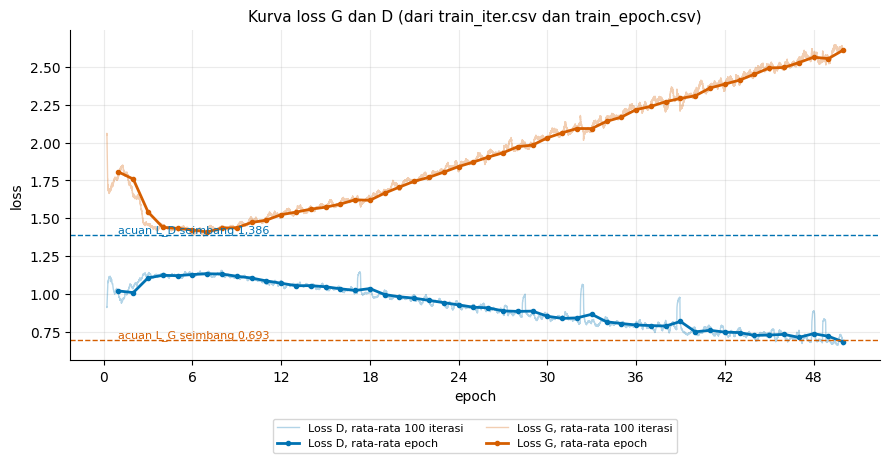

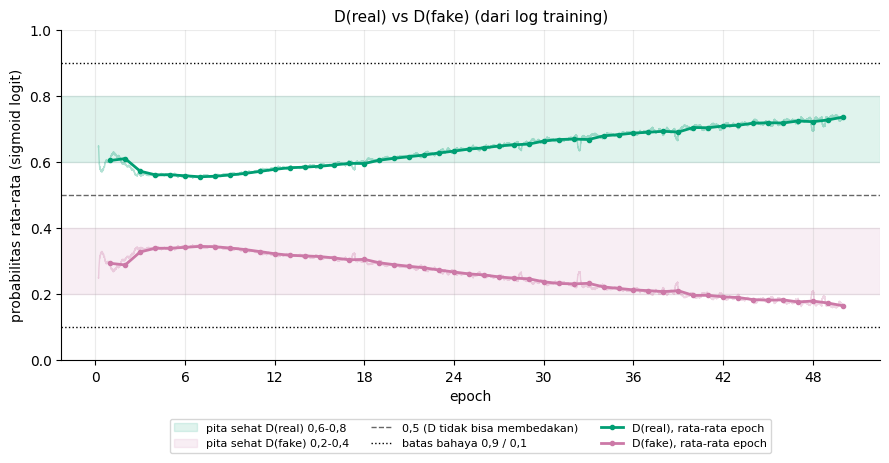

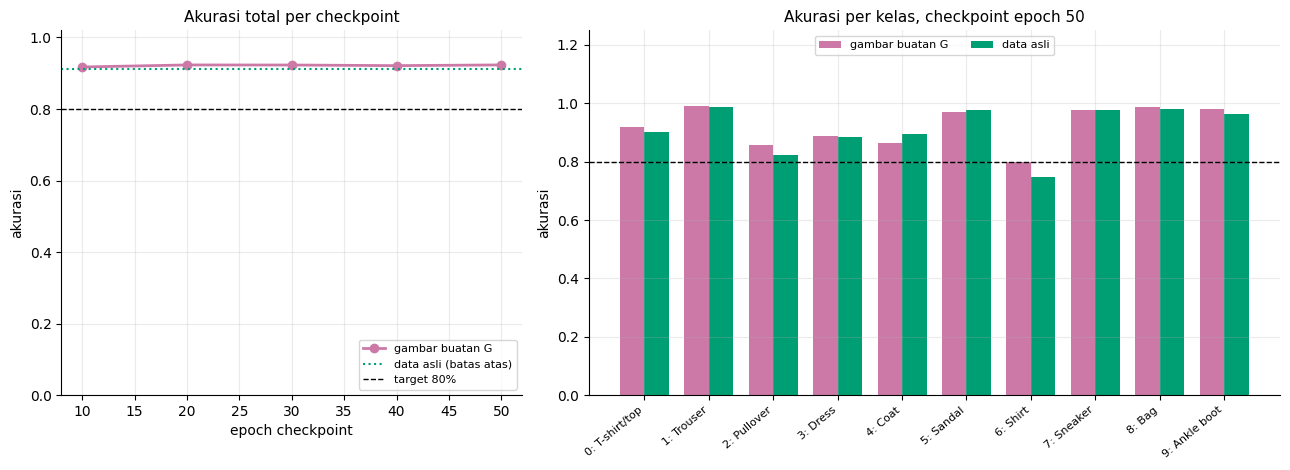

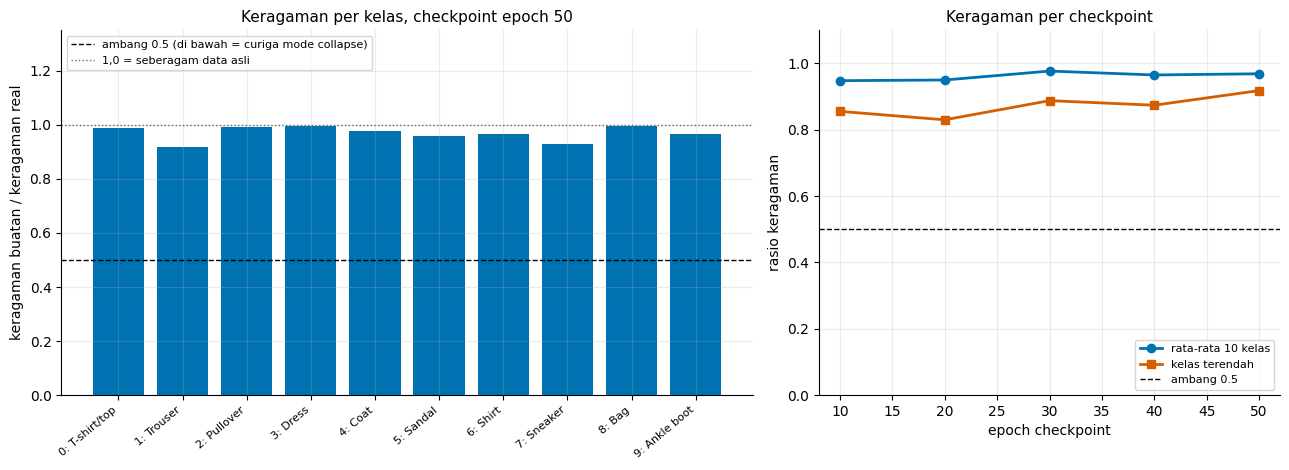

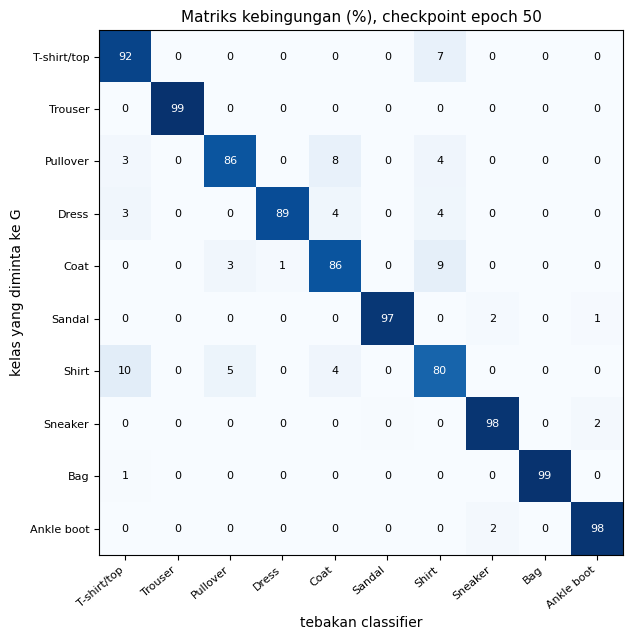

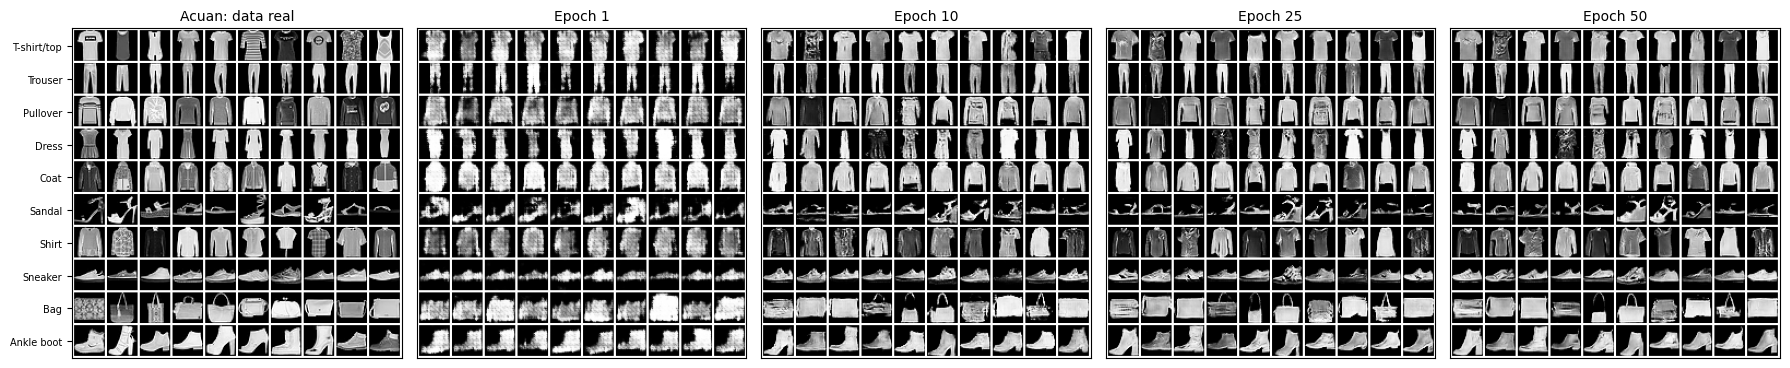


Diagnosis otomatis (ambang dari cetak biru bagian 6, 7, 9):
pemeriksaan                                                          nilai                    ambang  status
------------------------------------------------------------------------------------------------------------
L_D tidak terlalu rendah                                             0.718                    >= 0.6  OK
L_G tidak melonjak                                                   2.550                    <= 3.0  OK
D terlalu yakin (D(real)>=0,9 dan D(fake)<=0,1)           0 epoch berturut                       < 3  OK
D(real), D(fake) di pita sehat                               0.725 / 0.175   (0.6, 0.8) / (0.2, 0.4)  PERHATIAN
Akurasi classifier pada gambar buatan                               92.33%                    >= 80%  OK
Keragaman terendah (rasio buatan/real)                      0.92 (Trouser)                    >= 0.5  OK

Grafik tersimpan di: /content/drive/MyDrive/cgan_fashion_mnist/figures


In [21]:
# Jalankan setelah training selesai (Bagian 6) dan TES 7 lulus. Memakai folder keluaran utama (baseline) di Drive.
# Untuk membandingkan run ablation, beri dirs=run_dirs("nama_run") ke evaluate_all(...).
clf = load_classifier()                    # classifier pendamping Bagian 4 (bobot classifier.pt di Drive), mode eval, beku
ref = compute_real_reference(clf)          # pembanding data asli: akurasi per kelas dan keragaman per kelas
report = evaluate_all(clf=clf, ref=ref)    # CSV + tabel + 6 grafik + diagnosis otomatis


# Bagian 8: Tuning dan Ablation

## 8.1 Membaca hasil baseline (untuk presentasi)

**Hasil baseline 50 epoch:** akurasi classifier pada gambar buatan 91,75% (epoch 10) sampai 92,33% (epoch 50), data asli 91,32%.
Rasio keragaman terendah 0,86-0,92. `L_G` naik dari 1,41 (epoch 8) ke 2,61 (epoch 50), `L_D` turun ke 0,68. D(real) 0,725 dan D(fake) 0,175.

**Kenapa `L_G` naik dan `L_D` turun padahal gambar dan akurasinya bagus?**

- Loss GAN bukan "nilai ujian gambar". Loss itu mengukur **hasil pertandingan antara G dan D saat itu**, dan lawannya ikut belajar.
- Analogi: G murid, D penguji. Penguji makin teliti dan mulai mengenali ciri halus yang tidak terlihat oleh mata maupun classifier.
  Murid makin sering ditolak (`L_G` naik) walaupun jawabannya makin bagus. Penguji makin sering benar (`L_D` turun).
- Angkanya konsisten: D(fake) turun ke 0,175, dan `L_G` = -log D(fake) membesar. Akurasi justru hampir datar sejak epoch 20 (92,3%),
  jadi kenaikan `L_G` sesudahnya tidak diikuti penurunan ketaatan label.
- G tetap belajar karena memakai bentuk non-saturating: selama D(fake) belum mendekati 0, gradien ke G masih mengalir.
  Batas bahaya cetak biru belum dilewati: D(fake) ≤ 0,1, `L_G` > 3, atau `L_D` < 0,6 selama beberapa epoch.
- **Yang belum terbukti:** penjelasan "D makin teliti" adalah tafsir standar, bukan hasil eksperimen kita. Ablation A dan B di bawah
  justru menguji tafsir itu: bila D diperlemah, `L_G` seharusnya turun dan D(fake) naik.
- Alasan tetap waspada: `L_G` naik hampir lurus. Bila training diperpanjang, tren ini bisa menuju zona bahaya.

**Kenapa akurasi gambar buatan (92,33%) bisa sedikit di atas data asli (91,32%)?**

- Classifier hanya mengukur **apakah label ditaati dan gambarnya mudah dikenali**, bukan apakah gambarnya "lebih bagus dari aslinya".
- Dugaan utama: gambar G cenderung **prototipikal**, yaitu mengumpul di bentuk khas tiap kelas. Test set asli memuat gambar ambigu
  (kemeja yang mirip T-shirt, mantel yang mirip pullover) dan label yang kadang bisa diperdebatkan. Dugaan ini didukung hasil kita:
  kelas tersulit, Shirt, justru punya selisih terbesar (asli 74,9%, buatan 80,0%), dan rasio keragaman di bawah atau dekat 1.
- Faktor kedua: D menerima label sebagai kanal tambahan dan menolak pasangan yang tidak cocok, sehingga G cenderung menonjolkan ciri pembeda kelas.
- Besar selisihnya kecil: 1,0 poin persentase dengan 10.000 gambar per sisi (galat baku ±0,27 poin per sisi). Kemungkinan nyata, tetapi jangan diklaim berlebihan.
- Dugaan "prototipikal" bisa dicek: sel 8.6 membandingkan **keyakinan** classifier pada gambar real vs buatan. Bila gambar buatan lebih diyakini, dugaan itu terdukung.
- Karena akurasi sudah 91,75% di epoch 10, metrik ini tidak cukup tajam untuk membedakan checkpoint. Baca bersama grid dan keragaman.

## 8.2 Rancangan eksperimen

Aturan cetak biru bagian 6 dan 9: **satu perubahan per run**, hasil baseline disimpan utuh, setiap perubahan dicatat dengan alasan dan hasilnya.
Baseline sudah memenuhi target (akurasi ≥ 80%, keragaman ≥ 0,5, tidak melewati ambang bahaya), jadi run ini adalah **ablation**
(bahan perbandingan sebelum/sesudah), bukan perbaikan darurat.

| Run | Perubahan | Dasar di cetak biru | Prediksi yang diuji |
| --- | --- | --- | --- |
| A | `CFG.d_dropout = 0.3` | Cadangan 1 (bagian 6): sebagian fitur D dibuang acak, D tidak selalu yakin | D(fake) naik ke arah 0,2-0,4, `L_G` turun. Akurasi dan keragaman berubah kecil |
| B | `CFG.lr_d = 1e-4` (lr G tetap 2e-4) | Bagian 9, "D terlalu kuat", langkah 2 | D belajar lebih lambat: D(fake) naik, `L_G` turun. Efek ke gambar belum pasti |

**Kriteria dinilai sebelum dijalankan:** sebuah run baru layak disebut lebih baik bila akurasi dan keragaman **tidak turun di luar kebisingan**
dan grid tidak lebih buruk. Loss yang membaik saja tidak cukup. Bila hasilnya tidak berbeda dari baseline di dalam kebisingan,
itu temuan yang sah: "baseline sudah cukup".

**Cara kerja mesin eksperimen**

| Komponen | Fungsi |
| --- | --- |
| `cfg_override(**perubahan)` | Mengubah `CFG` hanya selama training, lalu mengembalikan nilai asli, juga saat error atau training dihentikan |
| `assert_baseline_cfg()` | Menolak run bila `CFG` bukan baseline; mencegah perubahan tersembunyi |
| `run_ablation(...)` | Menolak lebih dari satu perubahan, melatih di `runs/<nama>/`, mengembalikan `CFG`, lalu `evaluate_all` dengan `clf` dan `ref` yang sama dengan baseline |
| `compare_runs()` | Tabel, kurva, dan grid epoch 50 berdampingan, semuanya dibaca dari log dan CSV |
| Batas kebisingan | Selisih akurasi dibandingkan dengan 2 x galat baku sampling (√(p(1-p)/n)). Variasi antar-seed tidak terukur dari satu run per konfigurasi |

Bobot awal G dan D sama di semua run (seed sama, dropout tidak memakai angka acak saat konstruksi), jadi perbandingannya adil di titik awal.

## 8.3 Perkiraan waktu (T4)

| Langkah | Perkiraan |
| --- | --- |
| Satu run (50 epoch x ±18 dtk) | ±15-16 menit (dropout kemungkinan sedikit lebih lambat; belum diukur) |
| Evaluasi satu run (5 checkpoint x 10.000 gambar + 6 grafik) | kurang dari 1 menit |
| Run A + run B | ±31-33 menit |
| Perbandingan (sel 8.5) dan keyakinan classifier (sel 8.6) | beberapa detik |
| Ruang Drive | ±100 MB per run |

Jalankan sel A dan sel B **terpisah**. Bila sesi Colab terputus, jalankan ulang sel yang sama: checkpoint terbaru di folder run itu
ditemukan otomatis dan training dilanjutkan, dan log dipotong sampai epoch checkpoint.

In [22]:
# Bagian 8 memakai import Bagian 0, 6, dan 7. Satu import tambahan:
from contextlib import contextmanager
from dataclasses import fields

# Nilai baseline yang WAJIB berlaku saat sebuah run ablation dimulai (cetak biru bagian 2, 3, 5, 6).
# Tujuannya: bila CFG tanpa sengaja sudah berubah (mis. sel eksperimen sebelumnya terhenti), run berikutnya
# tidak diam-diam membawa dua perubahan sekaligus dan melanggar aturan "satu perubahan per run".
BASELINE_HPARAMS = dict(lr_g=2e-4, lr_d=2e-4, beta1=0.5, beta2=0.999, weight_decay=0.0, epochs=50,
                        d_steps=1, g_steps=1, real_target=0.9, fake_target=0.0, g_target=1.0,
                        d_dropout=0.0, d_spectral_norm=False)

# Daftar eksperimen. Tiap eksperimen mengubah TEPAT SATU field CFG. Nama folder hanya boleh huruf, angka, '_' dan '-'.
EXPERIMENTS = {
    "A": dict(name="A_dropout_0p3", label="A: dropout D 0.3", changes={"d_dropout": 0.3}),     # cadangan 1 (bagian 6)
    "B": dict(name="B_lr_d_1e-4", label="B: lr D 1e-4", changes={"lr_d": 1e-4}),               # langkah 2 risiko "D terlalu kuat" (bagian 9)
}


def assert_baseline_cfg() -> None:
    """ValueError bila CFG sekarang bukan baseline. Dipanggil sebelum setiap run ablation."""
    off = [f"{k}: sekarang {getattr(CFG, k)!r}, baseline {v!r}" for k, v in BASELINE_HPARAMS.items() if getattr(CFG, k) != v]
    if off:
        raise ValueError("CFG bukan baseline, run ablation dibatalkan agar tidak membawa perubahan tersembunyi:\n  "
                         + "\n  ".join(off))


@contextmanager
def cfg_override(**changes):
    """Ubah CFG sementara di dalam blok `with`. Nilai asli SELALU dikembalikan, juga bila training error atau dihentikan."""
    allowed = {f.name for f in fields(CFG)}        # hanya field asli; properti turunan (d_embed_dim, ...) tidak boleh diubah
    unknown = [k for k in changes if k not in allowed]
    if unknown:
        raise ValueError(f"bukan field CFG: {unknown}")
    old = {k: getattr(CFG, k) for k in changes}
    try:
        for k, v in changes.items():
            setattr(CFG, k, v)
        yield
    finally:                                       # dijalankan apa pun yang terjadi di dalam blok
        for k, v in old.items():
            setattr(CFG, k, v)


def run_ablation(name: str, changes: dict, label: str = None, clf=None, ref: dict = None,
                 train_kwargs: dict = None, eval_kwargs: dict = None) -> RunDirs:
    """Satu run ablation: ubah SATU hyperparameter -> latih di folder sendiri -> kembalikan CFG -> evaluasi.

    clf dan ref harus objek yang SAMA dengan yang dipakai evaluasi baseline (classifier dan pembanding data asli),
    supaya selisih akurasi/keragaman murni berasal dari perubahan hyperparameter.
    train_kwargs / eval_kwargs: diteruskan ke train() / evaluate_all() (dipakai tes untuk run mini).
    """
    if len(changes) != 1:
        raise ValueError(f"satu perubahan per run (cetak biru bagian 6), diterima {len(changes)}: {list(changes)}")
    (key, value), = changes.items()
    assert_baseline_cfg()                          # jaring pengaman: CFG harus bersih sebelum diubah
    if getattr(CFG, key) == value:
        raise ValueError(f"{key}={value!r} sama dengan baseline: itu bukan perubahan")
    if clf is None or ref is None:
        raise ValueError("clf dan ref wajib diberikan (pakai objek yang sama dengan evaluasi baseline di Bagian 7)")
    label = name if label is None else label

    dirs = run_dirs(name)                          # folder terpisah: runs/<name>/; baseline tidak tersentuh
    print(f"=== {label}: {key} {getattr(CFG, key)!r} -> {value!r} | folder: {os.path.dirname(dirs.ckpt)} ===")
    t0 = time.perf_counter()
    with cfg_override(**changes):                  # perubahan hanya berlaku selama training
        train(dirs=dirs, **(train_kwargs or {}))   # bila folder run ini sudah berisi checkpoint, otomatis lanjut
    assert_baseline_cfg()                          # bukti: CFG sudah kembali ke baseline
    print(f"Training selesai dalam {(time.perf_counter() - t0) / 60:.1f} menit. CFG dikembalikan ke baseline "
          f"({key} = {getattr(CFG, key)!r}). Mulai evaluasi...")
    evaluate_all(dirs, clf, ref, **(eval_kwargs or {}))     # evaluasi memakai G saja, jadi CFG baseline cocok
    return dirs


# ---------------------------------------------------------------------------
# Perbandingan antar-run
# ---------------------------------------------------------------------------
RUN_STYLE = [("#0072B2", "-"), ("#D55E00", "--"), ("#009E73", ":"), ("#CC79A7", "-.")]   # warna DAN gaya garis: terbaca tanpa warna


def existing_run_dirs(run_name: str = None) -> RunDirs:
    """Sama seperti run_dirs, tetapi TIDAK membuat folder (untuk membaca run yang mungkin belum dijalankan)."""
    if run_name is None:
        return RunDirs(CFG.ckpt_dir, CFG.sample_dir, CFG.log_dir)
    root = os.path.join(CFG.out_root, "runs", run_name)
    return RunDirs(os.path.join(root, "checkpoints"), os.path.join(root, "samples"), os.path.join(root, "logs"))


def default_runs() -> dict:
    """{label: RunDirs}: baseline di folder utama, lalu semua eksperimen di EXPERIMENTS."""
    runs = {"baseline": existing_run_dirs()}
    runs.update({e["label"]: existing_run_dirs(e["name"]) for e in EXPERIMENTS.values()})
    return runs


def summarize_run(dirs: RunDirs, label: str) -> dict:
    """Ringkasan satu run, seluruhnya dari file log/CSV: metrik evaluasi checkpoint terakhir + loss/D(.) akhir."""
    _, ep = load_training_logs(dirs)
    s = read_table(os.path.join(dirs.log, EVAL_CFG.summary_name), SUMMARY_FIELDS)
    p = read_table(os.path.join(dirs.log, EVAL_CFG.per_class_name), PER_CLASS_FIELDS)
    c = read_table(os.path.join(dirs.log, EVAL_CFG.confusion_name), CONFUSION_FIELDS)
    tail = EVAL_CFG.tail_epochs                                   # definisi "akhir" sama dengan diagnosis Bagian 7
    last_ckpt = int(s["epoch"][-1])
    status = [r["status"] for r in diagnose(ep, s, p)]
    return {
        "label": label, "epochs": int(ep["epoch"][-1]), "ckpt_epoch": last_ckpt,
        "acc": float(s["acc_total"][-1]), "acc_real": float(s["acc_real_total"][-1]),
        "n_eval": int(c["count"][c["epoch"] == last_ckpt].sum()),   # jumlah gambar buatan yang dinilai (untuk galat baku)
        "ratio_min": float(s["div_ratio_min"][-1]), "ratio_min_class": int(s["div_ratio_min_class"][-1]),
        "loss_D": float(np.mean(ep["loss_D"][-tail:])), "loss_G": float(np.mean(ep["loss_G"][-tail:])),
        "d_real": float(np.mean(ep["d_real"][-tail:])), "d_fake": float(np.mean(ep["d_fake"][-tail:])),
        "n_waspada": status.count("WASPADA"), "n_perhatian": status.count("PERHATIAN"),
    }


def acc_se(p: float, n: int) -> float:
    """Galat baku akurasi akibat pengambilan sampel gambar: sqrt(p(1-p)/n). Hanya kebisingan evaluasi, bukan variasi antar-seed training."""
    return math.sqrt(p * (1 - p) / n)


COMPARE_FIELDS = ("run", "epoch_terakhir", "acc_total", "rasio_keragaman_min", "kelas_keragaman_min",
                  "loss_D_akhir", "loss_G_akhir", "d_real_akhir", "d_fake_akhir", "n_waspada", "n_perhatian")


def print_comparison(rows: list) -> None:
    """Satu tabel perbandingan, lalu selisih terhadap baseline dengan batas kebisingan sampling."""
    print(f"{'run':<20}{'epoch':>6}{'akurasi':>10}{'rasio kergm.':>14}{'L_D':>8}{'L_G':>8}{'D(real)':>9}{'D(fake)':>9}{'W/P':>7}")
    print("-" * 91)
    for r in rows:
        print(f"{r['label']:<20}{r['ckpt_epoch']:>6}{r['acc']:>10.2%}{r['ratio_min']:>14.2f}{r['loss_D']:>8.3f}"
              f"{r['loss_G']:>8.3f}{r['d_real']:>9.3f}{r['d_fake']:>9.3f}{str(r['n_waspada']) + '/' + str(r['n_perhatian']):>7}")
    print("akurasi & rasio keragaman terendah: checkpoint terakhir. L_D, L_G, D(real), D(fake): rata-rata "
          f"{EVAL_CFG.tail_epochs} epoch terakhir. W/P: jumlah pemeriksaan WASPADA/PERHATIAN pada diagnosis otomatis.")
    base = rows[0]
    print(f"\nSelisih terhadap {base['label']}:")
    for r in rows[1:]:
        se = math.sqrt(acc_se(base["acc"], base["n_eval"]) ** 2 + acc_se(r["acc"], r["n_eval"]) ** 2)
        d_acc = r["acc"] - base["acc"]
        verdict = "di dalam kebisingan sampling" if abs(d_acc) < 2 * se else "di luar kebisingan sampling"
        print(f"  {r['label']:<20} akurasi {100 * d_acc:+.2f} pp (batas 2 x galat baku = {200 * se:.2f} pp: {verdict}) | "
              f"rasio min {r['ratio_min'] - base['ratio_min']:+.2f} | L_D {r['loss_D'] - base['loss_D']:+.3f} | "
              f"L_G {r['loss_G'] - base['loss_G']:+.3f} | D(real) {r['d_real'] - base['d_real']:+.3f} | "
              f"D(fake) {r['d_fake'] - base['d_fake']:+.3f}")
    print("Catatan: galat baku hanya memuat kebisingan pengambilan sampel gambar. Variasi antar-run (seed training berbeda) "
          "tidak terukur dari satu run per konfigurasi, jadi selisih kecil jangan dibaca sebagai efek nyata.")


def plot_ablation_curves(runs: dict, out_dir: str, show: bool = True):
    """Kurva epoch keempat besaran (L_D, L_G, D(real), D(fake)) dari semua run dalam satu gambar."""
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
    panels = (("loss_D", "Loss D (L_D)", 2 * math.log(2)), ("loss_G", "Loss G (L_G)", math.log(2)),
              ("d_real", "D(real)", None), ("d_fake", "D(fake)", None))
    for ax, (key, title, ref_value) in zip(axes.flat, panels):
        for (label, dirs), (color, ls) in zip(runs.items(), RUN_STYLE):
            _, ep = load_training_logs(dirs)
            ax.plot(ep["epoch"], ep[key], color=color, ls=ls, lw=2, label=label)
        if ref_value is not None:
            ax.axhline(ref_value, color=COLORS["grey"], lw=1, ls=(0, (1, 3)))      # acuan seimbang
        style_axes(ax, "epoch" if key in ("d_real", "d_fake") else "", "", title)
    axes[1, 0].axhspan(*EVAL_CFG.healthy_d_real, color=COLORS["real"], alpha=0.12)  # pita sehat
    axes[1, 1].axhspan(*EVAL_CFG.healthy_d_fake, color=COLORS["fake"], alpha=0.12)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), fontsize=9, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Perbandingan kurva training: baseline vs ablation", fontsize=12)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    os.makedirs(out_dir, exist_ok=True)
    fig.savefig(os.path.join(out_dir, "ablation_curves.png"), dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    return fig


def plot_ablation_grids(runs: dict, summaries: dict, out_dir: str, epoch: int = None, show: bool = True):
    """Grid sampel (noise tetap) pada epoch yang sama dari semua run, berdampingan dengan grid acuan real. Dibaca dari PNG."""
    epoch = CFG.epochs if epoch is None else epoch
    panels = []
    real_path = os.path.join(CFG.sample_dir, EVAL_CFG.real_grid_name)
    if os.path.isfile(real_path):
        panels.append(("Acuan: data real", real_path))
    for label, dirs in runs.items():
        path = os.path.join(dirs.sample, TRAIN_CFG.sample_name.format(epoch=epoch))
        if not os.path.isfile(path):
            raise FileNotFoundError(f"grid epoch {epoch} tidak ada untuk '{label}': {path}")
        s = summaries[label]
        panels.append((f"{label}\nakurasi {s['acc']:.1%}, rasio keragaman min {s['ratio_min']:.2f}", path))
    fig, axes = plt.subplots(1, len(panels), figsize=(3.7 * len(panels), 4.6), squeeze=False)
    pad, cell = 2, CFG.img_size + 2                           # tata letak make_grid padding=2 (save_image_grid Bagian 1)
    for k, (ax, (title, path)) in enumerate(zip(axes[0], panels)):
        ax.imshow(np.asarray(Image.open(path)))
        ax.set_title(title, fontsize=9)
        ax.set_xticks([])
        if k == 0:
            ax.set_yticks([pad + i * cell + CFG.img_size / 2 for i in range(CFG.num_classes)])
            ax.set_yticklabels(CLASS_NAMES, fontsize=7)
        else:
            ax.set_yticks([])
    fig.suptitle(f"Grid sampel epoch {epoch} (noise tetap sama di semua run)", fontsize=11)
    fig.tight_layout()
    os.makedirs(out_dir, exist_ok=True)
    fig.savefig(os.path.join(out_dir, f"ablation_grid_epoch{epoch:03d}.png"), dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    return fig


def compare_runs(runs: dict = None, epoch: int = None, out_dir: str = None, show: bool = True) -> list:
    """Tabel perbandingan + kurva + grid berdampingan. Run yang belum dijalankan dilewati dengan catatan."""
    runs = default_runs() if runs is None else runs
    out_dir = os.path.join(CFG.out_root, "ablation") if out_dir is None else out_dir
    ready, summaries = {}, {}
    for label, dirs in runs.items():
        try:
            summaries[label] = summarize_run(dirs, label)
            ready[label] = dirs
        except FileNotFoundError:
            print(f"Dilewati: '{label}' belum punya log/evaluasi lengkap di {os.path.dirname(dirs.log)}")
    if len(ready) < 2:
        raise ValueError("butuh minimal 2 run yang sudah selesai dan dievaluasi (baseline + satu ablation)")
    rows = list(summaries.values())
    print_comparison(rows)
    write_csv(os.path.join(out_dir, "ablation_comparison.csv"), COMPARE_FIELDS,
              [[r["label"], r["ckpt_epoch"], r["acc"], r["ratio_min"], r["ratio_min_class"], r["loss_D"], r["loss_G"],
                r["d_real"], r["d_fake"], r["n_waspada"], r["n_perhatian"]] for r in rows])
    plot_ablation_curves(ready, out_dir, show)
    plot_ablation_grids(ready, summaries, out_dir, epoch, show)
    print(f"\nTabel (CSV) dan grafik tersimpan di: {out_dir}")
    return rows


# ---------------------------------------------------------------------------
# Pemeriksaan hipotesis: kenapa akurasi gambar buatan bisa >= data asli?
# ---------------------------------------------------------------------------
@torch.no_grad()
def classifier_confidence(clf, x: torch.Tensor, batch: int = 1000) -> float:
    """Rata-rata keyakinan classifier = probabilitas kelas tertinggi (softmax), atas gambar x [N,1,28,28]."""
    probs = [torch.softmax(clf(x[i:i + batch].to(DEVICE)), dim=1).max(1).values.cpu() for i in range(0, x.size(0), batch)]
    return torch.cat(probs).mean().item()


def compare_confidence(clf, dirs: RunDirs = None, epoch: int = None) -> dict:
    """Keyakinan classifier pada gambar real (test set) vs gambar buatan, per kelas. Mendukung/menyangkal dugaan
    bahwa gambar buatan 'lebih prototipikal' (lebih mudah ditebak) daripada data asli yang beragam."""
    dirs = run_dirs() if dirs is None else dirs
    epoch = _ckpt_epochs(dirs.ckpt)[-1] if epoch is None else epoch
    G = load_generator(ckpt_path(epoch, dirs.ckpt))
    ds = get_dataset(train=False)
    rows = []
    for c in range(CFG.num_classes):
        idx = torch.nonzero(ds.targets == c).flatten()
        x_real = ((ds.data[idx].float() / 255.0 - CFG.norm_mean) / CFG.norm_std).unsqueeze(1)   # rumus transform Bagian 3
        x_fake = sample_from_generator(G, c, len(idx), EVAL_CFG.eval_seed)                       # jumlah sama dengan real
        rows.append((c, classifier_confidence(clf, x_real), classifier_confidence(clf, x_fake)))
    print(f"Keyakinan classifier (probabilitas tertinggi), checkpoint epoch {epoch}")
    print(f"{'kelas':<16}{'real':>10}{'buatan':>10}")
    print("-" * 36)
    for c, r, f in rows:
        print(f"{c}: {CLASS_NAMES[c]:<13}{r:>10.3f}{f:>10.3f}")
    mean_r, mean_f = float(np.mean([r for _, r, _ in rows])), float(np.mean([f for _, _, f in rows]))
    print("-" * 36)
    print(f"{'rata-rata':<16}{mean_r:>10.3f}{mean_f:>10.3f}")
    return {"rows": rows, "mean_real": mean_r, "mean_fake": mean_f}

In [23]:
import tempfile

# Semua tes memakai folder sementara (CFG.out_root dialihkan lewat cfg_override), jadi Drive tidak tersentuh.
# Run mini: 2 epoch x 20 iterasi. Yang dites adalah mesin eksperimennya, bukan kualitas hasil run mini.
tmp8 = tempfile.TemporaryDirectory()
set_seed(CFG.seed)
clf8 = freeze(Classifier().to(DEVICE))
ref8 = compute_real_reference(clf8, n_per_class=30)
MINI = dict(epochs=2, loader=train_loader, max_iters_per_epoch=20, sample_every=1, ckpt_every=1, progress=False)
EVAL_MINI = dict(n_per_class=30, show=False)

def expect_error(exc_type, fn, what):
    try:
        fn()
    except exc_type:
        return
    raise AssertionError(f"{what} seharusnya memunculkan {exc_type.__name__}")

# --- Tes 8.1: cfg_override mengubah sementara dan SELALU mengembalikan ---
assert_baseline_cfg()                                     # titik awal: CFG = baseline
with cfg_override(lr_d=5.0, d_dropout=0.5):
    assert CFG.lr_d == 5.0 and CFG.d_dropout == 0.5
assert CFG.lr_d == 2e-4 and CFG.d_dropout == 0.0, "nilai asli harus kembali setelah blok selesai"
try:
    with cfg_override(lr_d=5.0):
        raise RuntimeError("training gagal di tengah jalan")
except RuntimeError:
    pass
assert CFG.lr_d == 2e-4, "nilai asli harus kembali walau terjadi error di dalam blok"
with cfg_override(lr_d=1.0):
    with cfg_override(lr_d=2.0):
        assert CFG.lr_d == 2.0
    assert CFG.lr_d == 1.0, "override bersarang harus kembali ke nilai luarnya"
assert CFG.lr_d == 2e-4
expect_error(ValueError, lambda: cfg_override(tidak_ada=1).__enter__(), "field CFG yang tidak ada")
expect_error(ValueError, lambda: cfg_override(d_embed_dim=1).__enter__(), "properti turunan (bukan field)")

# --- Tes 8.2: pagar pengaman run_ablation (semua ditolak SEBELUM training dan sebelum folder dibuat) ---
with cfg_override(out_root=tmp8.name):
    kw = dict(clf=clf8, ref=ref8, train_kwargs=MINI, eval_kwargs=EVAL_MINI)
    expect_error(ValueError, lambda: run_ablation("x_dua", {"d_dropout": 0.3, "lr_d": 1e-4}, **kw), "dua perubahan sekaligus")
    expect_error(ValueError, lambda: run_ablation("x_sama", {"lr_d": 2e-4}, **kw), "nilai sama dengan baseline")
    expect_error(ValueError, lambda: run_ablation("x_tanpa_clf", {"lr_d": 1e-4}, clf=None, ref=None), "tanpa clf dan ref")
    expect_error(ValueError, lambda: run_ablation("../keluar", {"lr_d": 1e-4}, **kw), "nama run berisi path")
    with cfg_override(lr_d=1e-4):                          # CFG sudah tidak baseline
        expect_error(ValueError, lambda: run_ablation("x_kotor", {"d_dropout": 0.3}, **kw), "CFG yang bukan baseline")
    assert not os.path.exists(os.path.join(tmp8.name, "runs")), "pagar pengaman tidak boleh membuat folder run"

    # --- Tes 8.3: perbandingan yang adil: bobot awal D identik dengan atau tanpa dropout (dropout tidak memakai RNG) ---
    set_seed(CFG.seed); D_plain = Discriminator()
    set_seed(CFG.seed)
    with cfg_override(d_dropout=0.3):
        D_drop = Discriminator()
    assert any(isinstance(m, nn.Dropout2d) for m in D_drop.modules())
    assert all(torch.equal(p, q) for p, q in zip(D_plain.parameters(), D_drop.parameters())), "bobot awal D harus sama"

    # --- Tes 8.4: tiga run mini (baseline, A, B), tiap run di folder sendiri ---
    base_dirs = run_dirs("baseline_mini")                  # stand-in baseline di folder sementara
    train(dirs=base_dirs, **MINI)
    evaluate_all(base_dirs, clf8, ref8, **EVAL_MINI)
    dirs_A = run_ablation(**EXPERIMENTS["A"], **kw)
    dirs_B = run_ablation(**EXPERIMENTS["B"], **kw)
    assert_baseline_cfg()                                  # CFG kembali ke baseline setelah dua run
    assert CFG.d_dropout == 0.0 and CFG.lr_d == 2e-4

    folders = {os.path.dirname(d.ckpt) for d in (base_dirs, dirs_A, dirs_B)}
    assert len(folders) == 3, "tiap run harus punya folder sendiri"
    for d in (dirs_A, dirs_B):                             # tiap run punya log, checkpoint, sampel, CSV evaluasi, grafik
        assert sorted(os.listdir(d.ckpt)) == ["ckpt_epoch001.pt", "ckpt_epoch002.pt"]
        assert os.path.exists(os.path.join(d.log, TRAIN_CFG.epoch_log_name))
        assert os.path.exists(os.path.join(d.log, EVAL_CFG.summary_name))
        assert os.path.isdir(fig_dir(d)) and os.listdir(fig_dir(d))

    # --- Tes 8.5: SATU perubahan per run: config di checkpoint A dan B hanya berbeda 1 field dari baseline ---
    load_ck = lambda d: torch.load(ckpt_path(2, d.ckpt), map_location="cpu", weights_only=True)
    ck_base, ck_A, ck_B = load_ck(base_dirs), load_ck(dirs_A), load_ck(dirs_B)
    changed = lambda a, b: {k for k in a["config"] if a["config"][k] != b["config"][k]}
    assert changed(ck_A, ck_base) == {"d_dropout"}, changed(ck_A, ck_base)
    assert changed(ck_B, ck_base) == {"lr_d"}, changed(ck_B, ck_base)
    assert ck_A["config"]["d_dropout"] == 0.3 and ck_B["config"]["lr_d"] == 1e-4
    lr = lambda ck, opt: ck[opt]["param_groups"][0]["lr"]
    assert (lr(ck_B, "opt_D"), lr(ck_B, "opt_G")) == (1e-4, 2e-4), "run B: lr D diturunkan, lr G tetap 2e-4"
    assert (lr(ck_A, "opt_D"), lr(ck_A, "opt_G")) == (2e-4, 2e-4), "run A: kedua lr tetap"
    # State D hasil run A hanya cocok dengan D berdropout (dropout menggeser indeks layer di state_dict).
    with cfg_override(d_dropout=0.3):
        Discriminator().load_state_dict(ck_A["D"])
    expect_error(RuntimeError, lambda: Discriminator().load_state_dict(ck_A["D"]), "D tanpa dropout memuat state D berdropout")

    # --- Tes 8.6: perbandingan: tabel, CSV, kurva, grid; semua dari file ---
    out_dir = os.path.join(tmp8.name, "ablation")
    runs8 = {"baseline": base_dirs, EXPERIMENTS["A"]["label"]: dirs_A, EXPERIMENTS["B"]["label"]: dirs_B}
    rows = compare_runs(runs8, epoch=2, out_dir=out_dir, show=False)
    assert [r["label"] for r in rows] == list(runs8)
    _, ep_b = load_training_logs(base_dirs)
    s_b = read_table(os.path.join(base_dirs.log, EVAL_CFG.summary_name), SUMMARY_FIELDS)
    assert rows[0]["acc"] == s_b["acc_total"][-1] and rows[0]["ratio_min"] == s_b["div_ratio_min"][-1]
    assert np.isclose(rows[0]["loss_D"], np.mean(ep_b["loss_D"][-EVAL_CFG.tail_epochs:])), "'akhir' = rata-rata epoch terakhir dari log"
    assert rows[0]["n_eval"] == 30 * CFG.num_classes and rows[0]["ckpt_epoch"] == 2
    cmp = read_table(os.path.join(out_dir, "ablation_comparison.csv"), COMPARE_FIELDS)
    assert cmp["run"].tolist() == list(runs8) and np.allclose(cmp["acc_total"], [r["acc"] for r in rows])
    for name in ("ablation_curves.png", "ablation_grid_epoch002.png"):
        assert os.path.getsize(os.path.join(out_dir, name)) > 1000, f"{name} tidak tersimpan"
    assert abs(acc_se(0.92, 10_000) - 0.002713) < 1e-5

    fig = plot_ablation_grids(runs8, {r["label"]: r for r in rows}, out_dir, epoch=2, show=False)
    has_real = os.path.isfile(os.path.join(CFG.sample_dir, EVAL_CFG.real_grid_name))
    assert len(fig.axes) == 3 + int(has_real), "satu panel per run (+ grid acuan real bila ada)"
    fig = plot_ablation_curves(runs8, out_dir, show=False)
    ax_ld = fig.axes[0]
    assert len(ax_ld.lines) >= 3 and np.allclose(ax_ld.lines[0].get_ydata(), ep_b["loss_D"]), "kurva baseline = train_epoch.csv"
    expect_error(FileNotFoundError, lambda: plot_ablation_grids(runs8, {r["label"]: r for r in rows}, out_dir, epoch=99, show=False),
                 "grid epoch yang tidak ada")

    # Run yang belum dijalankan dilewati; satu run saja tidak cukup untuk perbandingan.
    ghost = RunDirs(*(os.path.join(tmp8.name, "belum_ada", n) for n in ("checkpoints", "samples", "logs")))
    assert len(compare_runs({**runs8, "C belum jalan": ghost}, epoch=2, out_dir=out_dir, show=False)) == 3
    expect_error(ValueError, lambda: compare_runs({"baseline": base_dirs}, out_dir=out_dir, show=False), "perbandingan satu run")
    plt.close("all")

    # --- Tes 8.7: keyakinan classifier (pemeriksaan hipotesis 'gambar buatan lebih mudah ditebak') ---
    class ConstLogits(nn.Module):
        def forward(self, x):
            out = torch.zeros(x.size(0), CFG.num_classes, device=x.device); out[:, 3] = 1.0
            return out
    conf = compare_confidence(ConstLogits(), base_dirs)
    expected_conf = math.e / (math.e + CFG.num_classes - 1)    # softmax([1,0,...,0]): probabilitas tertinggi
    assert len(conf["rows"]) == CFG.num_classes
    assert abs(conf["mean_real"] - expected_conf) < 1e-5 and abs(conf["mean_fake"] - expected_conf) < 1e-5

assert_baseline_cfg()                                      # akhir tes: CFG tetap baseline
tmp8.cleanup()
print("TES 8 LULUS")

Mulai training baru dari epoch 1.
Device cuda | epoch 1-2 | 20 iterasi/epoch | dropout D=0.0 | spectral norm D=False
Epoch   1/2 | L_G 2.903 | L_D 0.624 | D(real) 0.766 | D(fake) 0.138 | 0.8 dtk
           checkpoint disimpan: ckpt_epoch001.pt
Epoch   2/2 | L_G 2.162 | L_D 0.823 | D(real) 0.674 | D(fake) 0.219 | 0.7 dtk
           checkpoint disimpan: ckpt_epoch002.pt
Training selesai.
epoch   1 | akurasi 10.00% | rasio keragaman min 0.08 (kelas 8: Bag)
epoch   2 | akurasi 17.67% | rasio keragaman min 0.28 (kelas 8: Bag)
Evaluasi 2 checkpoint selesai dalam 0.1 dtk (30 gambar/kelas, seed 43). CSV di /tmp/tmpux40h8_y/runs/baseline_mini/logs

 epoch   akurasi            kelas terendah  rasio kergm. rata2  rasio kergm. min
--------------------------------------------------------------------------------
     1    10.00%                Trouser 0%                0.12              0.08
     2    17.67%            T-shirt/top 0%                0.37              0.28
(akurasi classifier pada dat

/tmp/ipykernel_867/3528803300.py:185: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, len(panels), figsize=(3.7 * len(panels), 4.6), squeeze=False)


Dilewati: 'C belum jalan' belum punya log/evaluasi lengkap di /tmp/tmpux40h8_y/belum_ada
run                  epoch   akurasi  rasio kergm.     L_D     L_G  D(real)  D(fake)    W/P
-------------------------------------------------------------------------------------------
baseline                 2    17.67%          0.28   0.724   2.532    0.720    0.179    2/1
A: dropout D 0.3         2    12.33%          0.25   0.823   2.313    0.691    0.207    2/0
B: lr D 1e-4             2    17.67%          0.27   0.809   1.895    0.664    0.236    2/0
akurasi & rasio keragaman terendah: checkpoint terakhir. L_D, L_G, D(real), D(fake): rata-rata 5 epoch terakhir. W/P: jumlah pemeriksaan WASPADA/PERHATIAN pada diagnosis otomatis.

Selisih terhadap baseline:
  A: dropout D 0.3     akurasi -5.33 pp (batas 2 x galat baku = 5.81 pp: di dalam kebisingan sampling) | rasio min -0.03 | L_D +0.100 | L_G -0.219 | D(real) -0.029 | D(fake) +0.028
  B: lr D 1e-4         akurasi +0.00 pp (batas 2 x galat baku 

=== A: dropout D 0.3: d_dropout 0.0 -> 0.3 | folder: /content/drive/MyDrive/cgan_fashion_mnist/runs/A_dropout_0p3 ===
Mulai training baru dari epoch 1.
Device cuda | epoch 1-50 | 468 iterasi/epoch | dropout D=0.3 | spectral norm D=False


Epoch 1/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch   1/50 | L_G 1.657 | L_D 1.163 | D(real) 0.569 | D(fake) 0.328 | 18.5 dtk


Epoch 2/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch   2/50 | L_G 1.635 | L_D 1.123 | D(real) 0.581 | D(fake) 0.315 | 18.7 dtk


Epoch 3/50:   0%|          | 0/468 [00:00<?, ?it/s]

... (91 outputs left out)

Epoch 49/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch  49/50 | L_G 1.408 | L_D 1.144 | D(real) 0.563 | D(fake) 0.335 | 18.7 dtk


Epoch 50/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch  50/50 | L_G 1.414 | L_D 1.143 | D(real) 0.565 | D(fake) 0.335 | 19.1 dtk
           checkpoint disimpan: ckpt_epoch050.pt
Training selesai.
Training selesai dalam 15.6 menit. CFG dikembalikan ke baseline (d_dropout = 0.0). Mulai evaluasi...
epoch  10 | akurasi 92.55% | rasio keragaman min 0.79 (kelas 7: Sneaker)
epoch  20 | akurasi 92.29% | rasio keragaman min 0.79 (kelas 1: Trouser)
epoch  30 | akurasi 93.33% | rasio keragaman min 0.87 (kelas 1: Trouser)
epoch  40 | akurasi 93.55% | rasio keragaman min 0.82 (kelas 1: Trouser)
epoch  50 | akurasi 93.14% | rasio keragaman min 0.85 (kelas 7: Sneaker)
Evaluasi 5 checkpoint selesai dalam 2.6 dtk (1000 gambar/kelas, seed 43). CSV di /content/drive/MyDrive/cgan_fashion_mnist/runs/A_dropout_0p3/logs

 epoch   akurasi            kelas terendah  rasio kergm. rata2  rasio kergm. min
--------------------------------------------------------------------------------
    10    92.55%                 Shirt 77%                0.92              0

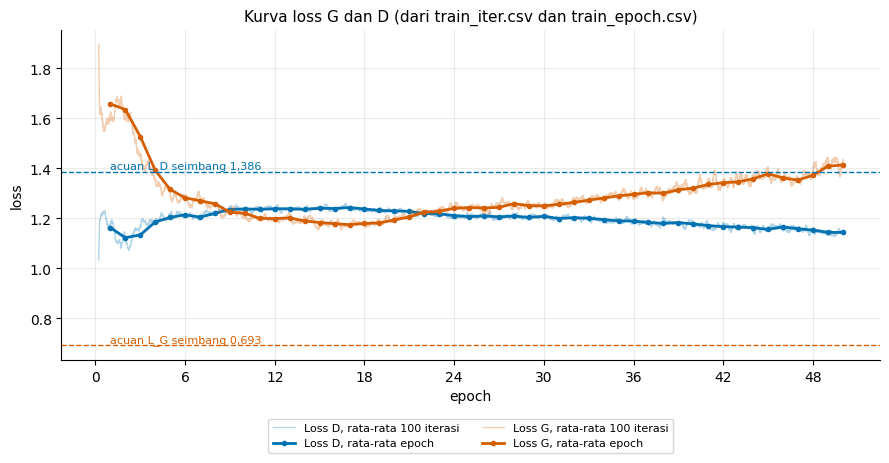

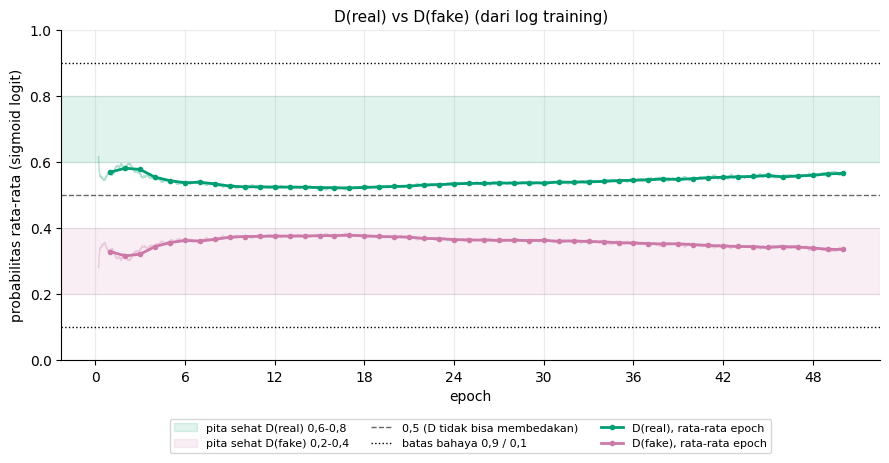

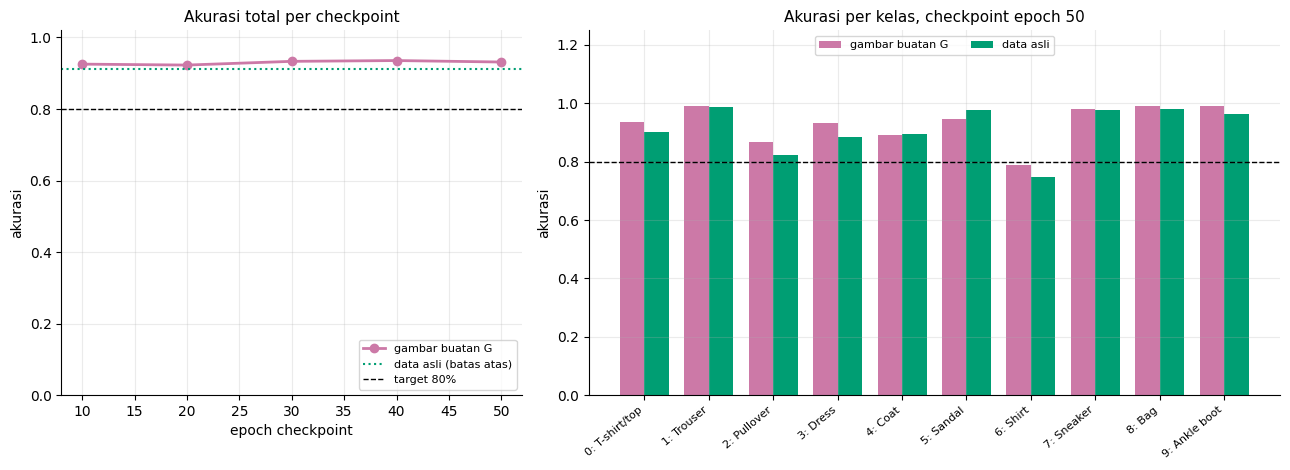

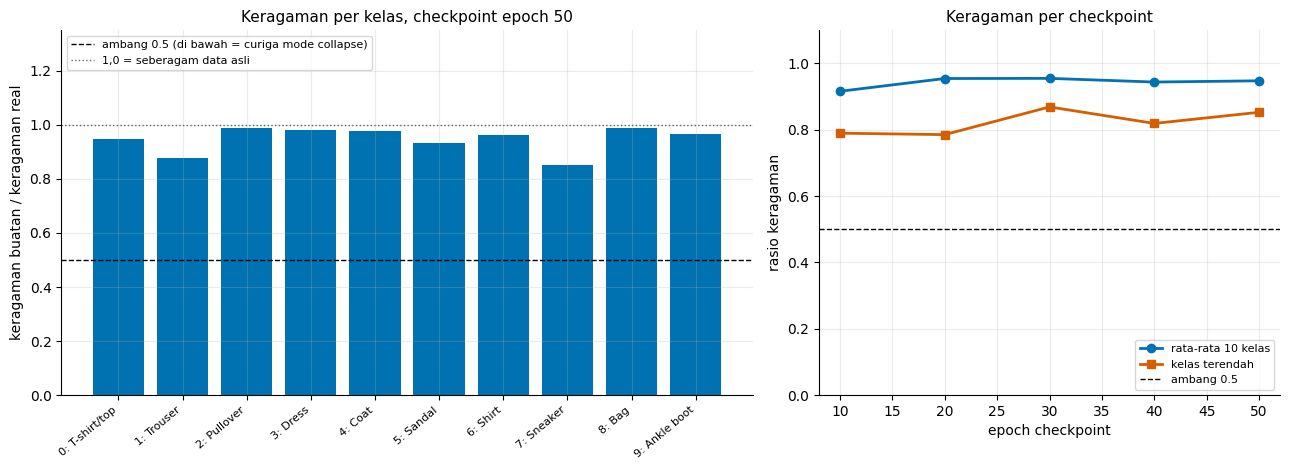

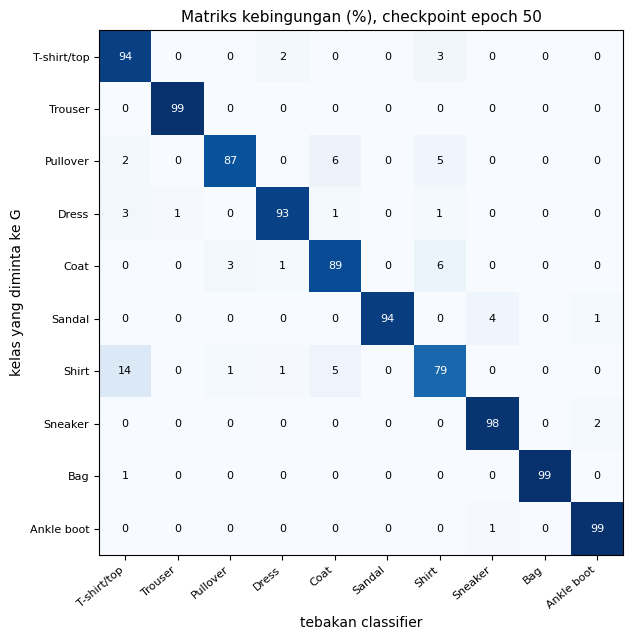

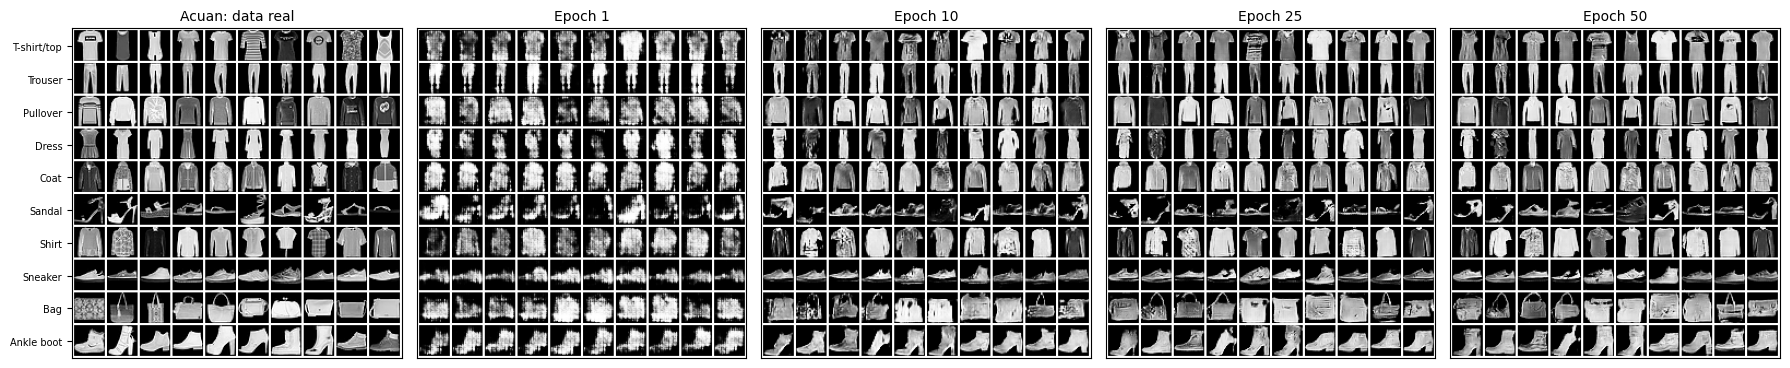


Diagnosis otomatis (ambang dari cetak biru bagian 6, 7, 9):
pemeriksaan                                                          nilai                    ambang  status
------------------------------------------------------------------------------------------------------------
L_D tidak terlalu rendah                                             1.153                    >= 0.6  OK
L_G tidak melonjak                                                   1.382                    <= 3.0  OK
D terlalu yakin (D(real)>=0,9 dan D(fake)<=0,1)           0 epoch berturut                       < 3  OK
D(real), D(fake) di pita sehat                               0.560 / 0.339   (0.6, 0.8) / (0.2, 0.4)  PERHATIAN
Akurasi classifier pada gambar buatan                               93.14%                    >= 80%  OK
Keragaman terendah (rasio buatan/real)                      0.85 (Sneaker)                    >= 0.5  OK

Grafik tersimpan di: /content/drive/MyDrive/cgan_fashion_mnist/runs/A_dropout_0p3/f

In [24]:
# Run A (cadangan 1): Dropout2d(0.3) di D. Perkiraan ±15-16 menit di T4 (50 epoch x ±18 dtk) + evaluasi kurang dari 1 menit.
# Butuh `clf` dan `ref` dari sel run Bagian 7 (classifier dan pembanding data asli yang SAMA dengan evaluasi baseline).
# Bila sesi terputus, jalankan ulang sel ini: training dilanjutkan dari checkpoint terbaru di folder run A.
dirs_A = run_ablation(**EXPERIMENTS["A"], clf=clf, ref=ref)

=== B: lr D 1e-4: lr_d 0.0002 -> 0.0001 | folder: /content/drive/MyDrive/cgan_fashion_mnist/runs/B_lr_d_1e-4 ===
Mulai training baru dari epoch 1.
Device cuda | epoch 1-50 | 468 iterasi/epoch | dropout D=0.0 | spectral norm D=False


Epoch 1/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch   1/50 | L_G 1.450 | L_D 1.106 | D(real) 0.558 | D(fake) 0.340 | 18.5 dtk


Epoch 2/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch   2/50 | L_G 1.454 | L_D 1.087 | D(real) 0.569 | D(fake) 0.328 | 19.0 dtk


Epoch 3/50:   0%|          | 0/468 [00:00<?, ?it/s]

... (91 outputs left out)

Epoch 49/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch  49/50 | L_G 1.765 | L_D 0.896 | D(real) 0.640 | D(fake) 0.260 | 18.2 dtk


Epoch 50/50:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch  50/50 | L_G 1.793 | L_D 0.891 | D(real) 0.643 | D(fake) 0.257 | 19.1 dtk
           checkpoint disimpan: ckpt_epoch050.pt
Training selesai.
Training selesai dalam 15.3 menit. CFG dikembalikan ke baseline (lr_d = 0.0002). Mulai evaluasi...
epoch  10 | akurasi 91.08% | rasio keragaman min 0.84 (kelas 7: Sneaker)
epoch  20 | akurasi 92.58% | rasio keragaman min 0.84 (kelas 1: Trouser)
epoch  30 | akurasi 91.27% | rasio keragaman min 0.90 (kelas 1: Trouser)
epoch  40 | akurasi 92.99% | rasio keragaman min 0.87 (kelas 1: Trouser)
epoch  50 | akurasi 91.78% | rasio keragaman min 0.86 (kelas 7: Sneaker)
Evaluasi 5 checkpoint selesai dalam 2.3 dtk (1000 gambar/kelas, seed 43). CSV di /content/drive/MyDrive/cgan_fashion_mnist/runs/B_lr_d_1e-4/logs

 epoch   akurasi            kelas terendah  rasio kergm. rata2  rasio kergm. min
--------------------------------------------------------------------------------
    10    91.08%              Pullover 63%                0.93              0.84


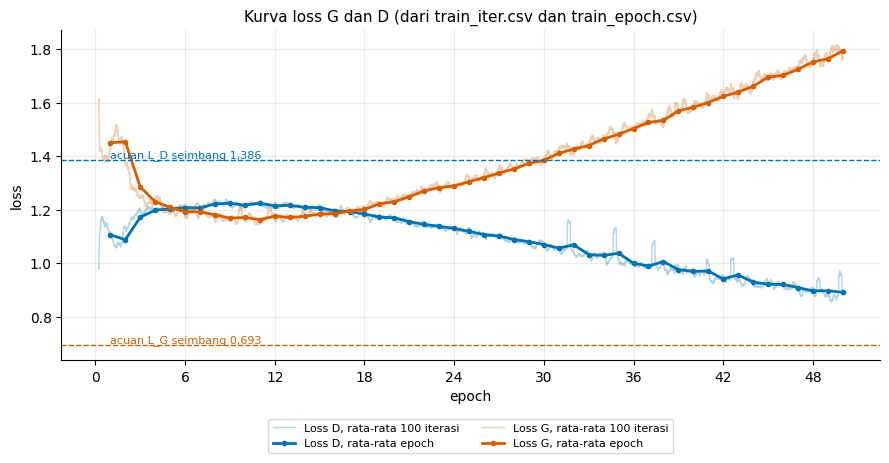

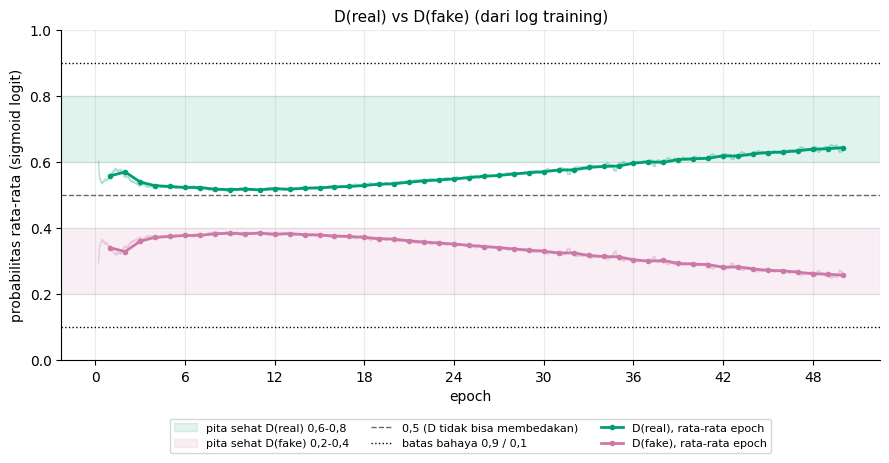

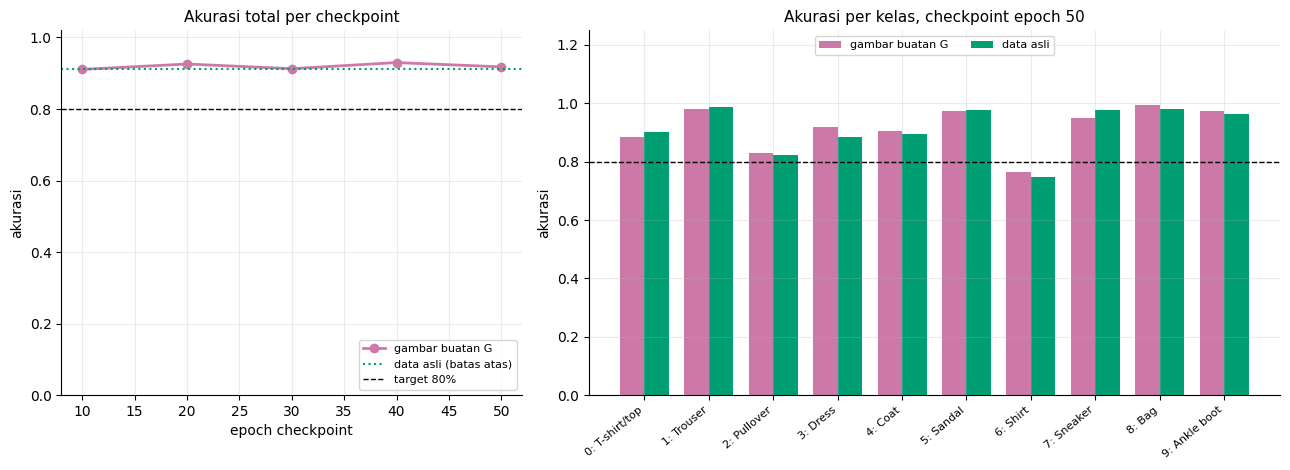

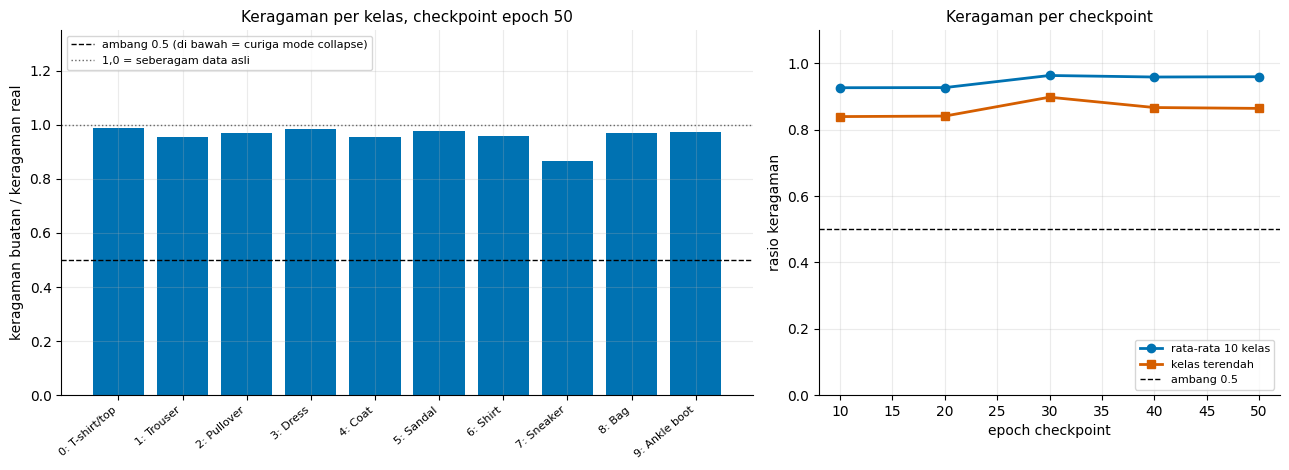

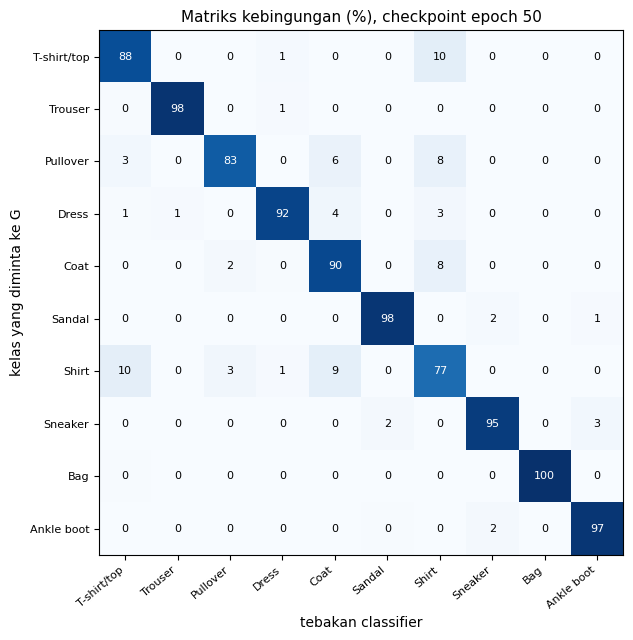

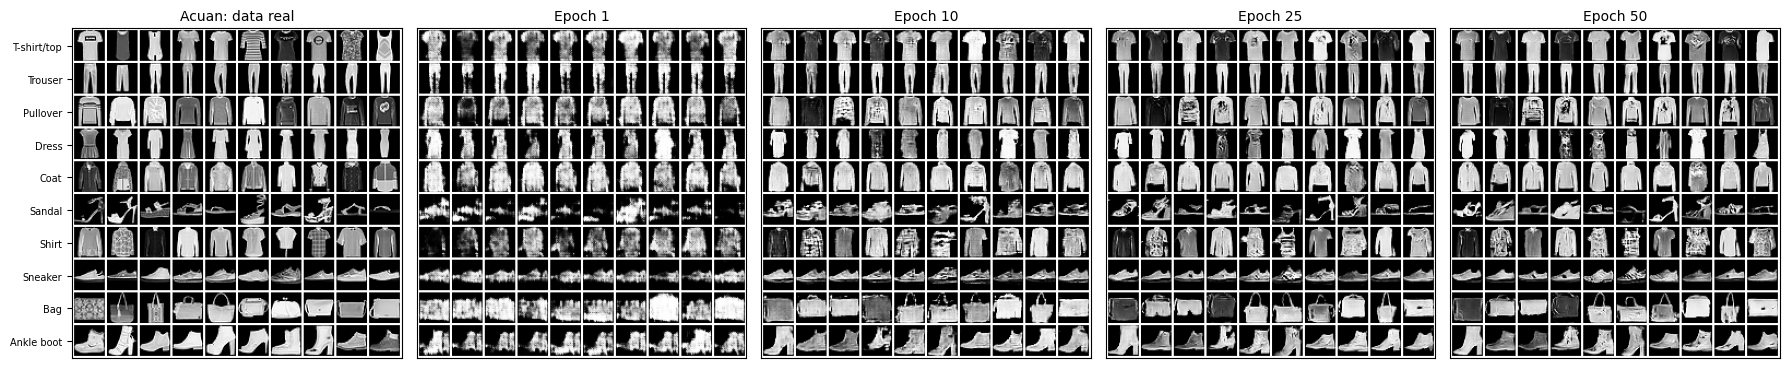


Diagnosis otomatis (ambang dari cetak biru bagian 6, 7, 9):
pemeriksaan                                                          nilai                    ambang  status
------------------------------------------------------------------------------------------------------------
L_D tidak terlalu rendah                                             0.902                    >= 0.6  OK
L_G tidak melonjak                                                   1.747                    <= 3.0  OK
D terlalu yakin (D(real)>=0,9 dan D(fake)<=0,1)           0 epoch berturut                       < 3  OK
D(real), D(fake) di pita sehat                               0.637 / 0.263   (0.6, 0.8) / (0.2, 0.4)  OK
Akurasi classifier pada gambar buatan                               91.78%                    >= 80%  OK
Keragaman terendah (rasio buatan/real)                      0.86 (Sneaker)                    >= 0.5  OK

Grafik tersimpan di: /content/drive/MyDrive/cgan_fashion_mnist/runs/B_lr_d_1e-4/figures


In [25]:
# Run B: lr D diturunkan ke 1e-4 (lr G tetap 2e-4). Perkiraan ±15 menit di T4 + evaluasi kurang dari 1 menit.
# Jalankan SETELAH run A selesai; CFG sudah otomatis kembali ke baseline sehingga run ini tidak membawa perubahan dari A.
dirs_B = run_ablation(**EXPERIMENTS["B"], clf=clf, ref=ref)

run                  epoch   akurasi  rasio kergm.     L_D     L_G  D(real)  D(fake)    W/P
-------------------------------------------------------------------------------------------
baseline                50    92.33%          0.92   0.718   2.550    0.725    0.175    0/1
A: dropout D 0.3        50    93.14%          0.85   1.153   1.382    0.560    0.339    0/1
B: lr D 1e-4            50    91.78%          0.86   0.902   1.747    0.637    0.263    0/0
akurasi & rasio keragaman terendah: checkpoint terakhir. L_D, L_G, D(real), D(fake): rata-rata 5 epoch terakhir. W/P: jumlah pemeriksaan WASPADA/PERHATIAN pada diagnosis otomatis.

Selisih terhadap baseline:
  A: dropout D 0.3     akurasi +0.81 pp (batas 2 x galat baku = 0.73 pp: di luar kebisingan sampling) | rasio min -0.07 | L_D +0.435 | L_G -1.168 | D(real) -0.165 | D(fake) +0.164
  B: lr D 1e-4         akurasi -0.55 pp (batas 2 x galat baku = 0.76 pp: di dalam kebisingan sampling) | rasio min -0.05 | L_D +0.184 | L_G -0.802 | D(r

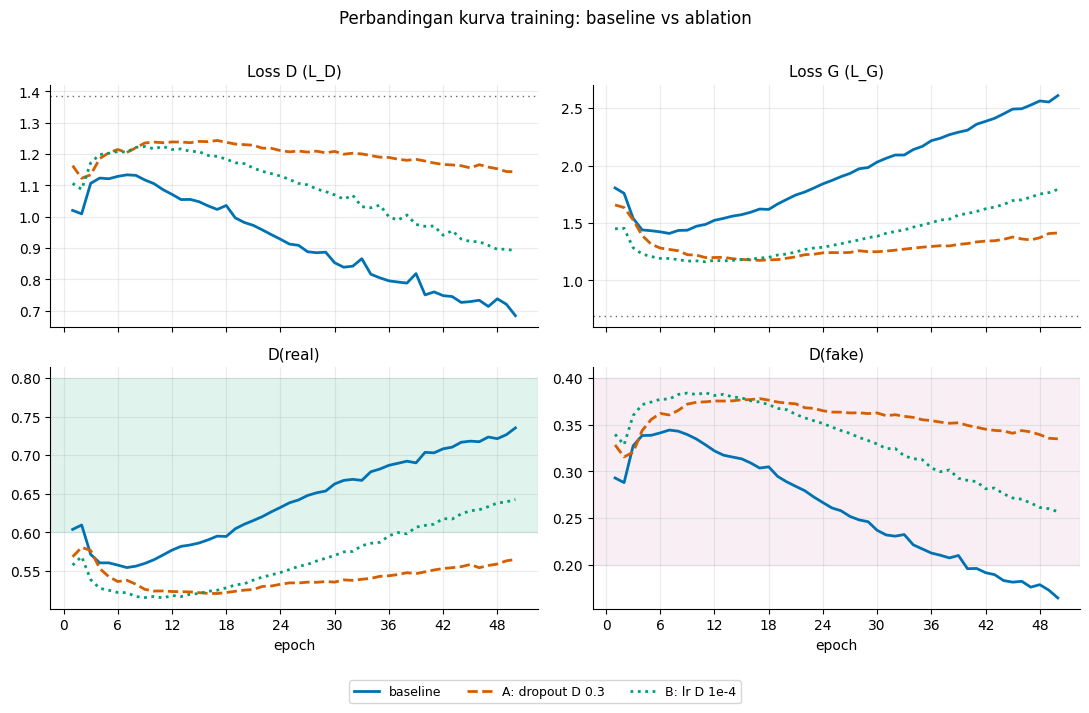

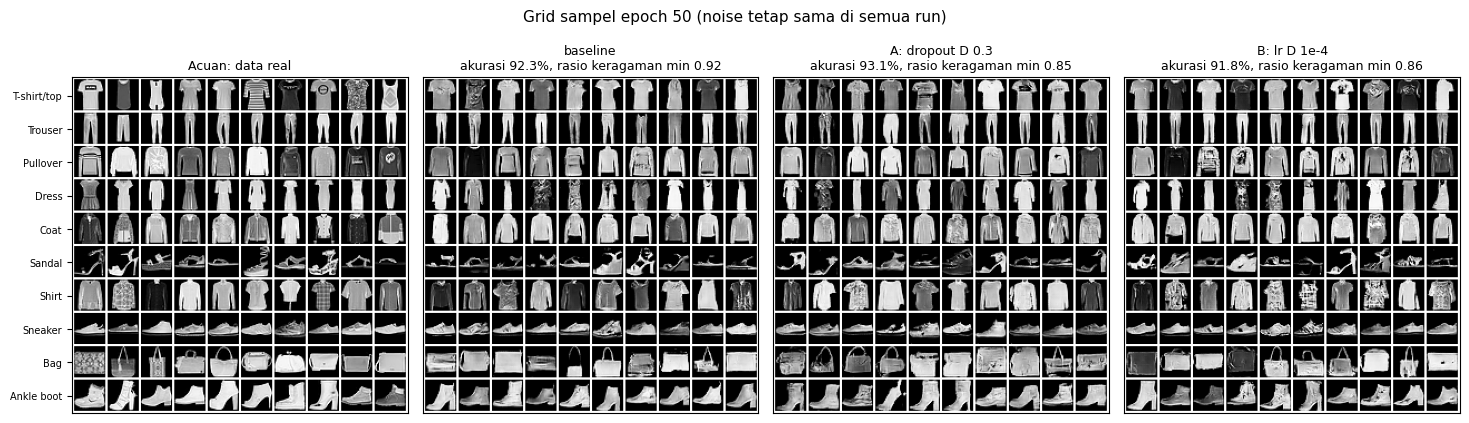


Tabel (CSV) dan grafik tersimpan di: /content/drive/MyDrive/cgan_fashion_mnist/ablation


In [26]:
# 8.5 Perbandingan baseline vs A vs B: tabel, kurva training, dan grid epoch 50 berdampingan (dari log dan PNG).
# Run yang belum dijalankan dilewati; minimal baseline + satu run ablation.
rows = compare_runs()          # CSV dan grafik tersimpan di <folder keluaran>/ablation/

In [27]:
# 8.6 (opsional) Cek dugaan "gambar buatan lebih prototipikal": keyakinan classifier pada gambar real vs buatan (baseline, epoch 50).
conf = compare_confidence(clf)

Keyakinan classifier (probabilitas tertinggi), checkpoint epoch 50
kelas                 real    buatan
------------------------------------
0: T-shirt/top       0.872     0.872
1: Trouser           0.986     0.988
2: Pullover          0.821     0.825
3: Dress             0.886     0.889
4: Coat              0.872     0.861
5: Sandal            0.977     0.976
6: Shirt             0.806     0.786
7: Sneaker           0.972     0.966
8: Bag               0.979     0.977
9: Ankle boot        0.973     0.984
------------------------------------
rata-rata            0.914     0.912
